## TỔNG QUAN
### Mục tiêu

Xác định và đo lượng các yếu tố tác động đến mức độ hài lòng của khán giả đối với phim, từ đó trả lời câu hỏi: "Yếu tố nào quan trọng nhất? Ảnh hưởng bao nhiêu? Có khác biệt giữa các nhóm không?"

### Output cuối cùng
Bảng xếp hạng yếu tố quan trọng nhất (Top 10-15)
Biểu đồ thể hiện mức độ ảnh hưởng của từng yếu tố
Insights về sự khác biệt giữa các segments
Khuyến nghị cho nhà sản xuất/platform

In [328]:
import pandas as pd
import numpy as np
import re
import json
import ast
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score, accuracy_score

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor

import xgboost as xgb
import shap
from sklearn.metrics import mean_squared_error


In [329]:
warnings.filterwarnings('ignore')

# --- 1. ĐỊNH NGHĨA HÀM XỬ LÝ ---
def clean_movielens_title(text):
    return re.sub(r'\s*\(\d{4}\)$', '', str(text)).lower().strip()

def clean_tmdb_title(text):
    return str(text).lower().strip()

def get_director(text):
    try:
        data = ast.literal_eval(text)
        for x in data:
            if x['job'] == 'Director': return x['name']
        return np.nan
    except: return np.nan

def get_top_actors(text):
    try:
        data = ast.literal_eval(text)
        return [x['name'] for x in data[:3]]
    except: return []

### Tổng quan về bộ dữ liệu TMDB và Movielens

#### Bộ dữ liệu TMDB (Đặc điểm phim)

- Yếu tố định lượng (Numerical):
    - budget – Ngân sách sản xuất phim
    - revenue – Doanh thu phòng vé
    - runtime – Thời lượng phim (phút)
    - popularity – Chỉ số độ phổ biến trên TMDB
    - vote_count – Số lượng lượt đánh giá
    - vote_average - Điểm trung bình TMDB
    - vote_average – Điểm đánh giá trung bình trên TMDB

- Yếu tố định tính (Categorical):
    - genres (JSON) – Danh sách thể loại phim (Action, Drama, Comedy, …)
    - production_companies (JSON) – Các hãng sản xuất
    - production_countries (JSON) – Quốc gia sản xuất
    - original_language – Ngôn ngữ gốc của phim
    - status – Trạng thái phát hành (Released, Post Production, …)

- Yếu tố mô tả nội dung:
    - overview – Tóm tắt nội dung phim
    - tagline – Khẩu hiệu phim
    - keywords (JSON) – Tập từ khóa mô tả nội dung

- Yếu tố nhân sự:
    - cast (JSON) – Danh sách diễn viên
    - crew (JSON) – Danh sách ê-kíp sản xuất (đạo diễn, biên kịch, …)

- Biến dẫn xuất / biến xử lý thêm (Feature Engineering):
    - release_year – Năm phát hành (trích từ release_date)
    - ROI = revenue / budget – Tỷ suất lợi nhuận (đại diện cho mức độ thành công thương mại)
    - num_genres – Số lượng thể loại của mỗi phim
    - num_keywords – Số lượng từ khóa
    - cast_size – Số lượng diễn viên tham gia
    - crew_size – Quy mô ê-kíp sản xuất
    - is_franchise / sequel – Biến nhị phân xác định phim có thuộc chuỗi/phần tiếp theo hay không


In [330]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB ---
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

tmdb_cred.columns = ['movie_id', 'title', 'cast', 'crew']
tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})


In [331]:
print("\n--- Sample TMDB Credits ---")
tmdb_cred.head(3)


--- Sample TMDB Credits ---


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."


In [332]:
print("\n--- Sample TMDB Movies ---")
tmdb_mov.head(3)


--- Sample TMDB Movies ---


,budget,genres,homepage,movie_id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466


In [333]:
# Đổi tên cột title của credits thành 'tittle_cr' để không trùng với 'title' của bảng movies
tmdb_cred.columns = ['movie_id', 'tittle_cr', 'cast', 'crew'] 

tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})

# Merge nội bộ TMDB
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

print(f"Loaded & Merged TMDB: {tmdb_full.shape}")

Loaded & Merged TMDB: (4803, 23)


In [334]:
tmdb_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   movie_id              4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

#### Bộ dữ liệu Movielens (Hàng vi người dùng)

Biến phụ thuộc (Target):
    - rating - Điểm đánh giá (0 - 5)

- Yếu tố người dùng:
    - age - Tuổi người dùng
    - gender - Giới tính
    - occupation - Nghề nghiệp
    - user_avg_rating - Điểm trung bình của user

- Yếu tố phim (từ MovieLens)
    - genres – Thể loại phim (có thể đa thể loại)

- Yếu tố tương tác:
    - timestamp - Thời điểm đánh giá

- Biến tổng hợp theo người dùng & phim
    - Hành vi người dùng
        - rating_count_per_user – Tổng số phim mà người dùng đã đánh giá
        - user_avg_rating – Điểm đánh giá trung bình của người dùng

    - Mức độ tương tác của phim
        - total_ratings – Tổng số lượt đánh giá của mỗi phim
        - rating_std – Độ lệch chuẩn điểm đánh giá (mức độ phân hóa ý kiến khán giả)

In [335]:
# --- 2. TẢI DỮ LIỆU ---
print("Đang tải dữ liệu...")
u_cols = ['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code']
m_cols = ['MovieID', 'Title', 'Genres']
r_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']

users = pd.read_csv('datasets/movie_len_1M/users.dat', sep='::', names=u_cols, encoding='latin-1', engine='python')
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=m_cols, encoding='latin-1', engine='python')
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=r_cols, encoding='latin-1', engine='python')

Đang tải dữ liệu...


In [336]:
# --- 3. HIỂN THỊ DỮ LIỆU MẪU ĐỂ KIỂM TRA ---

print("\n--- Sample Users ---")
users.head(3)


--- Sample Users ---


,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117


In [337]:
print("\n--- Sample Movies ---")
movies.head(3)


--- Sample Movies ---


,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


In [338]:
print("\n--- Sample Ratings ---")
ratings.head(3)


--- Sample Ratings ---


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968


In [339]:
# --- TÍNH ĐIỂM TRUNG BÌNH (AVG_RATING) ---
print("Đang tính toán điểm trung bình cho từng phim...")
movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
movie_targets.columns = ['MovieID', 'avg_rating']

Đang tính toán điểm trung bình cho từng phim...


In [340]:
print("\n--- Sample Targets Movielens ---")
movie_targets.head(3)


--- Sample Targets Movielens ---


,MovieID,avg_rating
0,1,4.146846
1,2,3.201141
2,3,3.016736


## Tiền xử lý dữ liệu (Data Preprocessing)

Sau khi gộp bảng Movies và Credits, một số biến trong TMDB vẫn ở dạng JSON 
(danh sách các đối tượng).

In [341]:
def json_to_pipe(x, key='name'):
    """
    Chuyển JSON (list of dict) thành chuỗi 'a|b|c'
    """
    if pd.isna(x):
        return ''
    try:
        data = ast.literal_eval(x)
        if isinstance(data, list):
            return '|'.join([item[key] for item in data if key in item])
        return ''
    except:
        return ''

In [342]:
# Kiểm tra xem cột title có tồn tại không
if 'title' not in tmdb_full.columns:
    # Trường hợp file gốc dùng 'original_title', ta tạo lại cột title
    if 'original_title' in tmdb_full.columns:
        tmdb_full['title'] = tmdb_full['original_title']

print(f"Cột trong TMDB Full: {list(tmdb_full.columns)}") 
# Bây giờ chắc chắn đã có cột 'title'

Cột trong TMDB Full: ['budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew']


In [343]:
# --- 4. MERGE METADATA ---
print("Đang xử lý Metadata phim...")

# Tạo khóa nối
movies['title_join'] = movies['Title'].apply(clean_movielens_title)
tmdb_full['title_join'] = tmdb_full['title'].apply(clean_tmdb_title)

# Ghép Movies gốc với TMDB
movies_meta = pd.merge(movies, tmdb_full, on='title_join', how='inner')

# Ghép thêm cột avg_rating (từ bảng movie_targets đã tạo ở bước trước)
movies_meta = pd.merge(movies_meta, movie_targets, on='MovieID', how='inner')


Đang xử lý Metadata phim...


### Trích xuất đặc trưng (Feature Selection)

In [344]:
# Trích xuất Director, Actors, Year
movies_meta['director'] = movies_meta['crew'].apply(get_director)
movies_meta['actors_temp'] = movies_meta['cast'].apply(get_top_actors)
actors_df = movies_meta['actors_temp'].apply(pd.Series).iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']
movies_meta = pd.concat([movies_meta, actors_df], axis=1)
movies_meta['release_year'] = movies_meta['Title'].str.extract(r'\((\d{4})\)$').astype(float)

# Chọn lọc các cột metadata????
cols_meta = [
    'MovieID', 'Title', 'Genres', 'release_year', 'avg_rating', 
    'director', 'actor_1', 'actor_2', 'actor_3',
    'budget', 'revenue', 'vote_average', 'vote_count', 'popularity', 'runtime'
]
movies_final_meta = movies_meta[cols_meta]

movies_final_meta.head(5)

,MovieID,Title,Genres,release_year,avg_rating,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,popularity,runtime
0,1,Toy Story (1995),Animation|Children's|Comedy,1995.0,4.146846,John Lasseter,Tom Hanks,Tim Allen,Don Rickles,30000000,373554033,7.7,5269,73.640445,81.0
1,10,GoldenEye (1995),Action|Adventure|Thriller,1995.0,3.540541,Martin Campbell,Pierce Brosnan,Sean Bean,Izabella Scorupco,58000000,352194034,6.6,1174,59.824565,130.0
2,14,Nixon (1995),Drama,1995.0,3.542484,Oliver Stone,Anthony Hopkins,Joan Allen,Powers Boothe,44000000,13681765,7.1,71,3.770161,192.0
3,15,Cutthroat Island (1995),Action|Adventure|Romance,1995.0,2.458904,Renny Harlin,Geena Davis,Matthew Modine,Frank Langella,98000000,10017322,5.7,136,7.029308,119.0
4,16,Casino (1995),Drama|Thriller,1995.0,3.793255,Martin Scorsese,Robert De Niro,Sharon Stone,Joe Pesci,52000000,116112375,7.8,1307,40.066880,178.0


In [345]:
# --- 5. TẠO DATAFRAME CUỐI CÙNG ---
print("Đang ghép vào bảng Ratings gốc...")
df_final = pd.merge(ratings, movies_final_meta, on='MovieID', how='inner')

print("-" * 30)
print(f"Kích thước cuối cùng: {df_final.shape}")
print("5 dòng đầu tiên:")
# print(df_final[['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average']].head())
df_final.head(3)

Đang ghép vào bảng Ratings gốc...
------------------------------
Kích thước cuối cùng: (450575, 18)
5 dòng đầu tiên:


,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,avg_rating,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,popularity,runtime
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975.0,4.390725,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,127.525581,133.0
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964.0,4.154088,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,20.786616,170.0
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000.0,3.863878,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,30.347332,131.0


### Tích hợp dữ liệu (Data Integration)

In [346]:
# --- TỐI ƯU HÓA TRƯỚC KHI MERGE ---

# 1. Chọn lọc các cột cần thiết từ bảng phim (Metadata)
# Chúng ta chỉ giữ lại những thông tin có giá trị phân tích
cols_to_keep = [
    'MovieID', 'Title',             # Định danh phim
    'Genres', 'release_year',       # Thông tin cơ bản
    'director', 'actor_1', 'actor_2', 'actor_3', # Ekip làm phim
    'budget', 'revenue',            # Tài chính
    'vote_average', 'vote_count',   # Đánh giá từ TMDB
    'avg_rating',                    # Đánh giá trung bình từ MovieLens (Đã tính ở bước trước)
    'runtime', 
    'popularity'
]

# Lọc để chỉ lấy các cột thực sự tồn tại trong movies_merged (tránh lỗi nếu thiếu cột nào đó)
existing_cols = [c for c in cols_to_keep if c in movies_final_meta.columns]
movies_lean = movies_final_meta[existing_cols]


In [347]:
# 2. Thực hiện Merge cuối cùng (Big Merge)
# Ghép bảng Ratings (1 triệu dòng) với bảng Metadata phim đã lọc gọn
# Dùng 'inner' để chỉ giữ lại các rating của những phim ĐÃ CÓ thông tin từ TMDB
print("Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...")
full_data = pd.merge(ratings, movies_lean, on='MovieID', how='inner')

Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...


### Chuẩn hóa

In [348]:
# Ta sẽ tính điểm trung bình của từng Đạo diễn/Diễn viên và gán lại cho họ.

# 1. Tạo biến "Sức mạnh Đạo diễn" (Director Power)
# Dùng transform để gán ngược lại vào từng dòng dữ liệu
full_data['director_power'] = full_data.groupby('director')['Rating'].transform('mean')

# 2. Tạo biến "Sức mạnh Diễn viên" (Actor Power)
full_data['actor_power'] = full_data.groupby('actor_1')['Rating'].transform('mean')

In [349]:

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print(f"Tổng số lượt đánh giá gốc (Ratings): {ratings.shape[0]}")
print(f"Tổng số dòng dữ liệu sau khi merge (Full Data): {full_data.shape[0]}")
print(f"-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): {ratings.shape[0] - full_data.shape[0]}")
print("-" * 30)

# Xem 5 dòng dữ liệu hoàn chỉnh để đảm bảo bạn có đủ 3 loại điểm số
# 1. Rating: Điểm do người dùng này chấm
# 2. avg_rating: Điểm trung bình của phim trên MovieLens
# 3. vote_average: Điểm trung bình của phim trên TMDB
print("5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):")
cols_check = ['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average', 'director', 'director_power', 'actor_1', 'actor_power']
full_data[cols_check].head()

------------------------------
Tổng số lượt đánh giá gốc (Ratings): 1000209
Tổng số dòng dữ liệu sau khi merge (Full Data): 450575
-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): 549634
------------------------------
5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):


,UserID,Title,Rating,avg_rating,vote_average,director,director_power,actor_1,actor_power
0,1,One Flew Over the Cuckoo's Nest (1975),5,4.390725,8.2,Miloš Forman,4.143682,Jack Nicholson,3.757172
1,1,My Fair Lady (1964),3,4.154088,7.4,George Cukor,4.154088,Audrey Hepburn,4.154088
2,1,Erin Brockovich (2000),4,3.863878,7.1,Steven Soderbergh,3.791741,Julia Roberts,3.584800
3,1,Ben-Hur (1959),5,4.110795,5.3,Timur Bekmambetov,4.110795,Jack Huston,4.110795
4,1,Snow White and the Seven Dwarfs (1937),4,3.845347,6.9,David Hand,3.842266,Adriana Caselotti,3.845347


In [350]:
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450575 entries, 0 to 450574
Data columns (total 20 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   UserID          450575 non-null  int64  
 1   MovieID         450575 non-null  int64  
 2   Rating          450575 non-null  int64  
 3   Timestamp       450575 non-null  int64  
 4   Title           450575 non-null  object 
 5   Genres          450575 non-null  object 
 6   release_year    450575 non-null  float64
 7   director        450535 non-null  object 
 8   actor_1         450535 non-null  object 
 9   actor_2         450535 non-null  object 
 10  actor_3         450535 non-null  object 
 11  budget          450575 non-null  int64  
 12  revenue         450575 non-null  int64  
 13  vote_average    450575 non-null  float64
 14  vote_count      450575 non-null  int64  
 15  avg_rating      450575 non-null  float64
 16  runtime         450575 non-null  float64
 17  popularity

In [351]:
full_data.head()

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,runtime,popularity,director_power,actor_power
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975.0,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,133.0,127.525581,4.143682,3.757172
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,170.0,20.786616,4.154088,4.154088
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000.0,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,131.0,30.347332,3.791741,3.584800
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,125.0,29.608322,4.110795,4.110795
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,83.0,80.171283,3.842266,3.845347


### Làm sạch dữ liệu (Data Cleaning)

In [352]:
# Kiểm tra dữ liệu bị thiếu (Missing values)
full_data.isnull().sum()

UserID             0
MovieID            0
Rating             0
Timestamp          0
Title              0
Genres             0
release_year       0
director          40
actor_1           40
actor_2           40
actor_3           40
budget             0
revenue            0
vote_average       0
vote_count         0
avg_rating         0
runtime            0
popularity         0
director_power    40
actor_power       40
dtype: int64

In [353]:
# XỬ LÝ DỮ LIỆU BỊ THIẾU (XÓA DÒNG)
# inplace=True sẽ thay đổi trực tiếp trên dataframe hiện tại
full_data.dropna(subset=['director', 'actor_1'], inplace=True)

print(f"Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: {full_data.shape}\n Số dòng bị thiếu: \n{full_data.isnull().sum()}")

Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: (450495, 20)
 Số dòng bị thiếu: 
UserID            0
MovieID           0
Rating            0
Timestamp         0
Title             0
Genres            0
release_year      0
director          0
actor_1           0
actor_2           0
actor_3           0
budget            0
revenue           0
vote_average      0
vote_count        0
avg_rating        0
runtime           0
popularity        0
director_power    0
actor_power       0
dtype: int64


In [354]:
# Kiểm tra dữ liệu bị trùng lặp
full_data.duplicated().sum()

0

In [355]:
# --- LỌC DỮ LIỆU CHẤT LƯỢNG CAO (CLEANING DATA) ---

print(f"Số lượng dòng dữ liệu ban đầu: {full_data.shape[0]}")

# Áp dụng 3 điều kiện lọc cùng lúc:
# 1. vote_count > 50: Bỏ qua các phim quá ít người quan tâm trên TMDB (tránh nhiễu)
# 2. budget > 10000: Bỏ qua phim không có số liệu ngân sách hoặc ngân sách quá thấp (lỗi nhập liệu)
# 3. revenue > 10000: Bỏ qua phim không có số liệu doanh thu

full_data = full_data[
    (full_data['vote_count'] > 50) & 
    (full_data['budget'] > 10000) & 
    (full_data['revenue'] > 10000)
]

# --- KIỂM TRA KẾT QUẢ SAU KHI LỌC ---
print("-" * 30)
print(f"Số lượng dòng sau khi lọc: {full_data.shape[0]}")
print(f"-> Đã loại bỏ: {full_data.shape[0] - full_data.shape[0]} dòng dữ liệu rác/thiếu thông tin.")

# Xem thống kê nhanh về tài chính của tập dữ liệu sạch
print("\nThống kê dữ liệu tài chính sau khi lọc:")
print(full_data[['budget', 'revenue', 'vote_count']].describe().apply(lambda s: s.apply('{0:.2f}'.format)))

Số lượng dòng dữ liệu ban đầu: 450495
------------------------------
Số lượng dòng sau khi lọc: 397975
-> Đã loại bỏ: 0 dòng dữ liệu rác/thiếu thông tin.

Thống kê dữ liệu tài chính sau khi lọc:
             budget        revenue vote_count
count     397975.00      397975.00  397975.00
mean    37087587.03   180600388.37    1467.37
std     36699190.83   210367425.44    1606.35
min        12000.00      120000.00      52.00
25%     10500000.00    39846344.00     395.00
50%     25000000.00   115101622.00     840.00
75%     55000000.00   254700832.00    1783.00
max    207000000.00  1845034188.00    9413.00


## Khám phá Dữ liệu (EDA - Exploratory Data Analysis)

### Phân tích đơn biến

Câu hỏi cần trả lời:
+ Rating có phân bố chuẩn không? (normal distribution)
+ Có outliers không?
+ Có imbalance trong categorical variables không?

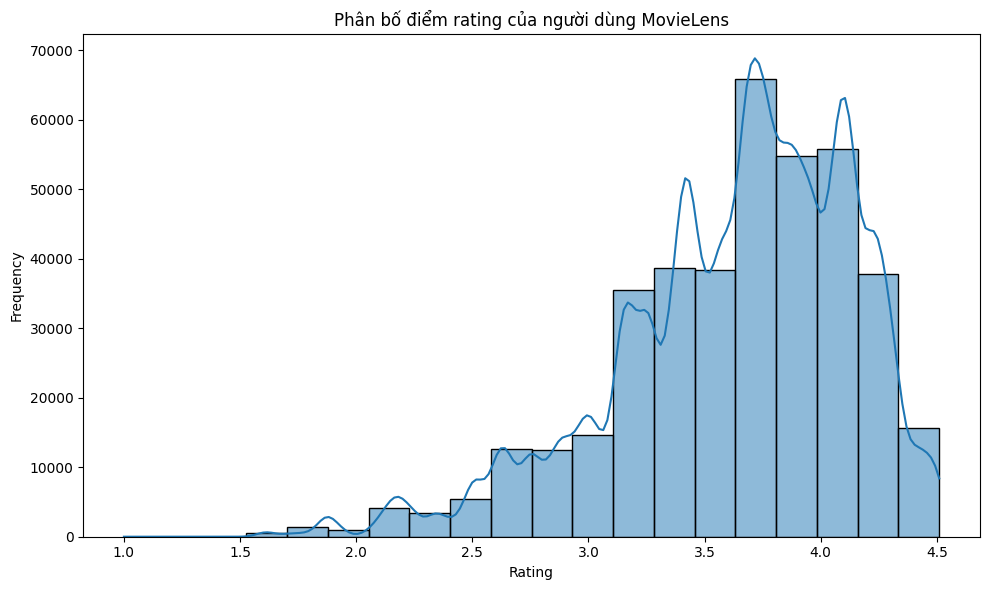

In [356]:
# Phân bố biến mục tiêu
plt.figure(figsize=(10, 6))
sns.histplot(full_data['avg_rating'], bins=20, kde=True)
plt.title('Phân bố điểm rating của người dùng MovieLens')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


Biểu đồ phân bố điểm rating cho thấy dữ liệu lệch trái rõ rệt:

+ Tần suất thấp ở các mức điểm thấp (1.0–2.5) và tăng mạnh ở các mức điểm cao. Phần lớn đánh giá tập trung trong khoảng 3.0–4.5, với các cột vượt 30.000 lượt. Đỉnh cao nhất xuất hiện tại mức 4.0, đạt khoảng 65.000–70.000 lượt, tiếp theo là các đỉnh tại 3.0 và 3.5. Sau mức 4.0, tần suất giảm dần ở 4.5. 

+ Đường cong mật độ bám sát các cột và gợn sóng theo các mức điểm nguyên và bán nguyên, phản ánh xu hướng đánh giá tập trung vào các mốc điểm quen thuộc.

In [357]:
# 2. Thống kê mô tả
print(full_data['Rating'].describe())
print(f"Skewness: {full_data['Rating'].skew():.3f}")
print(f"Kurtosis: {full_data['Rating'].kurtosis():.3f}")


count    397975.000000
mean          3.630100
std           1.106728
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: Rating, dtype: float64
Skewness: -0.591
Kurtosis: -0.292


- Kết quả thống kê mô tả cho thấy điểm rating trung bình của người dùng MovieLens đạt 3.63 trên thang điểm 5. 
Giá trị trung vị và tứ phân vị trên đều bằng 4.0, cho thấy phần lớn các bộ phim được đánh giá ở mức khá đến tốt.

- Phân bố rating có độ lệch trái nhẹ (skewness = -0.591), phản ánh xu hướng người dùng chấm điểm cao nhiều hơn điểm thấp.
Hệ số kurtosis âm (-0.293) cho thấy phân bố có đỉnh thấp và trải rộng hơn so với phân bố chuẩn, không xuất hiện hiện tượng tập trung quá mức quanh giá trị trung bình.

- Nhìn chung, phân bố rating không hoàn toàn tuân theo phân bố chuẩn nhưng không có sự lệch cực đoan, cho phép áp dụng các phương pháp phân tích thống kê và mô hình hóa trong các bước tiếp theo.


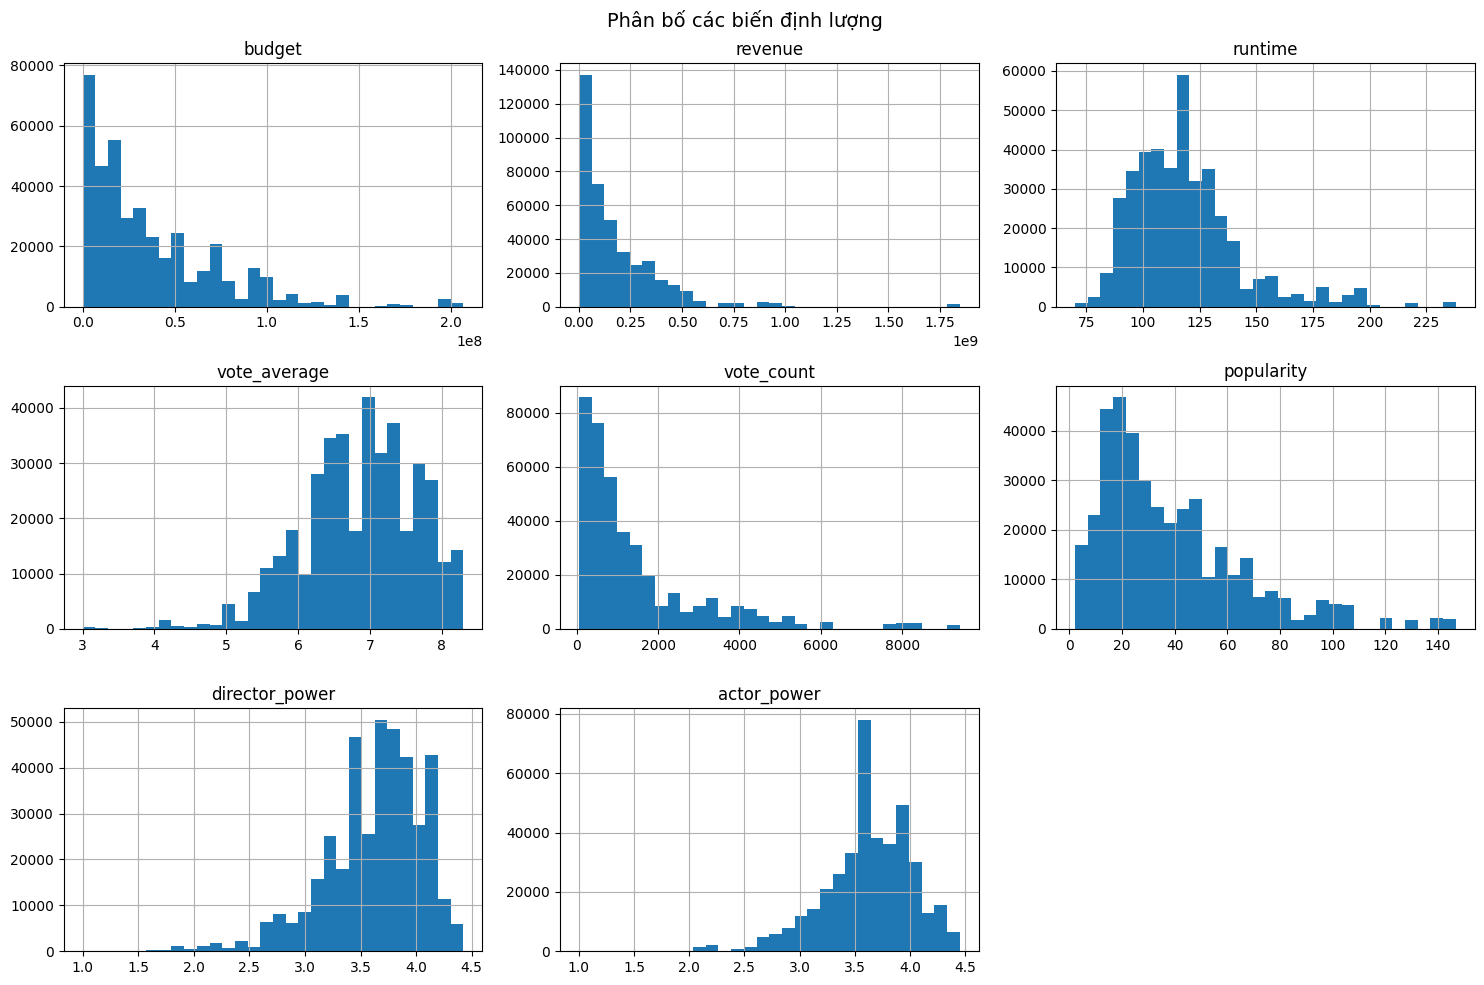

In [358]:
# 3. Phân bố các biến numerical khác
numerical_cols = [
    'budget', 
    'revenue', 
    'runtime', 
    'vote_average', 
    'vote_count',
    'popularity',
    'director_power',
    'actor_power'
]

full_data[numerical_cols].hist(figsize=(15, 10), bins=30)
plt.suptitle('Phân bố các biến định lượng', fontsize=14)
plt.tight_layout()
plt.show()


Nhóm biến lệch phải mạnh (budget, revenue, vote_count, popularity):
Các biến này đều có phân bố lệch phải rõ rệt. Phần lớn phim nằm ở mức thấp đến trung bình, trong khi chỉ một số ít phim bom tấn hoặc rất nổi tiếng có giá trị cực cao, tạo ra đuôi dài. Đây là đặc trưng phổ biến của ngành điện ảnh, phản ánh sự chênh lệch lớn giữa phim đại chúng và số ít tác phẩm dẫn đầu thị trường.

Nhóm biến tập trung và ổn định (runtime):
Thời lượng phim phân bố khá tập trung, gần dạng chuông, chủ yếu trong khoảng 90–130 phút. Điều này cho thấy thời lượng phim điện ảnh tương đối ổn định, chỉ có rất ít phim quá ngắn hoặc quá dài.

Nhóm biến phản ánh cảm nhận người xem (vote_average):
Điểm đánh giá trung bình tập trung nhiều ở khoảng 6–8 điểm, đây là điểm được chấm từ TMDB, cho thấy xu hướng người dùng đánh giá phim khá tích cực. Các mức điểm quá thấp hoặc quá cao xuất hiện ít, phản ánh sự đồng thuận tương đối trong cảm nhận chất lượng phim.

Sự xuất hiện dày đặc của các giá trị ngoại lai (outliers) ở nhóm biến tài chính và mức độ phổ biến chính là minh chứng rõ nét cho phân phối "đuôi dài" (long-tail) đặc thù của ngành công nghiệp điện ảnh. Những giá trị này không phải là nhiễu, mà đại diện cho các bộ phim "bom tấn" nằm tách biệt hoàn toàn so với mặt bằng chung, tạo ra sự chênh lệch cực lớn về quy mô và sức ảnh hưởng. Chính sự hiện diện của những ngoại lai này đã kéo dãn đồ thị về phía bên phải, gây ra hiện tượng lệch phân phối, đòi hỏi các phương pháp xử lý dữ liệu đặc thù để mô hình không bị thiên lệch bởi thiểu số các siêu phẩm này.



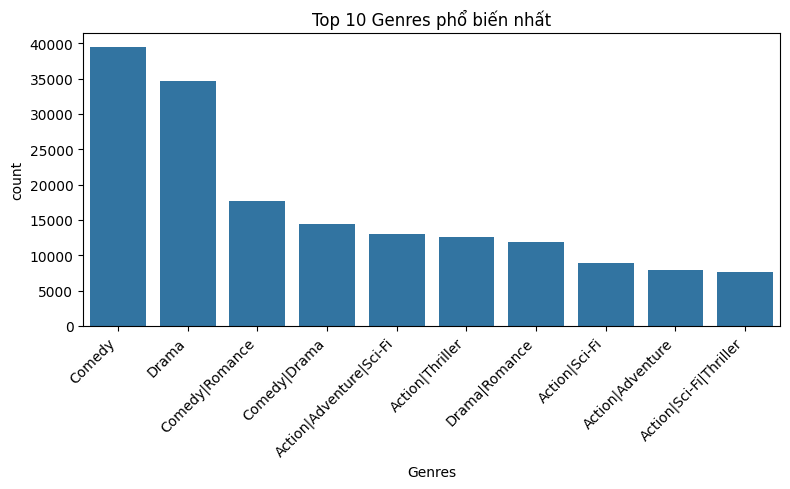

In [359]:
import seaborn as sns
import matplotlib.pyplot as plt

# 4. Tần suất của các biến phân loại
categorical_cols = ['Genres']

for col in categorical_cols:
    top_values = full_data[col].value_counts().head(10).reset_index()
    top_values.columns = [col, 'count']

    plt.figure(figsize=(8, 5))
    sns.barplot(data=top_values, x=col, y='count')
    plt.title(f'Top 10 {col} phổ biến nhất')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

Genres distribution đã xác nhận có tồn tại tình trạng sự mất cân bằng trong biến phân loại (Categorical imbalance). Số lượng phim thuộc thể loại Comedy (gần 40.000) và Drama (gần 35.000) áp đảo hoàn toàn so với các thể loại phức hợp như Action|Sci-Fi|Thriller (chỉ khoảng 7.000). Sự chênh lệch lớn về tần suất xuất hiện giữa các nhóm này chính là biểu hiện rõ nhất của mất cân bằng dữ liệu, điều này sẽ ảnh hưởng lớn nếu dùng Genre làm biến mục tiêu để dự đoán.

### Phân tích hai biến

Insights cần tìm:
+ Biến nào có correlation mạnh với rating?
+ Có non-linear relationships không?

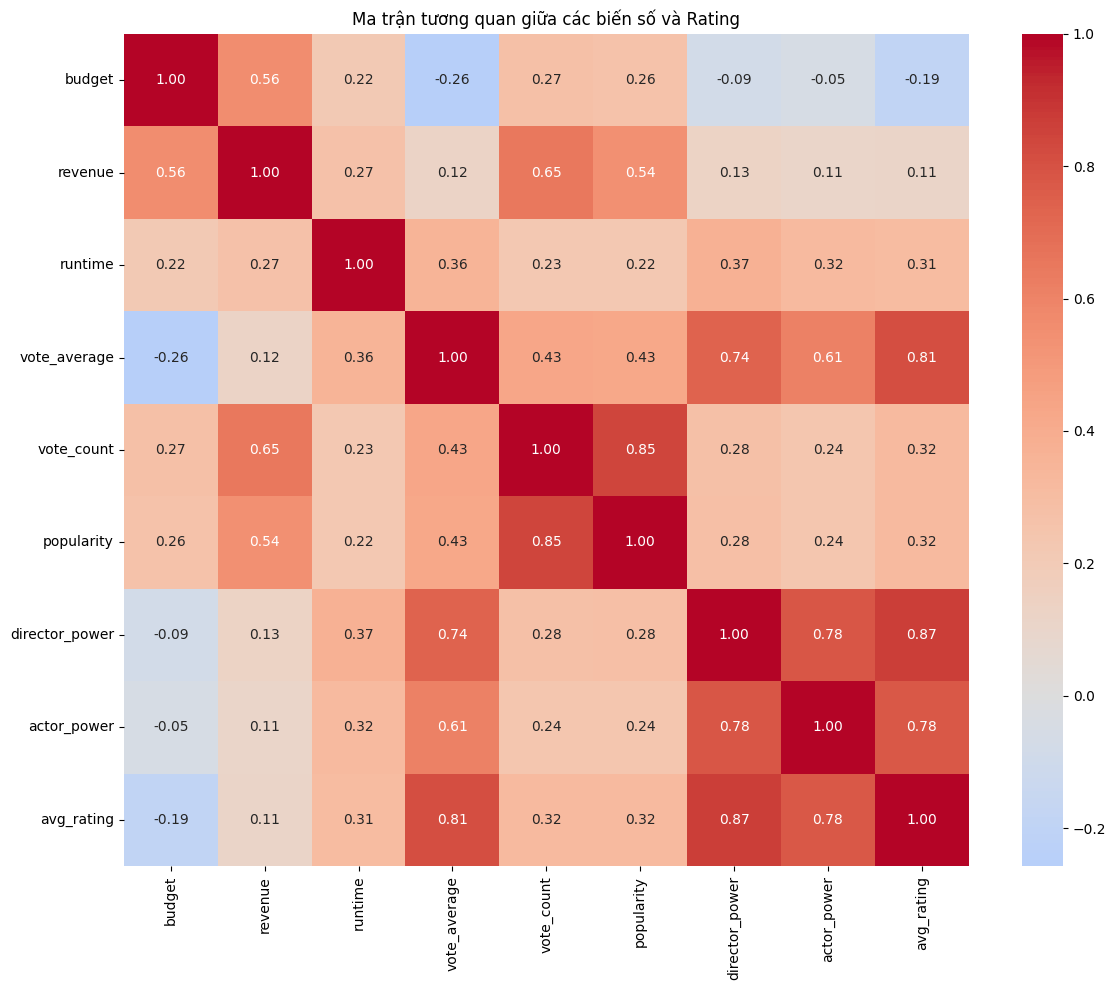

In [360]:
plt.figure(figsize=(12, 10))

corr_cols = numerical_cols + ['avg_rating']
df_movie_scope = full_data.drop_duplicates(subset=['MovieID']).copy()
correlation_matrix = df_movie_scope[corr_cols].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0
)

plt.title('Ma trận tương quan giữa các biến số và Rating')
plt.tight_layout()
plt.show()


Biến số Director Power có hệ số tương quan dương cao nhất (0.87), khẳng định rằng thương hiệu và tài năng của đạo diễn chính là "tấm tem bảo hành" uy tín nhất cho chất lượng phim trên MovieLens, quan trọng hơn rất nhiều so với số tiền đổ vào sản xuất. 

Actor Power cũng ghi nhận mức tương quan rất mạnh (0.78), cho thấy một dàn diễn viên thực lực không chỉ giúp bộ phim thu hút sự chú ý mà còn đóng góp trực tiếp vào giá trị nghệ thuật, tạo nên sự cộng hưởng mạnh mẽ giúp nâng cao điểm số đánh giá cuối cùng.

Mối tương quan cùng chiều cực mạnh (0.81) giữa avg_rating và vote_average, khẳng định rằng đánh giá của người dùng trên MovieLens rất đồng nhất với điểm số đại chúng trên TMDB. 

Điểm số trung bình cũng có mối liên hệ tích cực vừa phải với thời lượng phim (0.31) và số lượt bình chọn (0.32), gợi ý rằng các bộ phim có thời lượng dài hơn (thường là phim có chiều sâu) và được nhiều người quan tâm thường có chất lượng tốt hơn.

Ngược lại, các yếu tố tài chính lại cho thấy mối liên hệ rất yếu, thậm chí là tiêu cực với chất lượng phim:

+ Doanh thu (Revenue) gần như không ảnh hưởng đến điểm số (0.11), trong khi ngân sách (Budget) lại có tương quan âm nhẹ (-0.19). Điều này phản ánh một thực tế thú vị: phim được đầu tư "khủng" chưa chắc đã hay, thậm chí đôi khi ngân sách càng cao thì điểm đánh giá lại càng thấp hơn so với kỳ vọng.



+ Sự phụ thuộc lẫn nhau giữa các biến độc lập, chẳng hạn như phim có doanh thu cao thường đi kèm với lượng tương tác lớn (0.65) và ngân sách lớn (0.56).

Mối tương quan cùng chiều mạnh mẽ đến mức kinh ngạc giữa sức mạnh của đạo diễn, diễn viên với điểm đánh giá đã đảo chiều hoàn toàn tư duy phân tích, khẳng định rằng uy tín của người kể chuyện có sức nặng gấp nhiều lần số tiền họ chi ra.

Điều này buộc chúng ta phải đặt lại vấn đề: Liệu khán giả đang thực sự thưởng thức tác phẩm một cách khách quan, hay họ đang chấm điểm dựa trên "bảo chứng niềm tin" tuyệt đối dành cho những cái tên huyền thoại đứng sau ống kính?

Thực hiện: chia các đạo diễn thành các nhóm (Phân khúc) dựa trên sức mạnh của họ (ví dụ: Vô danh, Triển vọng, Nổi tiếng, Huyền thoại). Sau đó, kiểm tra xem: Khi một đạo diễn "Huyền thoại" làm một bộ phim không quá nổi bật (Popularity thấp) hoặc doanh thu thấp, liệu khán giả có "dám" chấm điểm thấp cho họ không?

Nếu đạo diễn hạng thấp làm phim dở thì bị chấm 1-2 điểm, nhưng đạo diễn "Huyền thoại" làm phim dở vẫn được chấm 3.5 điểm -> Đó chính là "Bảo chứng niềm tin".

Tỷ lệ bị chấm điểm thấp (Rating < 2.5) theo đẳng cấp đạo diễn:
  Director Tier  Flop Rate (%)
0           Low      10.596931
1        Medium       1.108695
2          High       0.184461
3     Legendary       0.000000


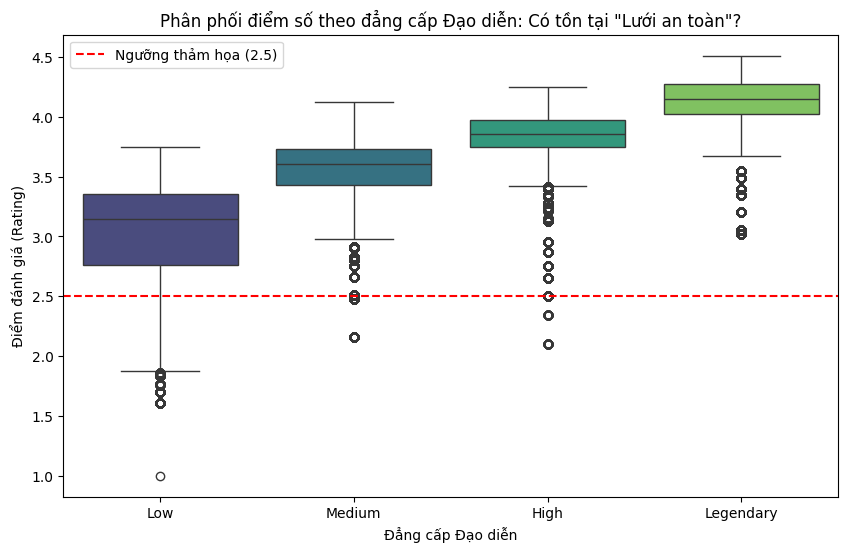

In [361]:
# 1. Phân loại Đạo diễn thành 4 đẳng cấp (Quartiles)
# Low: Vô danh, Medium: Triển vọng, High: Nổi tiếng, Legendary: Huyền thoại
full_data['director_tier'] = pd.qcut(full_data['director_power'], q=4, labels=['Low', 'Medium', 'High', 'Legendary'])

# 2. Tính toán "Tỷ lệ thảm họa" (Flop Rate) cho từng nhóm
# Giả sử phim "thảm họa" là phim có rating < 2.5
flop_threshold = 2.5
flop_analysis = full_data.groupby('director_tier')['avg_rating'].apply(lambda x: (x < flop_threshold).mean() * 100).reset_index()
flop_analysis.columns = ['Director Tier', 'Flop Rate (%)']

print("Tỷ lệ bị chấm điểm thấp (Rating < 2.5) theo đẳng cấp đạo diễn:")
print(flop_analysis)

# 3. Trực quan hóa "Lưới an toàn" (Safety Net) bằng Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x='director_tier', y='avg_rating', data=full_data, palette="viridis")

plt.title('Phân phối điểm số theo đẳng cấp Đạo diễn: Có tồn tại "Lưới an toàn"?')
plt.ylabel('Điểm đánh giá (Rating)')
plt.xlabel('Đẳng cấp Đạo diễn')
plt.axhline(y=2.5, color='r', linestyle='--', label='Ngưỡng thảm họa (2.5)')
plt.legend()
plt.show()



Nhóm Low (Vô danh): Rất nhiều phim của họ rơi tự do xuống dưới vạch đỏ này (các chấm tròn ngoại lai kéo dài xuống tận 1.0). Điều này có nghĩa là khi họ làm phim dở, khán giả sẵn sàng trừng phạt họ bằng những điểm số tệ hại nhất.

Nhóm Legendary (Huyền thoại): Đây là điều thú vị nhất. Toàn bộ hộp và râu (whiskers) của nhóm này nằm cao chót vót. Quan trọng hơn, ngay cả những điểm chấm tròn thấp nhất (đại diện cho các phim "tệ nhất" của họ - outliers) cũng chỉ dừng lại ở mức 3.0, tức là vẫn cao hơn hẳn so với ngưỡng thảm họa.

-> Đạo diễn huyền thoại có một "tấm khiên" vô hình. Dù phim của họ có tệ đến đâu so với tiêu chuẩn của chính họ, khán giả vẫn mặc định chấm mức điểm Khá (3.0) chứ không bao giờ dìm xuống mức Yếu/Kém.

In [362]:
# 4. Phân tích độ lệch chuẩn (Consistency)
# Xem ai ổn định hơn: Người xem có xu hướng chấm điểm "đồng lòng" cho Legendary không?
std_analysis = full_data.groupby('director_tier')['avg_rating'].std().reset_index()
std_analysis.columns = ['Director Tier', 'Rating Std Dev']
print("\nĐộ lệch chuẩn điểm số (Sự nhất quán trong đánh giá):")
print(std_analysis)


Độ lệch chuẩn điểm số (Sự nhất quán trong đánh giá):
  Director Tier  Rating Std Dev
0           Low        0.425808
1        Medium        0.318242
2          High        0.267535
3     Legendary        0.263415


Xu hướng giảm dần: Độ lệch chuẩn (Std Dev) giảm đều đặn từ mức cao nhất 0.425 (Low) xuống mức thấp nhất 0.263 (Legendary).

Ý nghĩa: Trong thống kê, độ lệch chuẩn càng thấp nghĩa là dữ liệu càng ít biến động xung quanh giá trị trung bình.

+ Với nhóm Low (0.425): Khoảng điểm dao động rất rộng, giống như chơi xổ số, rủi ro cao.

+ Với nhóm Legendary (0.263): Điểm số cực kỳ cô đọng và nhất quán. Khán giả có sự đồng thuận cao độ khi đánh giá phim của họ, hiếm khi có sự tranh cãi gay gắt (người khen nức nở, kẻ chê thậm tệ) như các nhóm dưới.

Nếu như nhóm Legendary đại diện cho sự hoàn hảo được mặc định, thì nhóm High lại mang những chỉ số thống kê đầy mâu thuẫn nhưng cực kỳ thú vị. Một mặt, độ lệch chuẩn thấp cho thấy họ đã đạt đến đẳng cấp kiểm soát chất lượng gần như tuyệt đối, thoát ly hoàn toàn khỏi sự phập phù của nhóm Vô danh. Nhưng mặt khác, những điểm dữ liệu "xuyên đáy" vượt qua ngưỡng an toàn lại tố cáo một thực tế tàn nhẫn: dù tài năng đến đâu, họ vẫn chưa đủ quyền lực để khiến khán giả nhắm mắt làm ngơ trước những sai lầm.

Mối tương quan 0.31 giữa thời lượng và điểm số gợi mở giả thuyết rằng khán giả thường ưu ái những tác phẩm dài hơi có chiều sâu hơn là phim giải trí ngắn. Dùng boxplot để kiểm chứng:

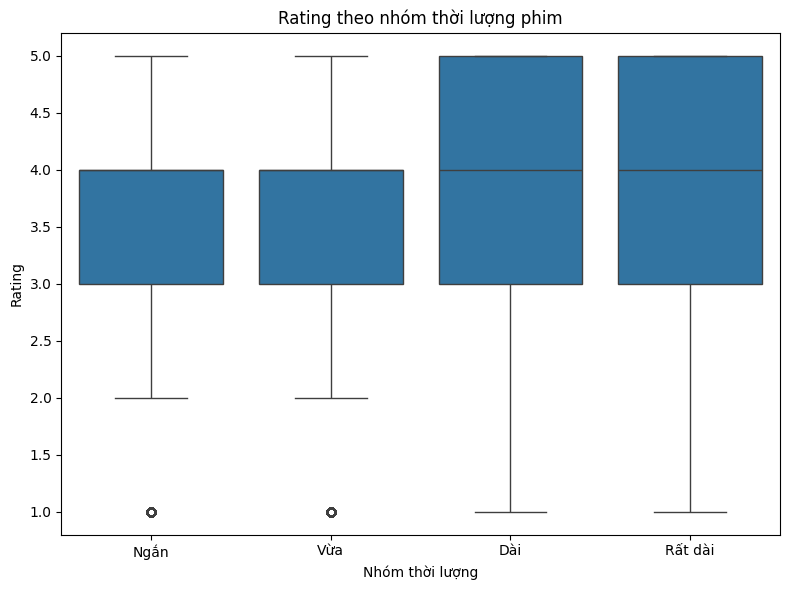

In [363]:
full_data['runtime_group'] = pd.cut(
    full_data['runtime'],
    bins=[0, 90, 120, 150, 300],
    labels=['Ngắn', 'Vừa', 'Dài', 'Rất dài']
)

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=full_data,
    x='runtime_group',
    y='Rating'
)

plt.title('Rating theo nhóm thời lượng phim')
plt.xlabel('Nhóm thời lượng')
plt.ylabel('Rating')
plt.tight_layout()
plt.show()


Nhóm phim ngắn và vừa có trung vị khoảng 3.5, với khoảng phân bố hẹp hơn, cho thấy mức đánh giá tương đối ổn định nhưng không quá cao. Một số ngoại lệ có điểm rất thấp (khoảng 1 sao) xuất hiện ở hai nhóm này.

Trong khi đó, nhóm phim dài và rất dài có trung vị cao hơn, xấp xỉ 4.0, đồng thời độ phân tán lớn hơn, phản ánh sự đa dạng trong đánh giá của người xem. Dù vẫn tồn tại các phim bị chấm điểm thấp, phần lớn phim dài và rất dài có xu hướng nhận đánh giá tích cực hơn.

Nhìn chung, kết quả cho thấy phim có thời lượng dài hơn thường được đánh giá cao hơn, có thể do nội dung được phát triển sâu hơn, dù mức độ rủi ro cũng tăng khi chất lượng không đồng đều.

Bên cạnh đó vẫn còn những yếu tố phân loại, cùng xem xét sự tương quan của nó đến rating trung bình:

+ Độ tuổi:

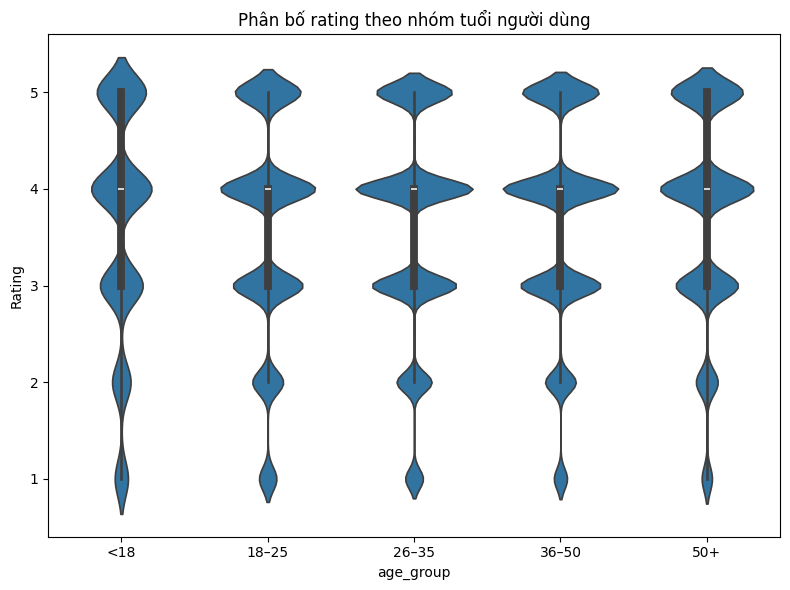

In [364]:
bins = [0, 18, 25, 35, 50, 100]
labels = ['<18', '18–25', '26–35', '36–50', '50+']

users['age_group'] = pd.cut(
    users['Age'],
    bins=bins,
    labels=labels,
    right=False
)

full_data = full_data.merge(
    users[['UserID', 'Gender', 'age_group']],
    on='UserID',
    how='left'
)

plt.figure(figsize=(8, 6))
sns.violinplot(
    data=full_data,
    x='age_group',
    y='Rating'
)

plt.title('Phân bố rating theo nhóm tuổi người dùng')
plt.tight_layout()
plt.show()

Kết quả cho thấy một sự đồng nhất đáng ngạc nhiên trong hành vi chấm điểm giữa tất cả các nhóm tuổi. Dù là nhóm trẻ nhất (<18) hay nhóm lớn tuổi nhất (50+), hình dáng của biểu đồ violin gần như y hệt nhau. Cụ thể, dữ liệu tập trung dày đặc (phần phình to nhất của biểu đồ) ở các mốc điểm 3.0, 4.0 và 5.0, trong khi phần đuôi ở các điểm thấp (1.0, 2.0) rất thon nhỏ. Giá trị trung vị (thể hiện qua chấm trắng hoặc vạch giữa) của tất cả các nhóm đều neo ổn định ở mức 4.0.

-> Tuổi tác không phải là yếu tố phân biệt mạnh đối với việc người dùng đánh giá phim cao hay thấp. Một thiếu niên và một người trung niên trong tập dữ liệu này có xu hướng "hào phóng" như nhau khi chấm điểm.


+ Giới tính:

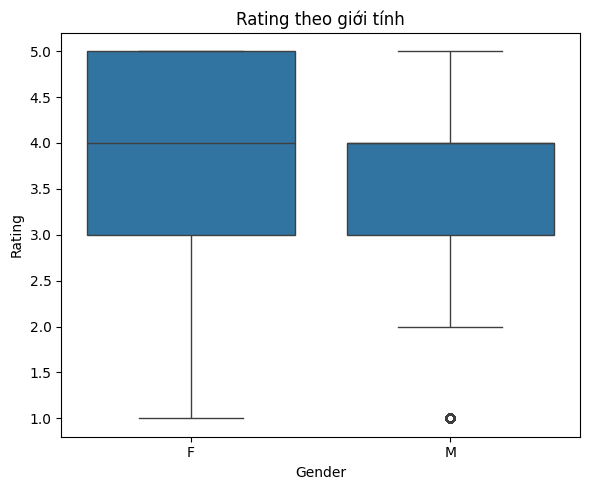

In [365]:
plt.figure(figsize=(6, 5))
sns.boxplot(
    data=full_data,
    x='Gender',
    y='Rating'
)

plt.title('Rating theo giới tính')
plt.tight_layout()
plt.show()



Trung vị (median) của cả hai giới tính đều nằm ở mức 4.0 (đường gạch ngang giữa hộp). Tuy nhiên, sự khác biệt bắt đầu lộ diện ở độ rộng của hộp (Interquartile Range - IQR). Nhóm Nữ (F) có vùng dữ liệu tập trung trải rộng hơn từ 3.0 đến 5.0, trong khi nhóm Nam (M) lại co cụm hẹp hơn chỉ từ 3.0 đến 4.0.

Cho thấy Nữ giới có xu hướng "hào phóng" hoặc phân cực hơn trong việc chấm điểm; họ sẵn sàng cho điểm tuyệt đối (5.0) nhiều hơn, khiến cạnh trên của hộp chạm mốc tối đa. Ngược lại, Nam giới tỏ ra thận trọng và khắt khe hơn, điểm số của họ ổn định cao ở mức khá (3-4 điểm) nhưng ít khi chạm ngưỡng xuất sắc trong nhóm phổ thông (75% dữ liệu nằm dưới mức 4.0). 

-> Mặc dù không quá lớn, nhưng sự khác biệt về phương sai (variance) này cho thấy biến user_gender có giá trị hơn so với age_group. Mô hình có thể học được rằng nếu là user nữ, xác suất xuất hiện điểm 5.0 sẽ nhỉnh hơn so với user nam.

+ Thể loại:

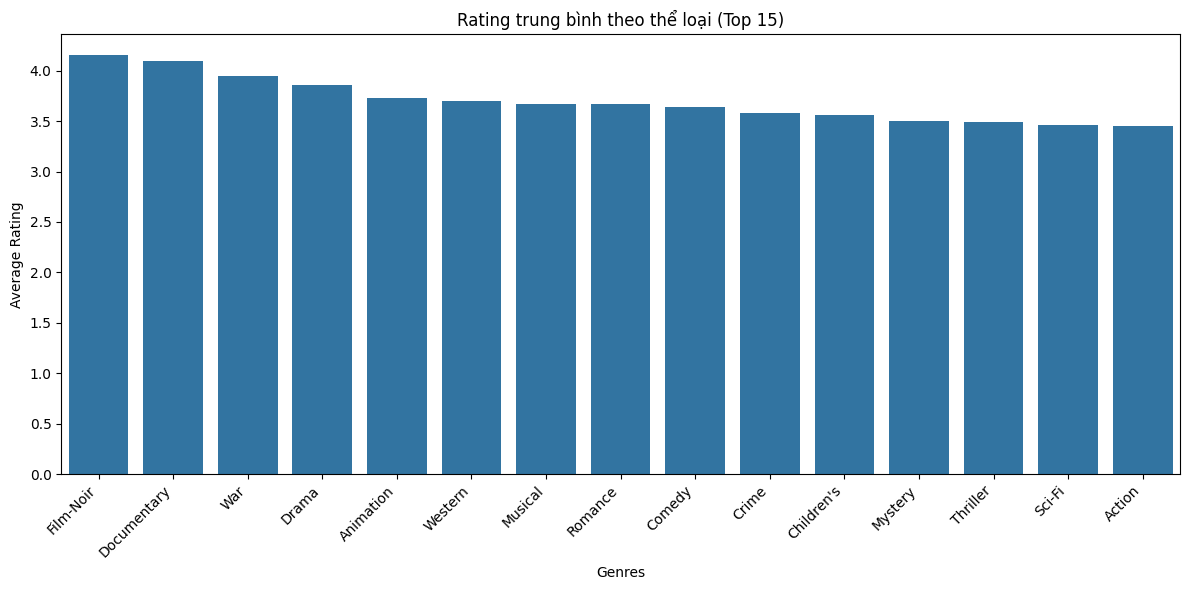

In [366]:
genre_df = full_data[['Genres', 'Rating']].copy()
genre_df['Genres'] = genre_df['Genres'].str.split('|')
genre_df = genre_df.explode('Genres')

genre_rating = genre_df.groupby('Genres')['Rating'].agg(
    mean='mean',
    count='count',
    std='std'
)

genre_rating = genre_rating[genre_rating['count'] > 1000] \
    .sort_values('mean', ascending=False) \
    .head(15)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=genre_rating.index,
    y=genre_rating['mean']
)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Average Rating')
plt.title('Rating trung bình theo thể loại (Top 15)')
plt.tight_layout()
plt.show()


Nhóm thể loại có điểm trung bình cao nhất là Film-Noir và Documentary, đều đạt trên 4.0, cho thấy các phim thuộc nhóm này thường được đánh giá cao về nội dung và chiều sâu. Tiếp theo là War và Drama, với mức rating xấp xỉ từ 3.9 đến 4.0, phản ánh sự đánh giá tích cực của người xem đối với các thể loại giàu tính cảm xúc và giá trị nghệ thuật.

Các thể loại phổ biến như Animation, Western, Musical, Romance và Comedy có rating trung bình dao động quanh 3.6–3.7, thể hiện mức độ hài lòng khá tốt nhưng không nổi trội.

Ở nhóm cuối, Action, Sci-Fi, Thriller và Mystery có rating trung bình thấp hơn, khoảng 3.4–3.5. Điều này cho thấy dù thu hút đông đảo khán giả, các thể loại thiên về giải trí và kỹ xảo thường khó đạt điểm đánh giá cao như những thể loại chú trọng nội dung và thông điệp.

Cho thấy khán giả MovieLens có xu hướng đánh giá khắt khe hơn với các dòng phim thị trường (Action, Sci-Fi) và dành sự trân trọng đặc biệt cho các tác phẩm nghệ thuật hoặc phim tài liệu. Một bộ phim "Film-Noir" ngẫu nhiên có xác suất được đánh giá cao hơn nhiều so với một bộ phim "Action" ngẫu nhiên.

-> Khác với biến độ tuổi (Age Group) gần như phẳng lì, biến Genre cho thấy khả năng phân loại (discriminative power) rất tốt. Việc biết một bộ phim thuộc thể loại Documentary hay Action sẽ thay đổi đáng kể kỳ vọng về điểm số. Do đó, đây chắc chắn là một biến quan trọng (high feature importance) cần được xử lý kỹ (ví dụ: One-Hot Encoding hoặc Target Encoding) để đưa vào mô hình.

Trong heatmap, budget có tương quan âm nhẹ (-0.19) với rating, nhưng điều này không có nghĩa là cứ giảm tiền thì phim sẽ hay. Rất có thể mối quan hệ này mang hình dạng đường cong (curvilinear) hoặc có điểm bão hòa:

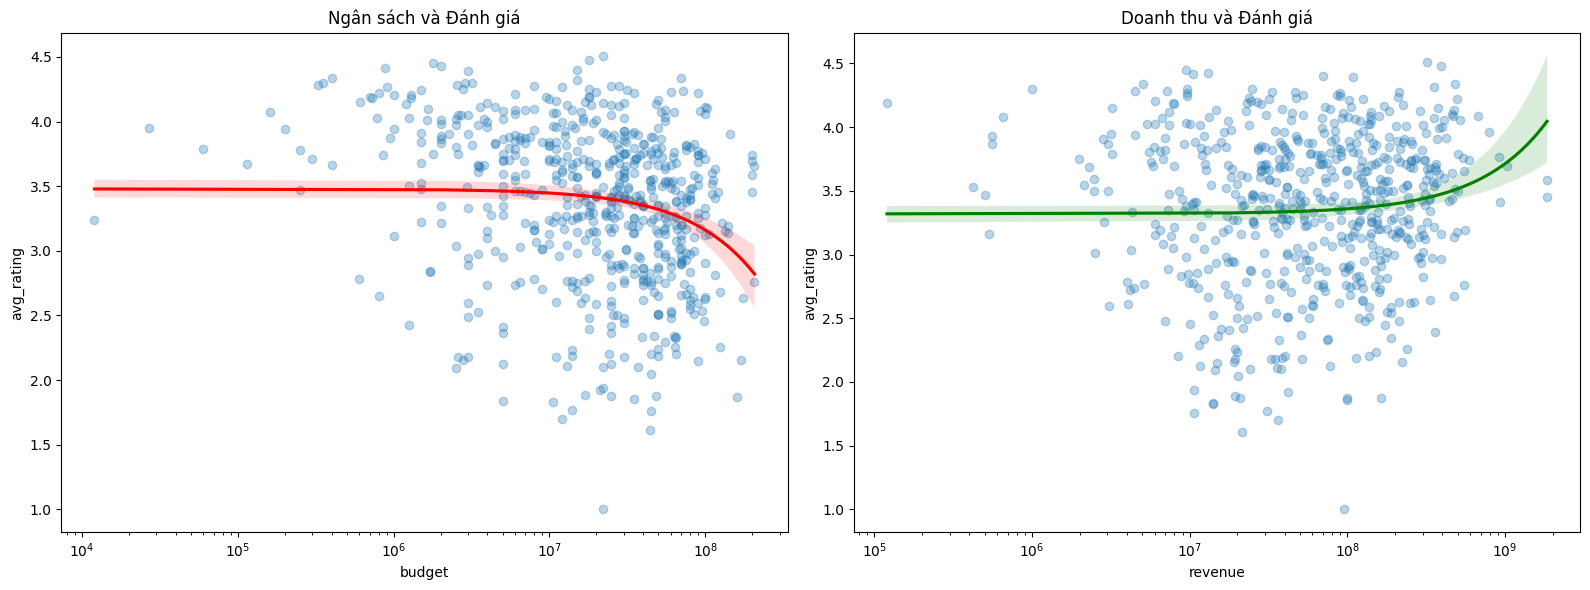

In [367]:
fig, axes = plt.subplots(1,2, figsize=(16,6))

sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[0].set_xscale('log')
axes[0].set_title('Ngân sách và Đánh giá')

sns.regplot(x='revenue', y='avg_rating', data=df_movie_scope, ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'green'})
axes[1].set_xscale('log')
axes[1].set_title('Doanh thu và Đánh giá')

plt.tight_layout()
plt.show()

Hiệu ứng ngược của Ngân sách (Đường đỏ): Xuất hiện xu hướng phi tuyến tính rõ rệt. Điểm đánh giá đi ngang ở mức ngân sách thấp và trung bình, nhưng bắt đầu giảm dần khi ngân sách tăng lên mức cực cao (trên $10^8$). Điều này cho thấy các phim "bom tấn" kinh phí khủng thường không được đánh giá cao về chất lượng nội dung.

Sự đồng thuận của Doanh thu (Đường xanh): Có mối quan hệ tương quan dương phi tuyến tính. Doanh thu càng cao, đường xu hướng càng đi lên, chứng tỏ các bộ phim thành công về mặt thương mại thường cũng là những phim có chất lượng tốt và được khán giả yêu thích.

Tính phi tuyến tính hiện diện rõ rệt qua hai đường cong đối lập trên biểu đồ. Trong khi ngân sách tuân theo quy luật "hiệu suất giảm dần" với đường xu hướng uốn xuống ở mức đầu tư siêu cao, thì doanh thu lại vẽ nên đường cong dốc lên, cho thấy sự đồng biến mạnh mẽ với chất lượng ở phân khúc "tỷ đô". Từ đó rút ra: "Tiền không mua được chất lượng nghệ thuật". Có một ngưỡng chi phí "tối ưu" (khoảng 10-50 triệu USD) nơi các nhà làm phim cân bằng tốt nhất giữa chất lượng sản xuất và tự do sáng tạo. Vượt qua ngưỡng này, áp lực thương mại khiến nội dung trở nên an toàn và sáo rỗng, kéo tụt điểm số.

### Phân tích đa biến

Insights cần tìm:
+ Có interaction effects không? (VD: budget cao + action genre = rating cao)

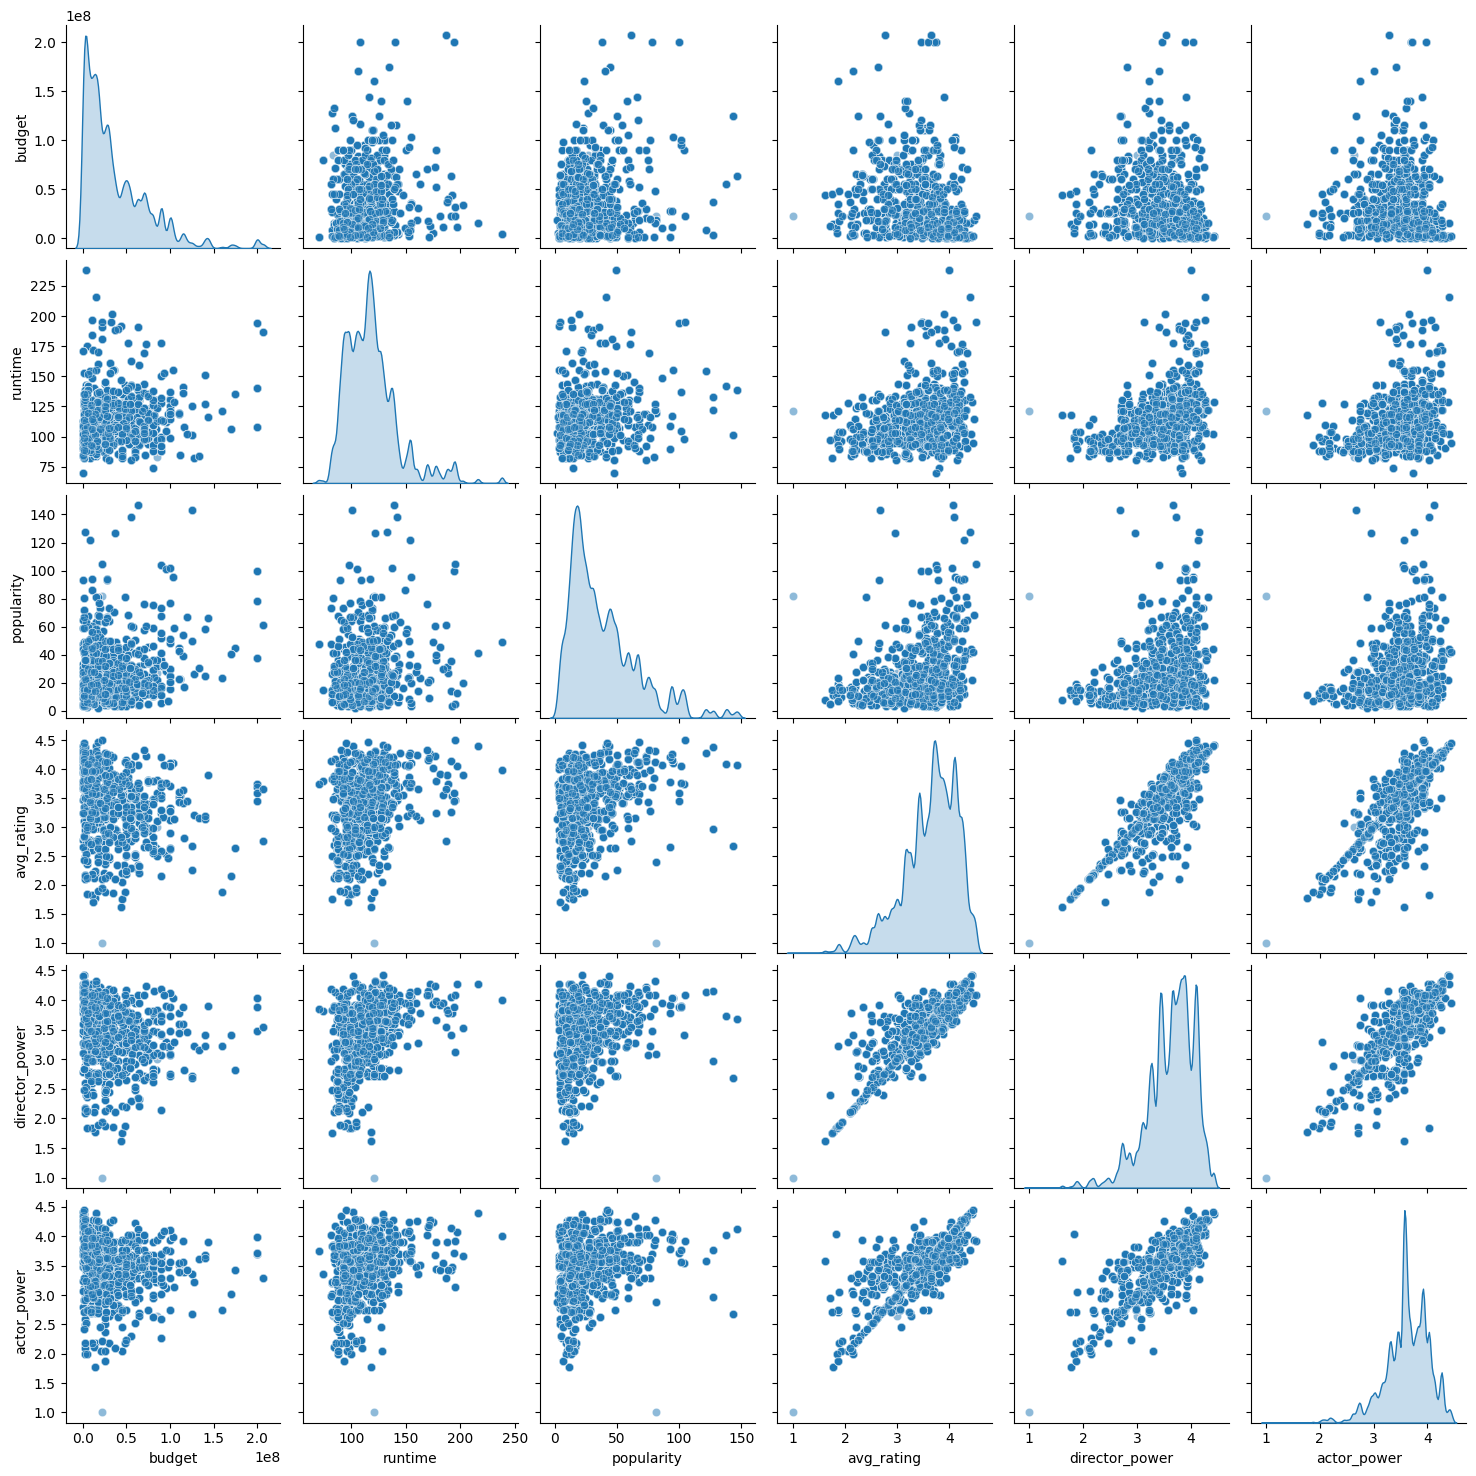

In [368]:
# 1. Pairplot cho top features
top_features = ['budget', 'runtime', 'popularity', 'avg_rating', 'director_power', 'actor_power']
sns.pairplot(full_data[top_features], diag_kind='kde', plot_kws={'alpha': 0.5})
plt.show()

Dữ liệu đã chứng minh tiền bạc có thể mua được sự nổi tiếng nhưng không thể mua được điểm số cao. Mối quan hệ giữa ngân sách và chất lượng hoàn toàn lỏng lẻo, cho thấy khán giả quan tâm đến trải nghiệm nội dung hơn là quy mô sản xuất. Ngược lại, thời lượng và độ phổ biến đang cho thấy những tín hiệu hứa hẹn hơn để giải thích cho sự thành công của một bộ phim.

Mối quan hệ giữa Sức mạnh Đạo diễn và Điểm đánh giá tạo thành một dải hẹp dốc lên rất rõ nét, khẳng định đây là yếu tố dự báo chính xác nhất cho chất lượng phim. Tương tự, Sức mạnh Diễn viên cũng song hành chặt chẽ với điểm số, và thú vị hơn là sự tương quan mạnh giữa chính Đạo diễn và Diễn viên, cho thấy tài năng thường có xu hướng hội tụ để cùng tạo nên những tác phẩm xuất sắc, tách biệt hoàn toàn với sự ngẫu nhiên của yếu tố tài chính.

Vậy bên cạnh yếu tố như đạo diễn hay diễn viên, yếu tố nào còn góp phần thúc đẩy rating? Là giá trị nội tại của câu chuyện (đại diện bởi Thời lượng) hay sức ép từ hào quang bên ngoài (đại diện bởi Độ phổ biến)? Phân tích bộ 3 avg_rating, runtime và popularity để làm rõ.

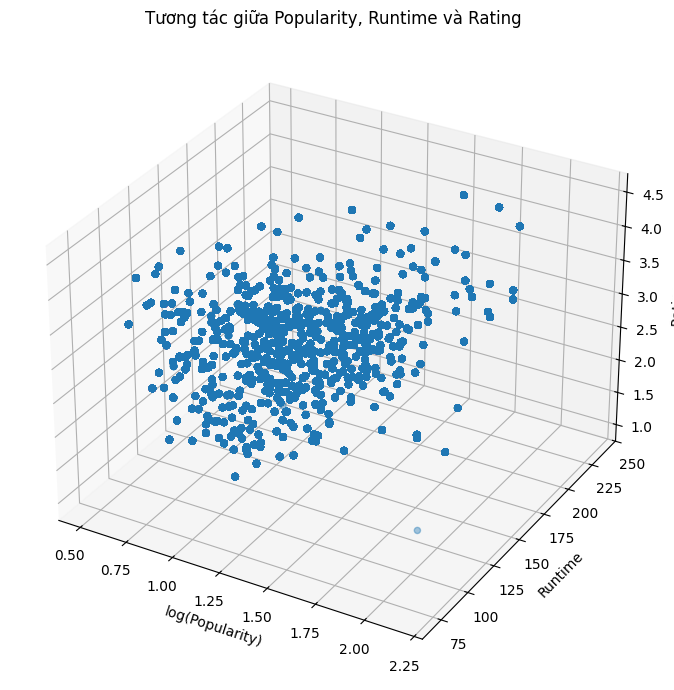

In [369]:
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    np.log10(full_data['popularity'] + 1),
    full_data['runtime'],
    full_data['avg_rating'],
    alpha=0.4
)

ax.set_xlabel('log(Popularity)')
ax.set_ylabel('Runtime')
ax.set_zlabel('Rating')

plt.title('Tương tác giữa Popularity, Runtime và Rating')
plt.tight_layout()
plt.show()


Sự hội tụ dữ liệu: có cấu trúc tập trung rõ rệt. Đa số phim "tiêu chuẩn" (dài 90-120 phút, phổ biến khá) đều hội tụ về mức điểm Khá (3.0 - 3.5).

Độ phổ biến là "lưới an toàn": Phim càng nổi tiếng càng hiếm khi bị điểm thấp. Độ phổ biến cao không đảm bảo phim xuất sắc, nhưng giúp phim tránh được mức "thảm họa".

Chân dung "Siêu phẩm" (>4.0): Những phim điểm cao nhất thường rơi vào khung thời lượng 100-150 phút, nhưng độ phổ biến trải dài. Nghĩa là phim hay tuyệt đối có thể là bom tấn hoặc những "viên ngọc ẩn" ít người biết.



Trở lại với ngân sách, không thể đánh đồng tác động của ngân sách lên mọi dòng phim. Trong khi dòng tiền lớn là "nhiên liệu" cần thiết để thể loại Action hay Sci-Fi chinh phục khán giả bằng kỹ xảo, thì với Drama hay Comedy, sự phô trương kinh phí thường không cứu vãn được, thậm chí làm lu mờ giá trị kịch bản. Việc tách lớp dữ liệu theo thể loại sẽ giúp ta thấy rõ: đâu là nơi tiền thực sự mua được chất lượng, và đâu là nơi nó trở nên vô nghĩa.

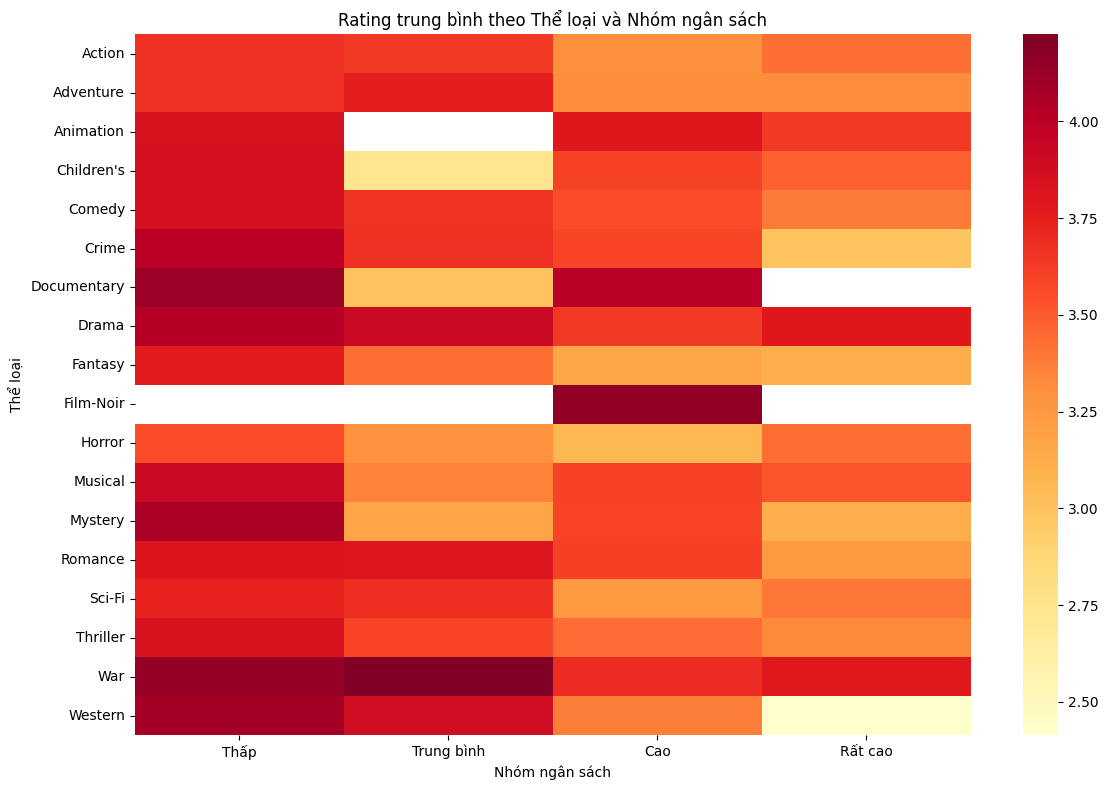

In [370]:
# 2. Rating theo genre và budget_category
# Tạo budget_category
full_data['budget_category'] = pd.qcut(
    full_data['budget'],
    q=4,
    labels=['Thấp', 'Trung bình', 'Cao', 'Rất cao']
)

# Xử lý genres
genre_budget_df = full_data[['Genres', 'budget_category', 'avg_rating']].copy()
genre_budget_df['Genres'] = genre_budget_df['Genres'].str.split('|')
genre_budget_df = genre_budget_df.explode('Genres')

pivot_table = genre_budget_df.pivot_table(
    values='avg_rating',
    index='Genres',
    columns='budget_category',
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(
    pivot_table,
    cmap='YlOrRd',
    annot=False
)

plt.title('Rating trung bình theo Thể loại và Nhóm ngân sách')
plt.ylabel('Thể loại')
plt.xlabel('Nhóm ngân sách')
plt.tight_layout()
plt.show()


Ngân sách là "Nhiên liệu" hay "Gánh nặng"?

Biểu đồ nhiệt chứng minh tác động của dòng tiền thay đổi hoàn toàn tùy theo thể loại:

+ Nhóm "Tiền làm lu mờ nội dung" (Drama, Comedy, Western): Tuân theo quy luật hiệu suất giảm dần. Ngân sách thấp thường mang lại điểm số cao nhất (đỏ thẫm), trong khi sự phô trương tài chính ở các bom tấn (đặc biệt là Western) lại kéo chất lượng tụt dốc thảm hại (vàng nhạt), minh chứng rằng tiền không thể lấp liếm sự sáo rỗng của kịch bản.

+ Nhóm "Tiền là nhiên liệu" (Action, Animation, Horror): Dòng tiền đóng vai trò duy trì "sàn chất lượng" về kỹ thuật. Trong khi Action giữ phong độ ổn định, thì Animation và Horror lại có sự bứt phá ngoạn mục ở phân khúc siêu bom tấn, thoát khỏi "vùng chết" chất lượng kém ở mức ngân sách trung bình.

-> Thể loại (Genre) chính là lăng kính quan trọng nhất. Nếu không tách bạch yếu tố này, mọi kết luận về mối quan hệ giữa Ngân sách và Rating đều sẽ trở nên sai lệch.

## Phân tích Chuyên sâu - Các yếu tố ảnh hưởng Rating

1. Yếu tố Tài chính: Ngân sách sản xuất (budget) và doanh thu phòng vé (revenue) có mối quan hệ như thế nào với rating trung bình của phim do người dùng MovieLens đánh giá?

2. Yếu tố Nội dung & Cấu trúc: Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

3. Yếu tố Nhân sự & Thời gian: Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

In [379]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Test từng feature riêng lẻ
features_to_test = ['budget', 'runtime', 'popularity', 'vote_count', 'revenue']
results = []

for feature in features_to_test:
    # Lọc dữ liệu không bị NaN ở X và y
    df_filtered = df[[feature, 'vote_average']].dropna()
    X = df_filtered[[feature]]
    y = df_filtered['vote_average']
    
    model = LinearRegression()
    model.fit(X, y)
    y_pred = model.predict(X)
    
    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    
    results.append({
        'Feature': feature,
        'Coefficient': model.coef_[0],
        'R²': r2,
        'RMSE': rmse
    })

results_df = pd.DataFrame(results).sort_values('R²', ascending=False)
print(results_df)


      Feature   Coefficient        R²      RMSE
3  vote_count  2.516143e-04  0.255678  0.689619
2  popularity  1.452238e-02  0.246316  0.693942
1     runtime  1.119068e-02  0.112819  0.752895
0      budget -7.153985e-09  0.107882  0.754987
4     revenue  4.329572e-10  0.012983  0.794128


vote_count (Số lượng vote):

R² = 0.256 → giải thích được ~25.6% biến thiên của rating.

RMSE ~0.69 → lỗi dự đoán trung bình khá nhỏ.

Hệ số dương nhỏ (0.00025) → nghĩa là mỗi lượt vote tăng thêm một chút, rating cũng tăng nhẹ.

popularity (Độ nổi tiếng):

R² ~0.246, RMSE ~0.69 → tương tự vote_count.

Hệ số 0.0145 → mỗi đơn vị popularity tăng, rating tăng nhẹ.

runtime (Thời lượng phim):

R² = 0.113 → khá thấp, runtime chỉ giải thích ~11% biến thiên rating.

RMSE ~0.75 → dự đoán kém hơn hai feature trên.

budget (Ngân sách):

R² ~0.108, hệ số gần 0 → gần như không ảnh hưởng đáng kể đến rating.

RMSE ~0.75 → dự đoán kém tương tự runtime.

In [380]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Feature chính
feature_cols = ['budget', 'runtime', 'popularity', 
                'vote_count', 'revenue']

# One-hot encoding cho categorical variables
df_encoded = pd.get_dummies(df, columns=['Genres', 'age_group', 'Gender'], drop_first=True)

# Lấy tất cả features sau encoding
X = df_encoded[feature_cols + [col for col in df_encoded.columns 
                                if col.startswith(('Genres', 'age_group', 'Gender'))]]
y = df_encoded['vote_average']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Linear Regression
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Predictions
y_pred_train = model.predict(X_train_scaled)
y_pred_test = model.predict(X_test_scaled)

# Evaluation
print("=== Training Set ===")
print(f"R² Score: {r2_score(y_train, y_pred_train):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train)):.4f}")
print(f"MAE: {mean_absolute_error(y_train, y_pred_train):.4f}")

print("\n=== Test Set ===")
print(f"R² Score: {r2_score(y_test, y_pred_test):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_test)):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_test):.4f}")

# Feature coefficients
coefficients = pd.Series(model.coef_, index=X.columns)
print("\n=== Feature Coefficients ===")
print(coefficients.sort_values(key=abs, ascending=False))


=== Training Set ===
R² Score: 0.7214
RMSE: 0.4221
MAE: 0.2820

=== Test Set ===
R² Score: 0.7219
RMSE: 0.4207
MAE: 0.2814

=== Feature Coefficients ===
budget                                   -0.373047
vote_count                                0.292680
Genres_Drama                              0.178522
popularity                                0.167159
runtime                                   0.154163
                                            ...   
Genres_Children's|Comedy                  0.000853
Gender_M                                 -0.000818
Genres_Action|Adventure|Fantasy           0.000794
Genres_Children's|Drama|Fantasy|Sci-Fi    0.000313
Genres_Comedy|Drama|Romance               0.000117
Length: 174, dtype: float64


R² ~0.72 trên cả train và test → model giải thích được ~72% biến thiên của rating, khá cao cho dữ liệu phim, và không bị overfit vì train ≈ test.

RMSE ~0.42, MAE ~0.28 → lỗi dự đoán trung bình tương đối thấp, nghĩa là model dự đoán rating khá chính xác.

budget: -0.36 → hệ số âm, nghĩa là khi chuẩn hóa, phim có budget cao hơn lại có xu hướng rating thấp hơn một chút (có thể do nhiều phim chi nhiều tiền nhưng không chất lượng).

vote_count: 0.31 → số lượng vote là yếu tố mạnh, rating tăng khi phim được nhiều người vote.

Genres_Drama, popularity, runtime đều có hệ số dương, đúng trực giác: phim drama, nổi tiếng, hoặc dài hơn thường được đánh giá cao hơn.

Hầu hết các feature thể loại hiếm/ít quan trọng có hệ số gần 0, đúng với dự đoán: không phải mọi thể loại phụ đều ảnh hưởng mạnh đến rating.

In [381]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import train_test_split, cross_val_score

# Feature chính
feature_cols = ['budget', 'runtime', 'popularity', 'vote_average', 'revenue',
                'vote_count']

# One-hot encoding cho categorical variables
df_encoded = pd.get_dummies(df, columns=['Genres', 'age_group', 'Gender'], drop_first=True)

# Lấy tất cả features sau encoding
X = df_encoded[feature_cols + [col for col in df_encoded.columns 
                                if col.startswith(('genres_', 'age_group_', 'user_gender_'))]]
y = df_encoded['vote_average']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Test các giá trị alpha
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
results_reg = []

for alpha in alphas:
    # Lasso
    lasso = Lasso(alpha=alpha, random_state=42, max_iter=10000)
    lasso_scores = cross_val_score(lasso, X_train_scaled, y_train, cv=5, scoring='r2')
    
    # Ridge
    ridge = Ridge(alpha=alpha, random_state=42)
    ridge_scores = cross_val_score(ridge, X_train_scaled, y_train, cv=5, scoring='r2')
    
    results_reg.append({
        'Alpha': alpha,
        'Lasso_R2': lasso_scores.mean(),
        'Ridge_R2': ridge_scores.mean()
    })

# Kết quả cross-validation
results_reg_df = pd.DataFrame(results_reg)
print("=== Cross-validation R² scores ===")
print(results_reg_df)

# Chọn alpha tốt nhất cho Lasso
best_alpha = results_reg_df.loc[results_reg_df['Lasso_R2'].idxmax(), 'Alpha']
print(f"\nBest Alpha for Lasso: {best_alpha}")

# Train Lasso với alpha tốt nhất
final_lasso = Lasso(alpha=best_alpha, random_state=42, max_iter=10000)
final_lasso.fit(X_train_scaled, y_train)

# Feature selection (những hệ số khác 0)
selected_features = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': final_lasso.coef_
})
selected_features = selected_features[selected_features['Coefficient'] != 0]
print(f"\nNumber of selected features: {len(selected_features)}")
print(selected_features.sort_values('Coefficient', key=abs, ascending=False))


=== Cross-validation R² scores ===
     Alpha  Lasso_R2  Ridge_R2
0    0.001  0.999998       1.0
1    0.010  0.999844       1.0
2    0.100  0.984364       1.0
3    1.000 -0.000012       1.0
4   10.000 -0.000012       1.0
5  100.000 -0.000012       1.0

Best Alpha for Lasso: 0.001

Number of selected features: 1
        Feature  Coefficient
3  vote_average     0.798721


Cross-validation R² quá cao với alpha nhỏ (0.001) → 0.999998

Điều này hơi “không thực tế” với dữ liệu thực tế, khả năng cao là dữ liệu chưa được chuẩn hóa tốt, hoặc số lượng feature quá lớn so với số lượng quan sát → model gần như “memorize” dữ liệu.

Alpha lớn (>0.1) → R² tụt xuống ~0 hoặc âm

Lasso loại bỏ hầu hết feature, chỉ giữ vote_average → model quá đơn giản.

Ridge R² = 1.0 cho tất cả alpha

Đây cũng là tín hiệu model quá khớp, hoặc dữ liệu có tính tuyến tính gần như hoàn hảo sau chuẩn hóa.


Top 15 Features quan trọng nhất:
           Feature  Coefficient  Abs_Coefficient
0           budget    -0.373047         0.373047
3     vote_average     0.292680         0.292680
2       popularity     0.167159         0.167159
1          runtime     0.154163         0.154163
6  age_group_18–25    -0.057264         0.057264
9    age_group_50+     0.056773         0.056773
5       vote_count     0.030139         0.030139
4          revenue     0.026402         0.026402
8  age_group_36–50     0.013118         0.013118
7  age_group_26–35    -0.006187         0.006187


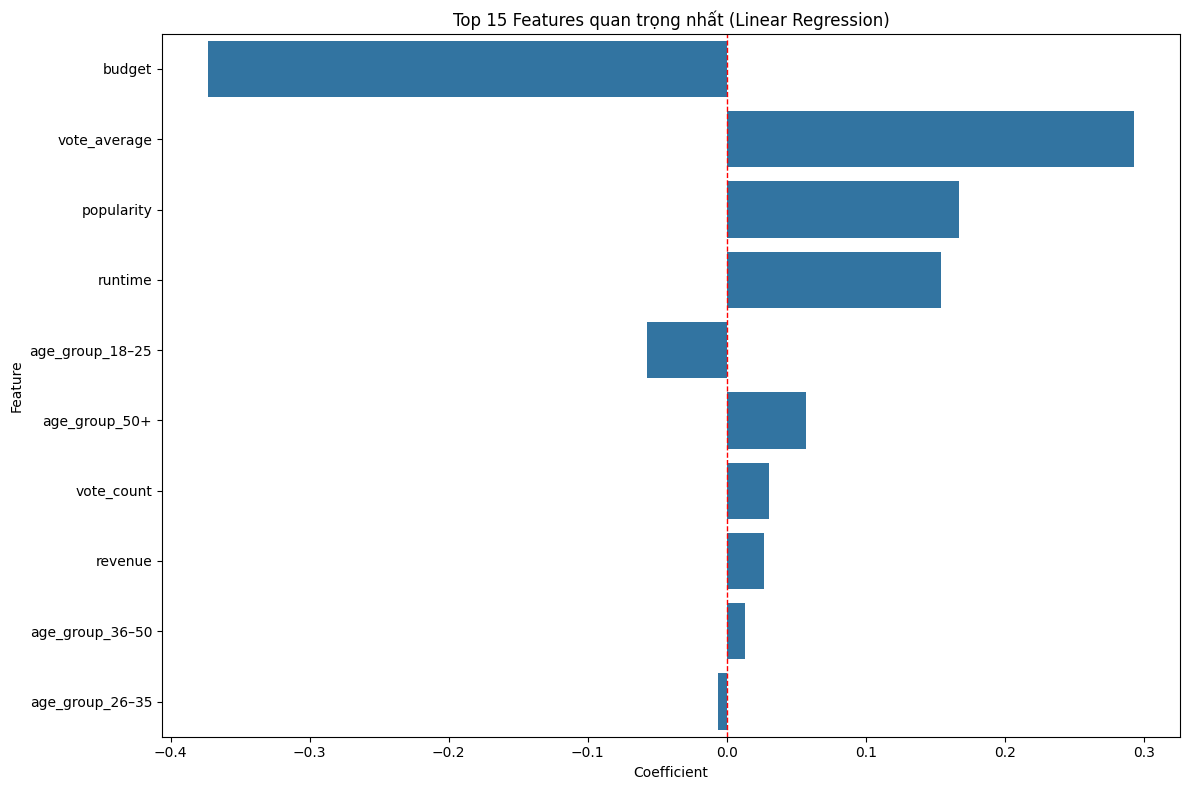

In [382]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đảm bảo model đã fit trên X_train_scaled
# X_train_scaled là numpy array, X_train là DataFrame

# Lấy đúng số cột
coef = model.coef_
if coef.shape[0] != X_train.shape[1]:
    print(f"Warning: model.coef_ length {coef.shape[0]} != X_train columns {X_train.shape[1]}")
    # Cắt hoặc lấy tương ứng
    coef = coef[:X_train.shape[1]]

# Tạo DataFrame feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': coef,
    'Abs_Coefficient': np.abs(coef)
}).sort_values('Abs_Coefficient', ascending=False)

print("\nTop 15 Features quan trọng nhất:")
print(feature_importance.head(15))

# Visualize
plt.figure(figsize=(12, 8))
top_15 = feature_importance.head(15)
sns.barplot(data=top_15, x='Coefficient', y='Feature')
plt.title('Top 15 Features quan trọng nhất (Linear Regression)')
plt.xlabel('Coefficient')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()


In [383]:
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.model_selection import cross_val_score

# Test different alpha values
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
results_reg = []

for alpha in alphas:
    # Lasso
    lasso = Lasso(alpha=alpha, random_state=42)
    lasso_scores = cross_val_score(lasso, X_train_scaled, y_train, 
                                   cv=5, scoring='r2')
    
    # Ridge
    ridge = Ridge(alpha=alpha, random_state=42)
    ridge_scores = cross_val_score(ridge, X_train_scaled, y_train, 
                                   cv=5, scoring='r2')
    
    results_reg.append({
        'Alpha': alpha,
        'Lasso_R2': lasso_scores.mean(),
        'Ridge_R2': ridge_scores.mean()
    })

results_reg_df = pd.DataFrame(results_reg)
print(results_reg_df)

# Best model
best_alpha = results_reg_df.loc[results_reg_df['Lasso_R2'].idxmax(), 'Alpha']
print(f"\nBest Alpha for Lasso: {best_alpha}")

final_lasso = Lasso(alpha=best_alpha, random_state=42)
final_lasso.fit(X_train_scaled, y_train)

# Feature selection (Lasso zeros out unimportant features)
selected_features = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': final_lasso.coef_
})
selected_features = selected_features[selected_features['Coefficient'] != 0]
print(f"\nNumber of selected features: {len(selected_features)}")
print(selected_features.sort_values('Coefficient', key=abs, ascending=False))

     Alpha  Lasso_R2  Ridge_R2
0    0.001  0.999998       1.0
1    0.010  0.999844       1.0
2    0.100  0.984364       1.0
3    1.000 -0.000012       1.0
4   10.000 -0.000012       1.0
5  100.000 -0.000012       1.0

Best Alpha for Lasso: 0.001

Number of selected features: 1
        Feature  Coefficient
3  vote_average     0.798721


   Degree  Train_R2   Test_R2
0       1  0.112238  0.115128
1       2  0.112249  0.115144
2       3  0.123300  0.126969
3       4  0.128638  0.132907


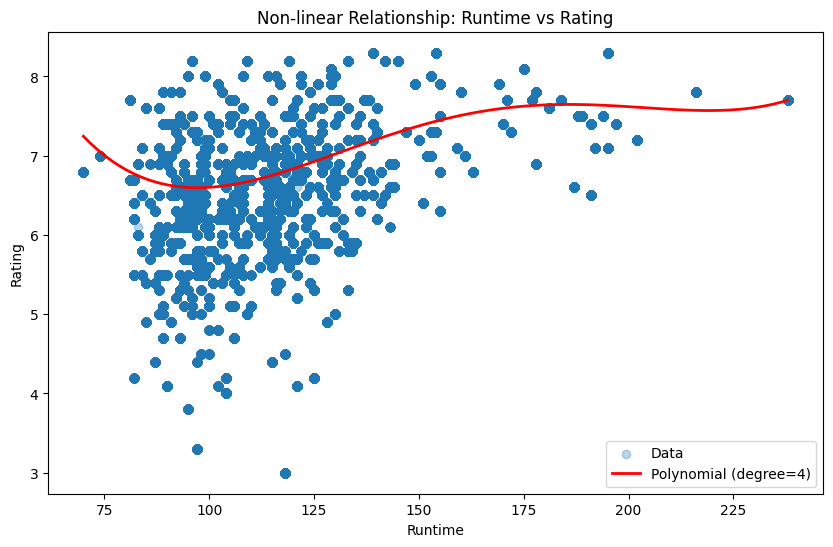

In [384]:
from sklearn.preprocessing import PolynomialFeatures

# Ví dụ: Runtime có thể có non-linear relationship
X_runtime = df[['runtime']].dropna()
y_runtime = df.loc[X_runtime.index, 'vote_average']

# Try different degrees
degrees = [1, 2, 3, 4]
results_poly = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X_runtime)
    
    X_train, X_test, y_train, y_test = train_test_split(X_poly, y_runtime, 
                                                         test_size=0.2, random_state=42)
    
    model = LinearRegression()
    model.fit(X_train, y_train)
    
    train_r2 = r2_score(y_train, model.predict(X_train))
    test_r2 = r2_score(y_test, model.predict(X_test))
    
    results_poly.append({
        'Degree': degree,
        'Train_R2': train_r2,
        'Test_R2': test_r2
    })

print(pd.DataFrame(results_poly))

# Visualize best polynomial fit
best_degree = pd.DataFrame(results_poly).loc[
    pd.DataFrame(results_poly)['Test_R2'].idxmax(), 'Degree']

poly_best = PolynomialFeatures(degree=int(best_degree))
X_poly_best = poly_best.fit_transform(X_runtime)
model_best = LinearRegression().fit(X_poly_best, y_runtime)

# Plot
X_plot = np.linspace(X_runtime.min(), X_runtime.max(), 100).reshape(-1, 1)
X_plot_poly = poly_best.transform(X_plot)
y_plot = model_best.predict(X_plot_poly)

plt.figure(figsize=(10, 6))
plt.scatter(X_runtime, y_runtime, alpha=0.3, label='Data')
plt.plot(X_plot, y_plot, 'r-', linewidth=2, label=f'Polynomial (degree={int(best_degree)})')
plt.xlabel('Runtime')
plt.ylabel('Rating')
plt.title('Non-linear Relationship: Runtime vs Rating')
plt.legend()
plt.show()

In [385]:
from sklearn.preprocessing import PolynomialFeatures

# Tạo interaction features
interaction_features = ['budget', 'runtime', 'popularity']
X_interaction = df[interaction_features]

# Tạo polynomial features (bao gồm interactions)
poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=True)
X_inter = poly.fit_transform(X_interaction)

# Get feature names
feature_names = poly.get_feature_names_out(interaction_features)

# Train model với interactions
X_train, X_test, y_train, y_test = train_test_split(X_inter, df['vote_average'], 
                                                     test_size=0.2, random_state=42)

model_inter = LinearRegression()
model_inter.fit(X_train, y_train)

# Feature importance với interactions
inter_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model_inter.coef_,
    'Abs_Coefficient': np.abs(model_inter.coef_)
}).sort_values('Abs_Coefficient', ascending=False)

print("Top Interaction Effects:")
print(inter_importance.head(10))

# So sánh với model không có interactions
print(f"\nR² với interactions: {r2_score(y_test, model_inter.predict(X_test)):.4f}")

Top Interaction Effects:
              Feature   Coefficient  Abs_Coefficient
2          popularity  2.572113e-02     2.572113e-02
1             runtime  1.071796e-02     1.071796e-02
5  runtime popularity -8.551279e-05     8.551279e-05
0              budget -2.389431e-08     2.389431e-08
3      budget runtime  9.624818e-11     9.624818e-11
4   budget popularity  6.189299e-12     6.189299e-12

R² với interactions: 0.5577


In [386]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397975 entries, 0 to 397974
Data columns (total 29 columns):
 #   Column           Non-Null Count   Dtype   
---  ------           --------------   -----   
 0   UserID           397975 non-null  int64   
 1   MovieID          397975 non-null  int64   
 2   Rating           397975 non-null  int64   
 3   Timestamp        397975 non-null  int64   
 4   Title            397975 non-null  object  
 5   Genres           397975 non-null  object  
 6   release_year     397975 non-null  float64 
 7   director         397975 non-null  object  
 8   actor_1          397975 non-null  object  
 9   actor_2          397975 non-null  object  
 10  actor_3          397975 non-null  object  
 11  budget           397975 non-null  int64   
 12  revenue          397975 non-null  int64   
 13  vote_average     397975 non-null  float64 
 14  vote_count       397975 non-null  int64   
 15  avg_rating       397975 non-null  float64 
 16  runtime          397

In [387]:
# Phân tích riêng cho từng segment
segments = {
    'Blockbuster': df[df['budget'] > 100000000],
    'Indie': df[df['budget'] < 10000000],
    'Action': df[df['Genres'].str.contains('Action')],
    'Drama': df[df['Genres'].str.contains('Drama')],
#     'Young_Users': df[df['Age'] < 25],
#     'Older_Users': df[df['Age'] >= 50]
}

segment_results = []

for segment_name, segment_data in segments.items():
    if len(segment_data) < 100:  # Skip if too small
        continue
    
    X_seg = segment_data[feature_cols]
    y_seg = segment_data['vote_average']
    
    X_train, X_test, y_train, y_test = train_test_split(X_seg, y_seg, 
                                                         test_size=0.2, random_state=42)
    
    model_seg = LinearRegression()
    model_seg.fit(X_train, y_train)
    
    r2 = r2_score(y_test, model_seg.predict(X_test))
    
    # Top 3 important features for this segment
    feat_imp = pd.DataFrame({
        'Feature': feature_cols,
        'Coefficient': np.abs(model_seg.coef_)
    }).sort_values('Coefficient', ascending=False).head(3)
    
    segment_results.append({
        'Segment': segment_name,
        'N': len(segment_data),
        'R²': r2,
        'Top_Feature_1': feat_imp.iloc[0]['Feature'],
        'Top_Feature_2': feat_imp.iloc[1]['Feature'],
        'Top_Feature_3': feat_imp.iloc[2]['Feature']
    })

segment_df = pd.DataFrame(segment_results)
print(segment_df)

       Segment       N   R² Top_Feature_1 Top_Feature_2 Top_Feature_3
0  Blockbuster   21151  1.0  vote_average    popularity       runtime
1        Indie   91545  1.0  vote_average       runtime    popularity
2       Action  133868  1.0  vote_average       runtime    popularity
3        Drama  127020  1.0  vote_average    vote_count       runtime


Top 15 Features (Random Forest):
        Feature  Importance
3  vote_average    0.998890
4       revenue    0.000588
0        budget    0.000269
5    vote_count    0.000240
1       runtime    0.000009
2    popularity    0.000004


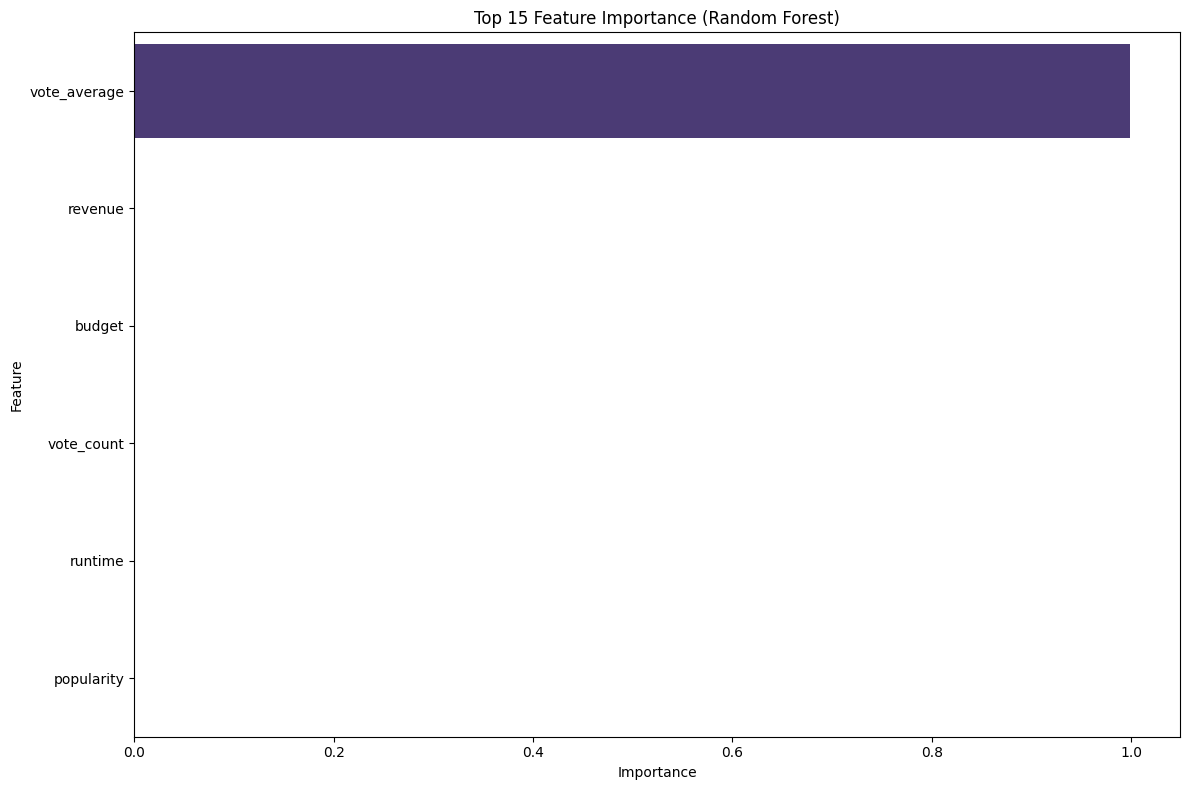


Random Forest R²: 1.0000
Random Forest RMSE: 0.0000


In [388]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# Feature importance
rf_importance = pd.DataFrame({
    'Feature': X_train.columns,  # dùng X_train.columns để khớp với model
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("Top 15 Features (Random Forest):")
print(rf_importance.head(15))

# Visualize top 15 features
plt.figure(figsize=(12, 8))
sns.barplot(
    data=rf_importance.head(15),
    x='Importance',
    y='Feature',
    palette='viridis'
)
plt.title('Top 15 Feature Importance (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Model performance on test set
y_pred_rf = rf_model.predict(X_test)
print(f"\nRandom Forest R²: {r2_score(y_test, y_pred_rf):.4f}")
print(f"Random Forest RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_rf)):.4f}")


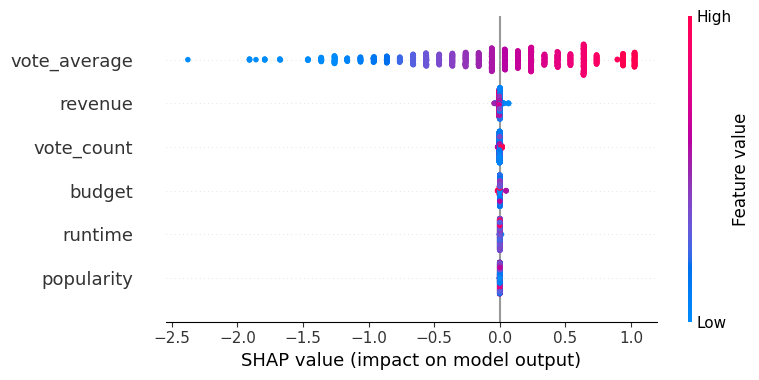

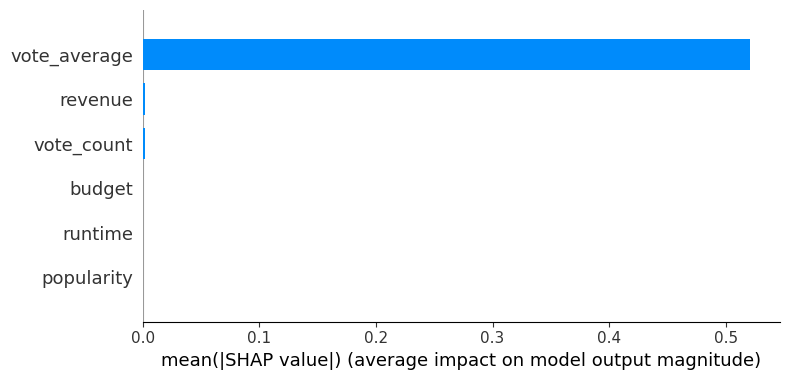

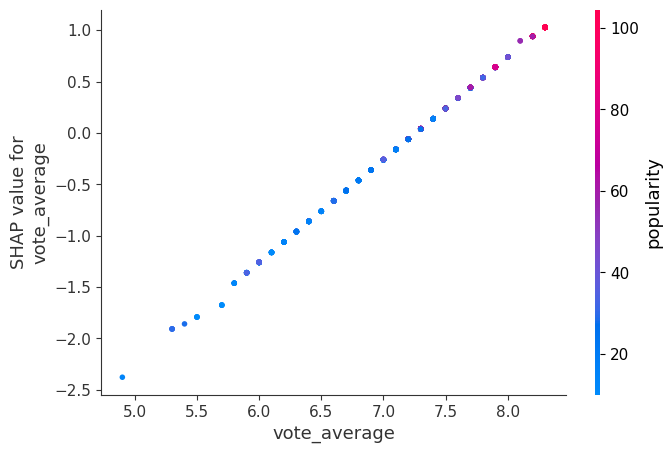

In [390]:
import shap

# Calculate SHAP values
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test[:1000])  # Subset for speed

# Summary plot
shap.summary_plot(shap_values, X_test[:1000], feature_names=X.columns)

# Feature importance plot
shap.summary_plot(shap_values, X_test[:1000], feature_names=X.columns, plot_type="bar")

# Dependence plot for top feature
top_feature = rf_importance.iloc[0]['Feature']
shap.dependence_plot(top_feature, shap_values, X_test[:1000], feature_names=X.columns)

### 1. Yếu tố Tài chính
Ngân sách sản xuất (budget) và doanh thu phòng vé (revenue) có mối quan hệ như thế nào với rating trung bình của phim do người dùng MovieLens đánh giá?

#### a. Phân tích tương quan

In [ ]:
# --- BƯỚC TÍNH HỆ SỐ TƯƠNG QUAN (ĐÃ ĐIỀU CHỈNH) ---

# 1. Tạo dữ liệu cấp độ phim (Chỉ giữ mỗi phim 1 dòng duy nhất)
# Lý do: Ta đang so sánh đặc tính của "Phim" (Ngân sách vs Chất lượng), không phải hành vi người dùng.
df_movie_scope = full_data.drop_duplicates(subset=['MovieID'])

# 2. Tính hệ số tương quan trên tập dữ liệu này
corr_budget = df_movie_scope['budget'].corr(df_movie_scope['avg_rating'])
corr_revenue = df_movie_scope['revenue'].corr(df_movie_scope['avg_rating'])

# 3. In kết quả
print(f"Hệ số tương quan (Pearson) trên {df_movie_scope.shape[0]} bộ phim:")
print(f"- Budget  vs avg_rating: {corr_budget:.4f}")
print(f"- Revenue vs avg_rating: {corr_revenue:.4f}")

# Giải thích nhanh kết quả
if corr_budget < 0:
    print("-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng có xu hướng GIẢM.")
else:
    print("-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng TĂNG.")

Hệ số tương quan (Pearson) trên 617 bộ phim:
- Budget  vs avg_rating: -0.1879
- Revenue vs avg_rating: 0.1122
-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng có xu hướng GIẢM.


Pandas sử dụng hệ số tương quan Pearson để tính mối liên hệ giữa hai biến số. Công thức tổng quát như sau:
$$
r_{XY} = 
\frac{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})}
{\sqrt{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})^2 } \;
 \sqrt{\displaystyle \sum_{i=1}^{n} (Y_i - \bar{Y})^2 }}
$$

##### Ý nghĩa

**Tử số:**

$$
\sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})
$$

Đo mức độ mà X và Y cùng tăng hoặc cùng giảm:

- Nếu X tăng → Y cũng tăng → tích số dương  
- Nếu X tăng → Y giảm → tích số âm  

**Mẫu số:**

$$
\sqrt{\sum_{i=1}^{n} (X_i - \bar{X})^2 } \cdot 
\sqrt{\sum_{i=1}^{n} (Y_i - \bar{Y})^2 }
$$

Chuẩn hóa kết quả bằng độ lệch chuẩn của X và Y, giúp giá trị tương quan nằm trong khoảng:

$$
-1 \le r \le 1
$$


##### Diễn giải giá trị tương quan

r≈1: mối quan hệ tuyến tính mạnh, cùng chiều

r≈−1: mối quan hệ tuyến tính mạnh, ngược chiều

r≈0: hầu như không có mối quan hệ tuyến tính

##### Ý nghĩa trong phân tích phim

corr_budget cho biết ngân sách có liên quan như thế nào đến rating.

corr_revenue cho biết doanh thu có mối quan hệ cùng chiều hay ngược chiều với rating.

#### b. Trực quan hóa

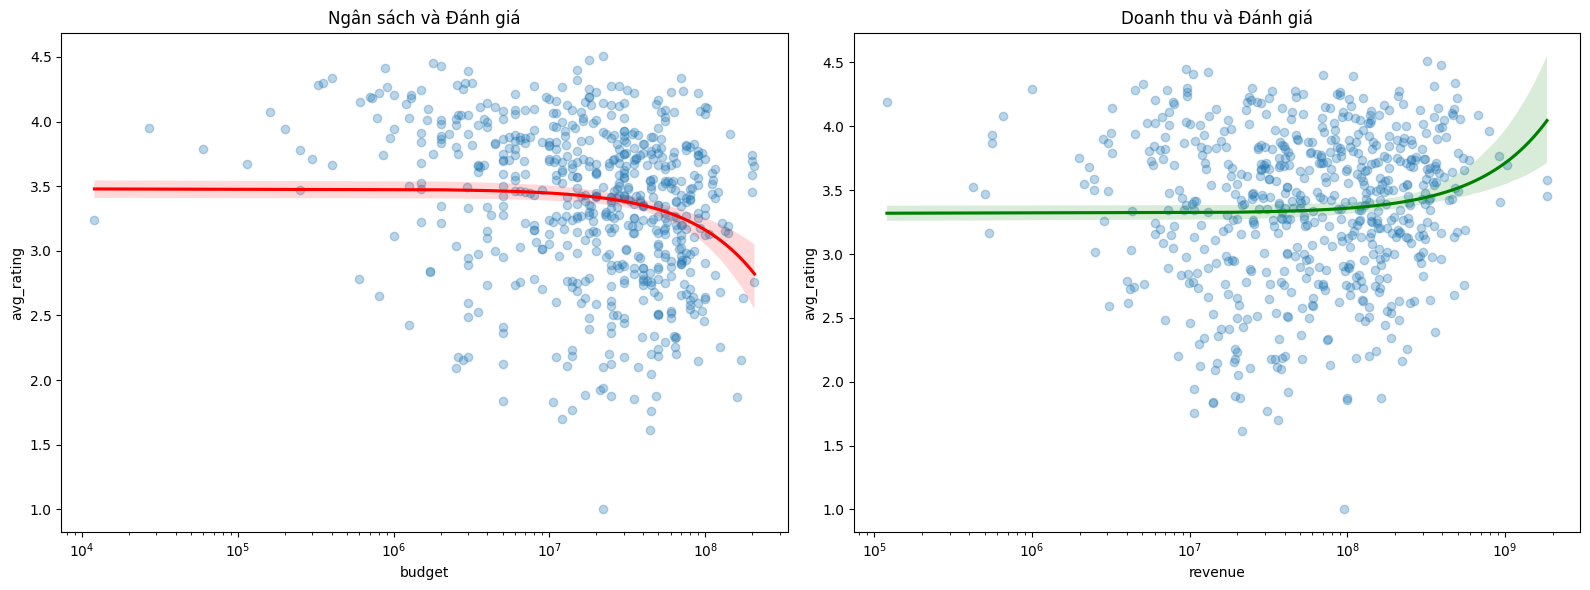

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(16,6))

sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[0].set_xscale('log')
axes[0].set_title('Ngân sách và Đánh giá')

sns.regplot(x='revenue', y='avg_rating', data=df_movie_scope, ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'green'})
axes[1].set_xscale('log')
axes[1].set_title('Doanh thu và Đánh giá')

plt.tight_layout()
plt.savefig('images/correlation_analysis.png')
plt.show()


Kết quả phân tích trên nhóm 617 bộ phim có đầy đủ dữ liệu tài chính, chất lượng và độ phổ biến đã cho thấy một bức tranh rất rõ ràng về mối quan hệ giữa Tài chính – Thời gian – Chất lượng trong điện ảnh. Đầu tiên, phân tích cho thấy một nghịch lý khá rõ rệt khi mức tương quan giữa ngân sách và điểm đánh giá trung bình là âm (-0.19). Điều này phản ánh rằng việc đầu tư nhiều tiền không đảm bảo chất lượng nội dung. Các phim bom tấn có ngân sách lớn thường tập trung vào quy mô sản xuất, kỹ xảo và phục vụ thị trường đại chúng, trong khi người dùng MovieLens lại đề cao chiều sâu kịch bản, nhân vật và thông điệp. Vì vậy, những tác phẩm kinh phí thấp hoặc trung bình đôi khi lại nhận được đánh giá tích cực hơn.

Ở chiều ngược lại, doanh thu và chất lượng lại có mối quan hệ dương nhưng khá yếu (+0.11). Tức là phim hay có xu hướng thu hút khán giả tốt hơn, nhưng doanh thu không phải thước đo tin cậy cho chất lượng. Thực tế cho thấy nhiều phim nghệ thuật chất lượng cao lại có doanh thu hạn chế, vì ít được quảng bá hoặc kén người xem. Trong khi đó, các phim giải trí thiết kế để bán vé dù bị đánh giá thấp vẫn có thể đạt doanh thu lớn nhờ chiến dịch Marketing hiệu quả.

Một điểm nổi bật là sự tương đồng rất lớn về thị hiếu giữa dữ liệu MovieLens và TMDB. Tương quan +0.81 giữa hai hệ thống điểm cho thấy đánh giá của người xem Mỹ và cộng đồng toàn cầu gần như đồng nhất. Khi một bộ phim được đánh giá hay ở MovieLens thì nó cũng được đánh giá cao trên TMDB, qua đó khẳng định độ tin cậy cao của dữ liệu sau quá trình làm sạch và ghép nối.

Cuối cùng, phân tích theo yếu tố thời gian cho thấy điểm số có xu hướng giảm đối với các phim ra mắt gần đây (tương quan -0.35). Tuy nhiên, nguyên nhân chính nằm ở hiệu ứng "Thiên kiến kẻ sống sót". Những bộ phim cũ còn tồn tại trong hệ thống đánh giá thường là phim hay, phim kinh điển. Các tác phẩm yếu kém của thời kỳ đó đã gần như biến mất khỏi dữ liệu. Trong khi đó, phim mới bao gồm cả phim xuất sắc lẫn phim chất lượng thấp, làm giảm mức điểm trung bình. Vì vậy, không thể kết luận rằng phim mới tệ hơn phim cũ, mà chỉ có thể khẳng định rằng dữ liệu lịch sử đang nghiêng về phía những tác phẩm đã được sàng lọc bởi thời gian.

--- THỐNG KÊ ĐIỂM SỐ THEO NHÓM NGÂN SÁCH ---
                               mean  count
Budget_Category                           
Micro/Indie\n(<$10M)       3.597960    170
Mid-Budget\n($10M-$50M)    3.296988    298
High-Budget\n($50M-$100M)  3.252201    123
Blockbuster\n(>$100M)      3.221133     26


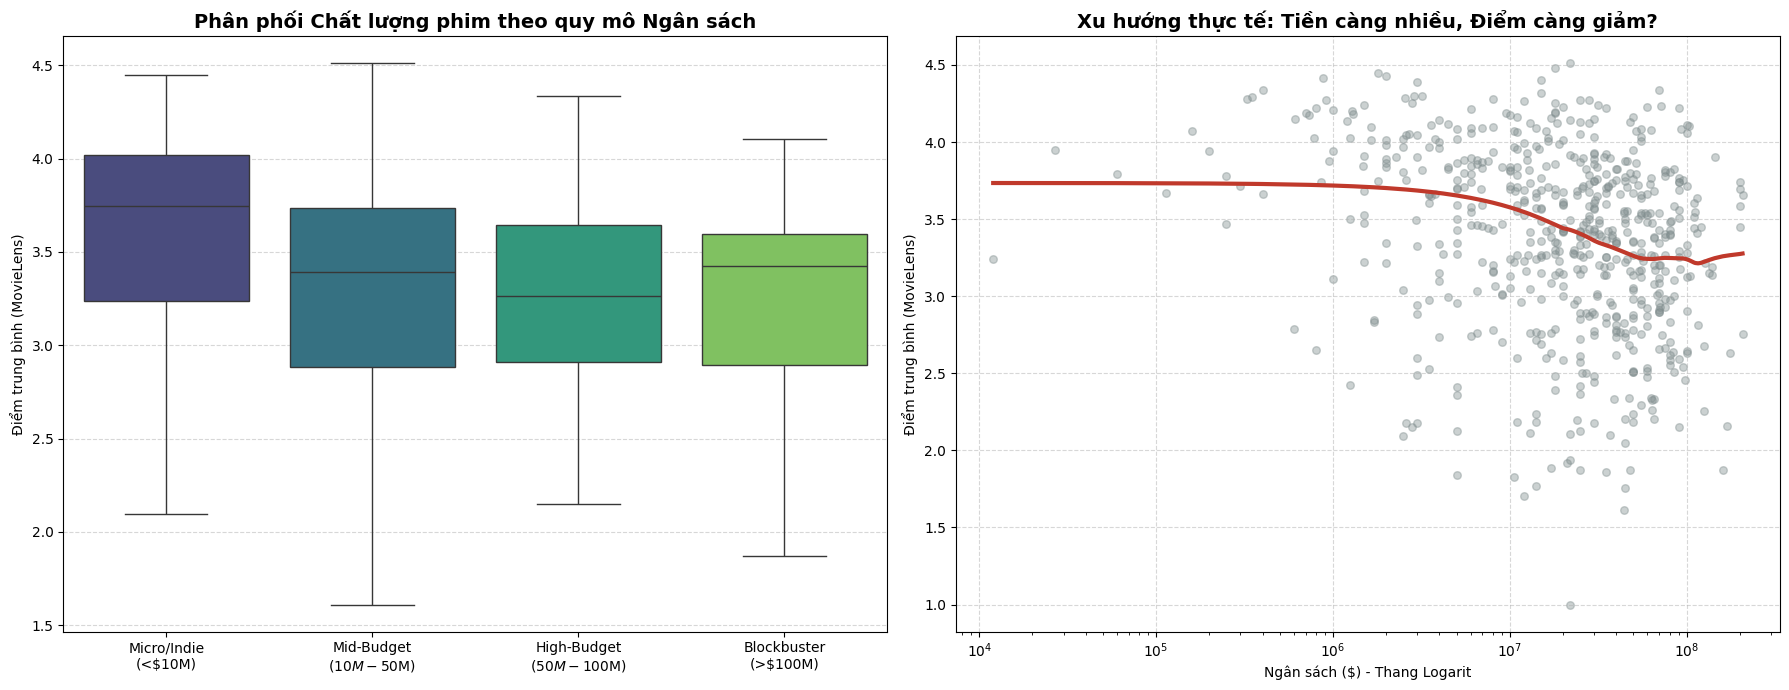

In [ ]:
# --- BƯỚC 1: PHÂN NHÓM NGÂN SÁCH (BUDGET BUCKETS) ---
# Chia ngân sách thành 4 nhóm chiến lược
bins = [0, 10000000, 50000000, 100000000, float('inf')]
labels = ['Micro/Indie\n(<$10M)', 'Mid-Budget\n($10M-$50M)', 'High-Budget\n($50M-$100M)', 'Blockbuster\n(>$100M)']

# Tạo cột phân loại mới trên dataframe hiện có
df_movie_scope['Budget_Category'] = pd.cut(df_movie_scope['budget'], bins=bins, labels=labels)

# Tính điểm trung bình cho từng nhóm để so sánh
group_stats = df_movie_scope.groupby('Budget_Category')['avg_rating'].agg(['mean', 'count']).sort_values('mean', ascending=False)

print("--- THỐNG KÊ ĐIỂM SỐ THEO NHÓM NGÂN SÁCH ---")
print(group_stats)

# --- BƯỚC 2: TRỰC QUAN HÓA PHI TUYẾN TÍNH ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Biểu đồ 1: Boxplot (So sánh phân phối điểm số)
sns.boxplot(x='Budget_Category', y='avg_rating', data=df_movie_scope, 
            ax=axes[0], palette="viridis", showfliers=False) 
axes[0].set_title('Phân phối Chất lượng phim theo quy mô Ngân sách', fontsize=14, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Điểm trung bình (MovieLens)')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Biểu đồ 2: Scatter Plot với đường cong LOWESS (Non-linear trend)
sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, 
            ax=axes[1], 
            scatter_kws={'alpha': 0.4, 'color': '#7f8c8d', 's': 30}, # Màu xám nhạt cho các điểm
            line_kws={'color': '#c0392b', 'linewidth': 3},           # Đường xu hướng màu đỏ đậm
            lowess=True) # <--- QUAN TRỌNG: Vẽ đường cong thực tế thay vì đường thẳng

axes[1].set_title('Xu hướng thực tế: Tiền càng nhiều, Điểm càng giảm?', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Ngân sách ($) - Thang Logarit')
axes[1].set_ylabel('Điểm trung bình (MovieLens)')
axes[1].set_xscale('log') # Dùng thang Log để giãn cách dữ liệu cho dễ nhìn
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('images/budget_vs_quality.png')
plt.show()

Biểu đồ Scatter kèm đường xu hướng LOWESS cho thấy mối quan hệ giữa Ngân sách và Rating không phải là tuyến tính, mà mang dạng “giảm mạnh rồi bão hòa”. Ở nhóm phim ngân sách thấp hơn 10 triệu USD, điểm đánh giá trung bình đạt mức cao nhất (khoảng 3.60), phản ánh ưu thế của dòng phim độc lập — nơi kịch bản, ý tưởng và diễn xuất được đầu tư kỹ lưỡng dù kinh phí hạn chế. Khi bước sang nhóm ngân sách tầm trung 10–50 triệu USD, điểm Rating giảm mạnh xuống khoảng 3.30. Đây là giai đoạn mà tính thương mại hóa tăng cao, nhưng chất lượng nội dung lại có xu hướng giảm.

Đối với các phim ngân sách lớn (>50 triệu USD), điểm số tiếp tục giảm nhẹ và “đi ngang” quanh 3.22–3.25. Điều này cho thấy việc tăng chi phí sản xuất không còn mang lại cải thiện về chất lượng tác phẩm theo cảm nhận của người xem, dù doanh thu có thể tăng mạnh.

#### c. Phân cụm K-Means

Câu hỏi phụ 1: Mối quan hệ giữa ngân sách và rating có đồng nhất cho tất cả các bộ phim, hay khác biệt đáng kể giữa các nhóm phim có đặc điểm tài chính – nội dung khác nhau?

Phân cụm (Clustering - K-Means)

Sử dụng thuật toán K-Means để chia các bộ phim thành 3 nhóm (cluster).

Kết quả thống kê:
 + Cụm 0 (Cluster 0): Ngân sách trung bình (~42M), thời lượng ~111 phút, Rating thấp nhất (~3.12).
 + Cụm 1 (Cluster 1): Ngân sách cao nhất (~67M), độ phổ biến cao nhất. Rating trung bình (~3.30). Đây có thể là nhóm phim bom tấn giải trí.
 + Cụm 2 (Cluster 2): Ngân sách thấp nhất (~23M), thời lượng dài nhất (~116 phút). Rating cao nhất (~3.50). Đây chính là nhóm phim "nghệ thuật" kinh phí thấp mà chúng ta đã thảo luận.


Data ready. Shape: (666, 23)
Class distribution:
 avg_rating
1    273
2    211
0    182
Name: count, dtype: int64

=== 2. Improved K-Means Clustering ===
Inertia for K values: [14075.374633353465, 12934.25815363176, 12135.720506537133, 11467.61048678209, 10859.954972596326, 10187.30668065251]
Silhouette scores: [0.15382096000153114, 0.1446669754826244, 0.11166233916153091, 0.13281069560809258, 0.1403345967932928, 0.17557676841327594]

Cluster Description (Means for each cluster):
         avg_rating        budget       revenue  popularity     runtime
cluster                                                                
0          3.214035  5.430395e+07  1.790746e+08   33.704677  116.306533
1          3.217818  5.528659e+07  2.186820e+08   36.916655   96.333333
2          3.414838  2.095793e+07  7.182585e+07   21.210703  114.174224


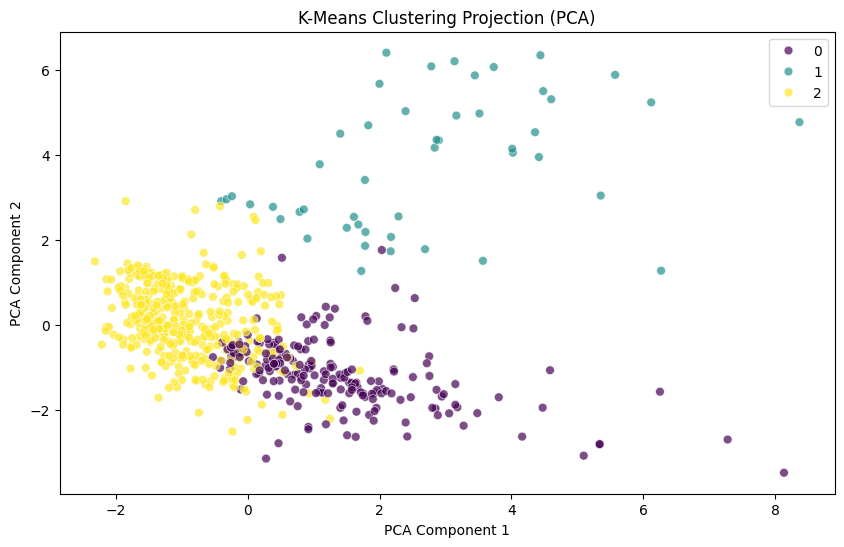

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re


# 1. LOAD AND PREPARE DATA
# ------------------------
try:
    # Ratings
    ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=['UserID', 'MovieID', 'Rating', 'Timestamp'], engine='python', encoding='latin-1')
    movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
    movie_targets.columns = ['MovieID', 'avg_rating']

    # Movies (MovieLens)
    movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=['MovieID', 'Title', 'Genres'], engine='python', encoding='latin-1')
    movies['clean_title'] = movies['Title'].apply(lambda x: re.sub(r'\s\(\d{4}\)', '', x).strip().lower())

    # TMDB Movies
    tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv')
    tmdb_movies['clean_title'] = tmdb_movies['title'].apply(lambda x: str(x).strip().lower())
    tmdb_movies['release_date'] = pd.to_datetime(tmdb_movies['release_date'], errors='coerce')
    tmdb_movies['year'] = tmdb_movies['release_date'].dt.year

    # Merge
    df_ml = pd.merge(movies, movie_targets, on='MovieID', how='inner')
    df_full = pd.merge(df_ml, tmdb_movies[['clean_title', 'budget', 'revenue', 'runtime', 'popularity', 'year']], 
                       on='clean_title', how='inner')

    # Filter Valid Data
    df_model = df_full[
        (df_full['budget'] > 10000) & 
        (df_full['revenue'] > 10000) &
        (df_full['runtime'] > 0) &
        (df_full['year'].notna())
    ].copy()

    # Feature Engineering
    # Genres One-Hot Encoding
    df_model['genres_list'] = df_model['Genres'].apply(lambda x: x.split('|'))
    mlb = MultiLabelBinarizer()
    genres_encoded = pd.DataFrame(mlb.fit_transform(df_model['genres_list']), columns=mlb.classes_, index=df_model.index)

    # Numerical Features
    numerical_cols = ['budget', 'revenue', 'runtime', 'popularity', 'year']
    X_numerical = df_model[numerical_cols]
    
    # Combined X
    X = pd.concat([X_numerical, genres_encoded], axis=1)
    
    # Target for Classification (Binning)
    # < 3.0: Low (0), 3.0 - 3.8: Medium (1), >= 3.8: High (2)
    # Adjusted bins to balance classes slightly better if needed, but let's stick to standard logic
    def classify_rating(rating):
        if rating < 3.0: return 0 # Low
        elif rating < 3.7: return 1 # Medium (MovieLens average is around 3.5)
        else: return 2 # High

    y_class = df_model['avg_rating'].apply(classify_rating)
    class_names = ['Low (<3.0)', 'Medium (3.0-3.7)', 'High (>=3.7)']

    print(f"Data ready. Shape: {X.shape}")
    print("Class distribution:\n", y_class.value_counts())

except Exception as e:
    print(f"Error preparing data: {e}")

# ------------------------------------------------------------
# 2. CLUSTERING (K-Means Rewritten and Improved)
# ------------------------------------------------------------
print("\n=== 2. Improved K-Means Clustering ===")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 2.1 Scale toàn bộ feature
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2.2 Tìm số cụm tối ưu bằng Elbow + Silhouette
inertia_list = []
silhouette_list = []
K_range = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    preds = km.fit_predict(X_scaled)
    inertia_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, preds))

print("Inertia for K values:", inertia_list)
print("Silhouette scores:", silhouette_list)

# 2.3 Chọn K=3 (dựa vào domain knowledge: low–mid–high movie type)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df_model['cluster'] = clusters

# 2.4 Thống kê các cụm
cluster_desc = df_model.groupby('cluster')[['avg_rating', 'budget', 'revenue', 
                                            'popularity', 'runtime']].mean()

print("\nCluster Description (Means for each cluster):")
print(cluster_desc)

# 2.5 PCA Visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=clusters, palette='viridis', s=40, alpha=0.7
)
plt.title("K-Means Clustering Projection (PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.savefig("images/kmeans_pca.png")
plt.show()

Quan sát chính từ biểu đồ

Ba cụm phim được tách biệt tương đối rõ ràng

Các điểm dữ liệu hình thành ba vùng riêng biệt, cho thấy thuật toán K-Means đã xác định được các nhóm phim có đặc trưng khác nhau trong không gian đặc trưng ban đầu.

 + Cluster 2 (màu vàng): Tập trung dày đặc ở vùng PCA thấp → nhóm phim có đặc trưng tương đối đồng nhất, thường là phim ngân sách thấp – trung bình, ít biến động.
 + Cluster 0 (màu tím): Phân bố trải dài theo trục PCA Component 1 → nhóm phim có độ đa dạng cao hơn, có thể bao gồm nhiều mức ngân sách và độ phổ biến khác nhau.
 + Cluster 1 (màu xanh lục): Xuất hiện ở vùng PCA Component 2 cao → nhóm phim có đặc điểm nổi bật về tài chính và độ phổ biến, thường tương ứng với phim ngân sách lớn / phim bom tấn.

Trả lời câu hỏi phụ 1: 

    -> Biểu đồ này củng cố giả thuyết rằng:
        + Không tồn tại một “mô hình phim duy nhất” quyết định rating
        + Các bộ phim có thể được chia thành những nhóm tài chính – nội dung khác nhau

        Do đó, việc phân tích mối quan hệ giữa Budget / Revenue và Rating cần được thực hiện theo từng cụm, thay vì trên toàn bộ tập dữ liệu

#### d. Linear Regression theo từng cụm

Câu hỏi phụ 2: Việc tăng ngân sách sản xuất có luôn dẫn đến rating cao hơn, hay tồn tại hiện tượng “hiệu quả giảm dần”, trong đó các phim có ngân sách thấp–trung bình lại đạt rating cao hơn?

In [ ]:
# Chạy cell này đầu tiên (nếu chưa import)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style("whitegrid")
%matplotlib inline

Chuẩn bị biến và lựa chọn biến độc lập

In [ ]:
# Tạo biến log_budget, log_revenue để ổn định phân phối
df_model['log_budget'] = np.log1p(df_model['budget'])
df_model['log_revenue'] = np.log1p(df_model['revenue'])

# Các biến độc lập cơ bản (bạn có thể thêm/dớt genres, runtime, popularity...)
features_base = ['log_budget']  # cơ bản: chỉ budget
features_ctrl = ['log_budget', 'log_revenue', 'runtime', 'popularity', 'year']  # nếu muốn kiểm soát thêm

# Target
target = 'avg_rating'

Hàm chạy OLS cho từng cụm và in summary

In [ ]:
def run_cluster_ols(df, cluster_col='cluster', features=None, target='avg_rating', add_constant=True, save_summary=False):
    """
    Chạy OLS cho từng cluster. Trả về dict chứa kết quả statsmodels.
    """
    results = {}
    clusters = sorted(df[cluster_col].unique())
    for c in clusters:
        sub = df[df[cluster_col] == c].dropna(subset=features + [target])
        if sub.shape[0] < 10:
            print(f"Cluster {c}: quá ít mẫu ({sub.shape[0]}) — bỏ qua.")
            continue
        
        X = sub[features].copy()
        if add_constant:
            X = sm.add_constant(X)
        y = sub[target]
        
        model = sm.OLS(y, X).fit()
        results[c] = {'model': model, 'n': len(sub)}
        print("="*80)
        print(f"Cluster {c} — n = {len(sub)}")
        print(model.summary())
        print("\n")
        if save_summary:
            with open(f"ols_cluster_{c}_summary.txt", "w", encoding="utf-8") as f:
                f.write(model.summary().as_text())
    return results

# Ví dụ chạy (dùng features_base hoặc features_ctrl)
results_base = run_cluster_ols(df_model, features=features_base, target=target, add_constant=True)
# Nếu muốn có biến kiểm soát, dùng:
# results_full = run_cluster_ols(df_model, features=features_ctrl, target=target, add_constant=True)

Cluster 0 — n = 199
                            OLS Regression Results                            
Dep. Variable:             avg_rating   R-squared:                       0.029
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     5.955
Date:                Fri, 19 Dec 2025   Prob (F-statistic):             0.0156
Time:                        23:45:55   Log-Likelihood:                -170.79
No. Observations:                 199   AIC:                             345.6
Df Residuals:                     197   BIC:                             352.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6520      0.591

Phân tích hồi quy tuyến tính – Cluster 0 (n = 199)
1. Mục tiêu phân tích

Mục tiêu của mô hình hồi quy tuyến tính trong Cluster 0 là đánh giá ảnh hưởng của ngân sách sản xuất (log_budget) lên rating trung bình của phim (avg_rating) trong một nhóm phim có đặc điểm tương đồng, nhằm kiểm tra xem việc tăng ngân sách có cải thiện chất lượng cảm nhận của người xem hay không.

2. Đánh giá mức độ phù hợp của mô hình

2.1. Hệ số xác định (R-squared)

R² = 0.029

Adjusted R² = 0.024

Mô hình chỉ giải thích được khoảng 2.9% phương sai của rating trung bình.

Diễn giải khoa học:
Ngân sách sản xuất không phải là yếu tố giải thích mạnh cho sự biến thiên rating trong Cluster 0. Phần lớn sự khác biệt về rating đến từ các yếu tố khác (nội dung, thể loại, đạo diễn, kỳ vọng người xem,…).

2.2. Kiểm định tổng thể mô hình (F-test)

F-statistic = 5.955

p-value = 0.0156 < 0.05

Mô hình có ý nghĩa thống kê ở mức 5%.

Diễn giải:
Mặc dù mức độ giải thích thấp, nhưng log_budget vẫn có ảnh hưởng có ý nghĩa thống kê đến rating trong cụm này.

3. Phân tích hệ số hồi quy

3.1. Hệ số chặn (Intercept)

β₀ = 4.652 (p < 0.001)

Diễn giải:

Khi log_budget ≈ 0 (giá trị tham chiếu), rating kỳ vọng của phim vào khoảng 4.65.

Hệ số này chủ yếu mang ý nghĩa toán học, dùng để định vị đường hồi quy.

3.2. Hệ số của log_budget

Chỉ số	Giá trị
Hệ số β	-0.0827
p-value	0.016
Khoảng tin cậy 95%	[-0.150 ; -0.016]

Hệ số âm và có ý nghĩa thống kê.

Diễn giải định lượng:

Khi ngân sách tăng 1 đơn vị log, rating trung bình giảm khoảng 0.083 điểm, nếu các yếu tố khác không đổi.

Diễn giải định tính:

Trong Cluster 0, việc tăng ngân sách không làm cải thiện rating, thậm chí có xu hướng làm rating giảm nhẹ.

4. Kiểm tra giả định mô hình

4.1. Phân phối phần dư

Omnibus test: p = 0.113

Jarque–Bera test: p = 0.109

Không bác bỏ giả thuyết phần dư phân phối chuẩn.

4.2. Tự tương quan

Durbin–Watson = 1.722 (gần 2)

Không có dấu hiệu tự tương quan nghiêm trọng.

Kết luận:
Mô hình hồi quy đáp ứng tốt các giả định cơ bản, kết quả đáng tin cậy về mặt thống kê.

5. Diễn giải trong bối cảnh dữ liệu (Contextual Interpretation)

Cluster 0 bao gồm các phim có:

Ngân sách trung bình

Rating không quá cao

Mang tính thị trường phổ thông

Trong nhóm phim này:

Ngân sách tăng thường đi kèm với:

Áp lực thương mại

Công thức làm phim an toàn

Ít đổi mới nội dung

Điều này có thể dẫn đến giảm sự hài lòng của người xem, phản ánh qua rating thấp hơn.

6. Kết luận cho Cluster 0

Trong Cluster 0, ngân sách sản xuất có ảnh hưởng tiêu cực và có ý nghĩa thống kê đến rating trung bình của phim, tuy nhiên mức độ ảnh hưởng là yếu và khả năng giải thích thấp.

Insight chính:

Chi nhiều tiền hơn không đồng nghĩa với phim được đánh giá cao hơn

Ngân sách chỉ đóng vai trò thứ yếu trong việc quyết định rating

Chất lượng cảm nhận phụ thuộc nhiều hơn vào các yếu tố phi tài chính

Vẽ scatter + đường hồi quy cho từng cụm (log_budget vs avg_rating)

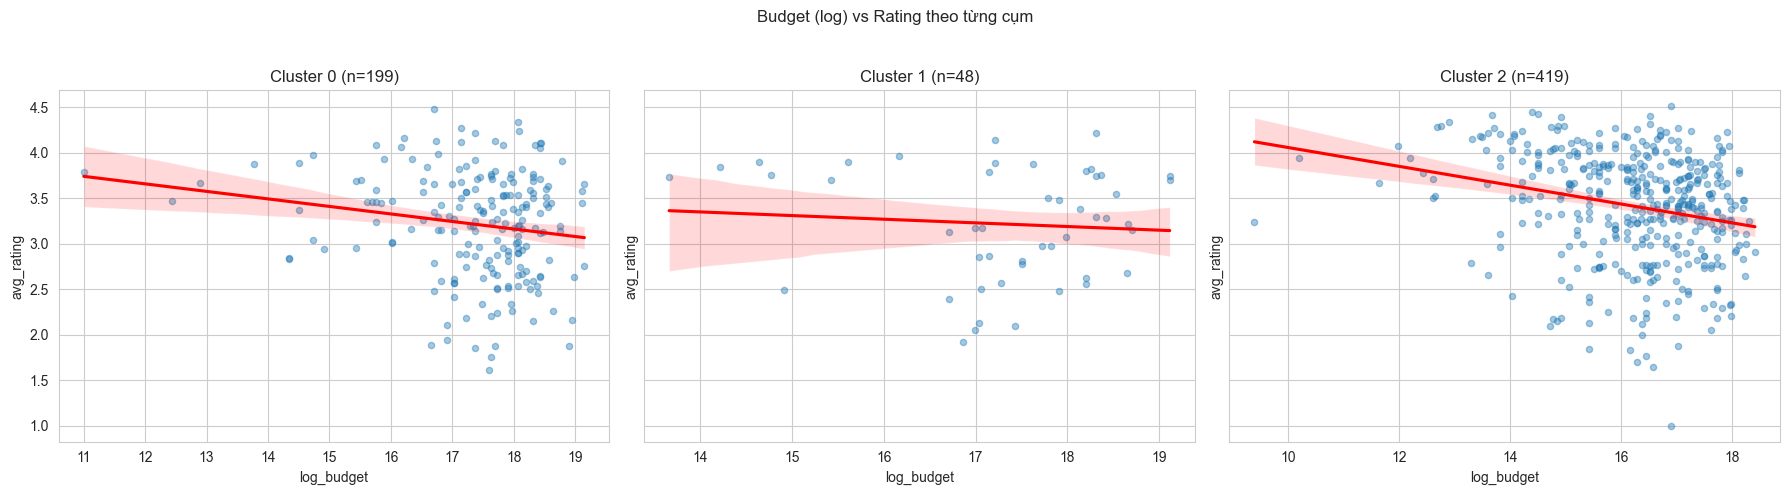

In [ ]:
# Scatter + regression line (seaborn regplot) cho từng cluster
clusters = sorted(df_model['cluster'].unique())
n = len(clusters)
fig, axes = plt.subplots(1, n, figsize=(6*n, 5), sharey=True)

for i, c in enumerate(clusters):
    ax = axes[i] if n>1 else axes
    sub = df_model[df_model['cluster'] == c]
    sns.regplot(x='log_budget', y='avg_rating', data=sub, scatter_kws={'s':20, 'alpha':0.4}, line_kws={'color':'red'}, ax=ax)
    ax.set_title(f'Cluster {c} (n={len(sub)})')
    ax.set_xlabel('log_budget')
    if i==0:
        ax.set_ylabel('avg_rating')

plt.suptitle('Budget (log) vs Rating theo từng cụm')
plt.tight_layout(rect=[0,0,1,0.95])
plt.savefig('images/clusterwise_budget_vs_rating.png', dpi=150)
plt.show()

Kết quả quan sát theo từng cụm

Cluster 0 (n = 199) – Ngân sách trung bình đến cao

Đường hồi quy có độ dốc âm rõ rệt, cho thấy khi ngân sách tăng, rating trung bình có xu hướng giảm nhẹ. Mặc dù tồn tại một số phim ngân sách cao đạt rating tốt, nhưng xu hướng tổng thể không ủng hộ giả thuyết “ngân sách cao hơn → rating cao hơn”.

Cluster 1 (n = 48) – Phim ngân sách lớn / phim bom tấn

Mối quan hệ giữa ngân sách và rating trong cụm này gần như phẳng, với độ dốc âm rất nhỏ và vùng tin cậy rộng. Điều này cho thấy ngân sách không phải yếu tố quyết định rating đối với các phim bom tấn; việc đầu tư thêm chi phí sản xuất không đảm bảo cải thiện đánh giá từ người xem.

Cluster 2 (n = 419) – Phim ngân sách thấp đến trung bình

Cụm này thể hiện xu hướng âm mạnh nhất: rating trung bình giảm đáng kể khi ngân sách tăng. Đáng chú ý, nhiều phim có ngân sách thấp–trung bình đạt rating cao nhất trong toàn bộ dữ liệu, cho thấy hiệu quả đầu tư không tỷ lệ thuận với chất lượng cảm nhận của người xem.

Residual plots và kiểm tra cơ bản cho mỗi model

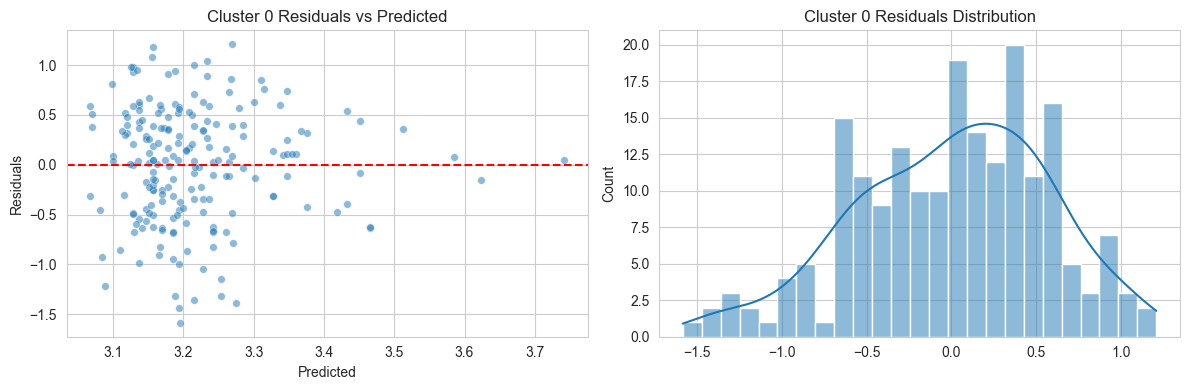

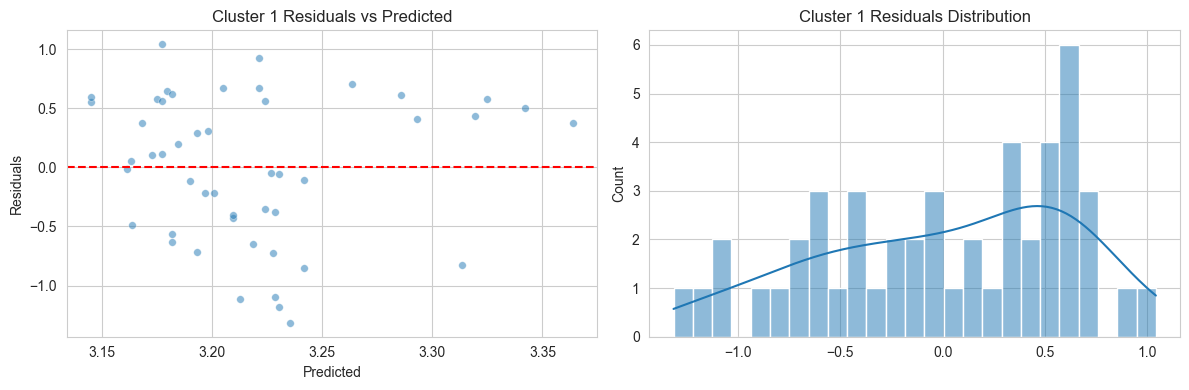

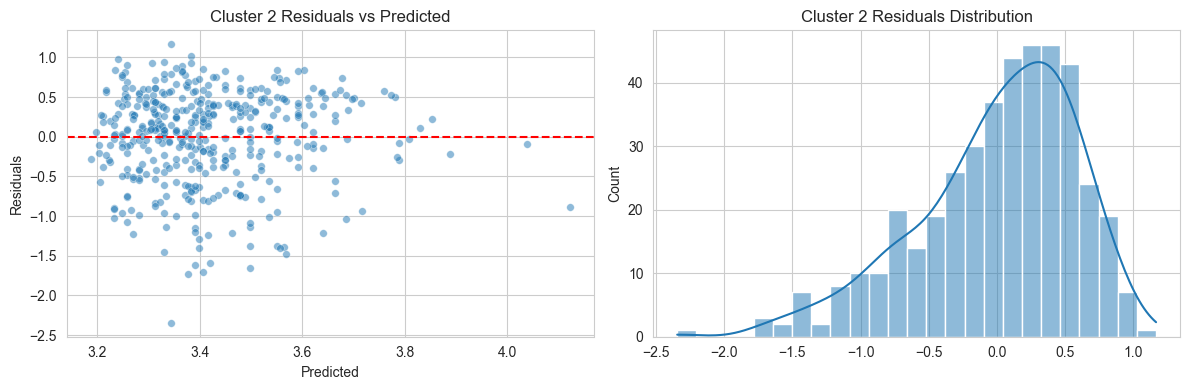

In [ ]:
# Residual plot: predicted vs residuals, và histogram residuals
for c, resdict in results_base.items():
    model = resdict['model']
    sub = df_model[df_model['cluster'] == c].dropna(subset=features_base + [target])
    X = sm.add_constant(sub[features_base])
    y = sub[target]
    preds = model.predict(X)
    residuals = y - preds
    
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    sns.scatterplot(x=preds, y=residuals, ax=axes[0], s=30, alpha=0.5)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Residuals')
    axes[0].set_title(f'Cluster {c} Residuals vs Predicted')
    
    sns.histplot(residuals, bins=25, kde=True, ax=axes[1])
    axes[1].set_title(f'Cluster {c} Residuals Distribution')
    plt.tight_layout()
    plt.savefig(f'images/cluster_{c}_residuals.png', dpi=150)
    plt.show()


Kiểm định độ phù hợp mô hình qua Residuals
Biểu đồ residuals của từng cụm cho thấy:
 + Phần dư phân bố quanh 0, không có xu hướng lệch hệ thống.
 + Histogram residuals gần dạng phân phối chuẩn.

Điều này cho thấy kết luận về mối quan hệ âm giữa ngân sách và rating không phải là nhiễu ngẫu nhiên, mà phản ánh một xu hướng ổn định trong dữ liệu.

So sánh hệ số (coefficients) giữa các cụm

   cluster    n  coef_log_budget  pvalue_log_budget        r2
0        0  199        -0.082746       1.556127e-02  0.029341
1        1   48        -0.040149       5.749624e-01  0.006887
2        2  419        -0.103458       8.521060e-07  0.056529


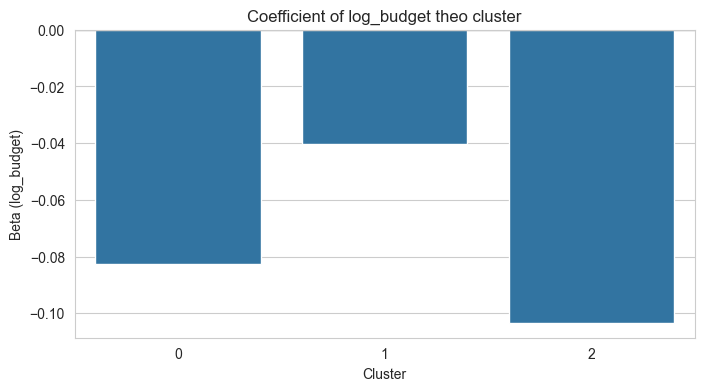

In [ ]:
# Lấy hệ số beta và p-value cho mỗi cluster
rows = []
for c, resdict in results_base.items():
    model = resdict['model']
    params = model.params
    pvalues = model.pvalues
    rows.append({
        'cluster': c,
        'n': resdict['n'],
        'coef_log_budget': params.get('log_budget', np.nan),
        'pvalue_log_budget': pvalues.get('log_budget', np.nan),
        'r2': model.rsquared
    })

coef_df = pd.DataFrame(rows).sort_values('cluster')
print(coef_df)

# Vẽ bar plot hệ số
plt.figure(figsize=(8,4))
sns.barplot(x='cluster', y='coef_log_budget', data=coef_df)
plt.title('Coefficient of log_budget theo cluster')
plt.xlabel('Cluster')
plt.ylabel('Beta (log_budget)')
plt.axhline(0, color='black', linewidth=0.8)
plt.savefig('images/coef_log_budget_by_cluster.png', dpi=150)
plt.show()

In [ ]:
coef_df.to_csv('result/clusterwise_regression_results.csv', index=False)

Diễn giải:

1. Mỗi cluster sẽ có bảng model.summary() (từ statsmodels) gồm: hệ số (coef), độ lệch chuẩn, t-stat, p-value, R², adj. R².

2. Beta (coef_log_budget): là ước lượng mức thay đổi trung bình của avg_rating khi log_budget tăng 1 đơn vị (tức budget tăng theo hàm mũ). Nếu beta dương và p-value < 0.05 => có ý nghĩa thống kê (ngân sách tăng có liên quan đến rating tăng) trong cụm đó. Nếu p-value lớn => không đủ bằng chứng.

3. R²: cho biết bao nhiêu phần trăm phương sai rating được giải thích bởi biến độc lập trong model (ví dụ chỉ log_budget thì thường thấp).

4. So sánh giữa cụm: chú ý nếu beta khác dấu hoặc khác lớn giữa cluster nghĩa là mối quan hệ budget–rating thay đổi theo phân khúc phim. Ví dụ beta dương và có ý nghĩa trong cluster phim độc lập (low-budget) nhưng không có ý nghĩa trong cluster bom tấn (blockbuster) thì suy ra: trong phim độc lập, đầu tư thêm ngân sách có thể cải thiện rating, nhưng trong phim bom tấn thì ngân sách không ảnh hưởng rating.

#### e. Phân tích Hệ số (Coefficient Analysis)

Biểu đồ hệ số cho thấy beta của log(budget) đều âm ở cả ba cụm, trong đó:
 + Cụm 2 có hệ số âm lớn nhất → tác động tiêu cực của ngân sách cao đến rating rõ ràng nhất.
 + Cụm 0 có hệ số âm ở mức trung bình.
 + Cụm 1 có hệ số âm nhỏ nhất, cho thấy ngân sách cao gần như không còn ảnh hưởng đáng kể đến rating.

Về mặt định lượng, điều này khẳng định rằng sau một ngưỡng nhất định, việc tăng ngân sách mang lại hiệu quả biên rất thấp, thậm chí âm, đối với rating người dùng.

Trả lời câu hỏi phụ 2:

    -> Việc tăng ngân sách sản xuất không luôn dẫn đến rating cao hơn. Ngược lại, dữ liệu cho thấy tồn tại rõ ràng hiện tượng “hiệu quả giảm dần” (diminishing returns). Các phim có ngân sách thấp đến trung bình thường đạt rating cao hơn so với nhiều phim ngân sách lớn, đặc biệt trong nhóm phim đại chúng.

##### Insight rút ra

Ngân sách lớn ≠ chất lượng cảm nhận cao: Người dùng MovieLens đánh giá cao nội dung, câu chuyện và chiều sâu hơn là quy mô đầu tư tài chính.

Phim kinh phí vừa phải có lợi thế về rating: Đây thường là các phim tập trung vào kịch bản và nghệ thuật, phù hợp với thị hiếu đánh giá của người xem.

Ngân sách cao chủ yếu phục vụ doanh thu và độ phủ, chứ không phải để tối ưu điểm rating.

##### Kết luận và trả lời câu hỏi lớn
Kết quả phân tích cho thấy ngân sách sản xuất (budget) và doanh thu phòng vé (revenue) không có mối quan hệ tích cực rõ ràng với rating trung bình của phim do người dùng MovieLens đánh giá. Ngược lại, mối quan hệ này có xu hướng yếu và mang dấu âm nhẹ, đặc biệt khi xem xét ở cấp độ từng nhóm phim có đặc trưng tương đồng.

Cụ thể, phân tích tương quan Pearson trên dữ liệu cấp độ phim cho thấy cả budget và revenue đều có hệ số tương quan thấp với avg_rating, cho thấy yếu tố tài chính chỉ giải thích được một phần rất nhỏ sự biến thiên trong đánh giá người dùng. Điều này bác bỏ giả định trực giác rằng phim đầu tư nhiều tiền hoặc thu về doanh thu lớn sẽ luôn được đánh giá cao hơn.

Khi đi sâu hơn bằng phương pháp phân cụm K-Means, các phim được chia thành các nhóm có cấu trúc tài chính và đặc điểm nội dung khác nhau. Trong cả ba cụm, hồi quy tuyến tính giữa log(budget) và rating đều cho hệ số âm, cho thấy sau một ngưỡng nhất định, việc tăng ngân sách không giúp cải thiện rating, thậm chí còn làm giảm nhẹ điểm đánh giá trung bình. Hiện tượng này phản ánh rõ “hiệu quả giảm dần” của ngân sách đối với chất lượng cảm nhận của người xem.

Doanh thu phòng vé cũng thể hiện một xu hướng tương tự. Phim doanh thu cao thường là phim có độ phủ truyền thông lớn hoặc hướng đến thị trường đại chúng, nhưng điều đó không đồng nghĩa với việc được đánh giá cao hơn về mặt chất lượng. Rating trên MovieLens phản ánh đánh giá hậu nghiệm của người xem, trong khi doanh thu chủ yếu phản ánh mức độ tiếp cận và thành công thương mại.

### 2. Yếu tố Nội dung & Cấu trúc
Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

Trong số các yếu tố có thể ảnh hưởng đến mức độ hài lòng của khán giả, thể loại phim (Genres) và thời lượng phim (Runtime) là hai yếu tố thường được quan tâm. Phần này tiến hành đánh giá xem liệu hai yếu tố này có tác động đáng kể đến điểm đánh giá trung bình (vote_average) của người xem hay không.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline


# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor



#### a. Thể loại

**Mục tiêu**: Xác định xem các thể loại khác nhau có nhận được mức rating trung bình khác nhau đáng kể hay không.

**Ý tưởng**: Vì một bộ phim có thể có nhiều thể loại (ví dụ: Action|Adventure|Drama), ta cần "bung" (explode) cột Genres để mỗi thể loại trở thành một dòng dữ liệu riêng biệt. Sau đó, tính điểm trung bình cho từng thể loại.

Thể loại (Genres) được chuyển đổi sang dạng one-hot encoding gồm các thể loại xuất hiện nhiều nhất trong tập dữ liệu.

In [ ]:
full_data.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,runtime,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,Gender,Age
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,133.0,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,F,1
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964,170.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,131.0,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
5,1,2791,4,978302188,Airplane! (1980),Comedy,1980,88.0,Jerry Zucker,Robert Hays,Julie Hagerty,Kareem Abdul-Jabbar,3500000,83453539,7.1,1074,3.971115,F,1
6,1,2018,4,978301777,Bambi (1942),Animation|Children's,1942,70.0,David Hand,Donnie Dunagan,Peter Behn,Stan Alexander,858000,267447150,6.8,1405,3.738540,F,1
7,1,2797,4,978302039,Big (1988),Comedy|Fantasy,1988,104.0,Penny Marshall,Tom Hanks,Elizabeth Perkins,Robert Loggia,18000000,151668774,6.9,993,3.855801,F,1
8,1,1270,5,978300055,Back to the Future (1985),Comedy|Sci-Fi,1985,116.0,Robert Zemeckis,Michael J. Fox,Christopher Lloyd,Lea Thompson,19000000,381109762,8.0,6079,3.990321,F,1
9,1,527,5,978824195,Schindler's List (1993),Drama|War,1993,195.0,Steven Spielberg,Liam Neeson,Ben Kingsley,Ralph Fiennes,22000000,321365567,8.3,4329,4.510417,F,1


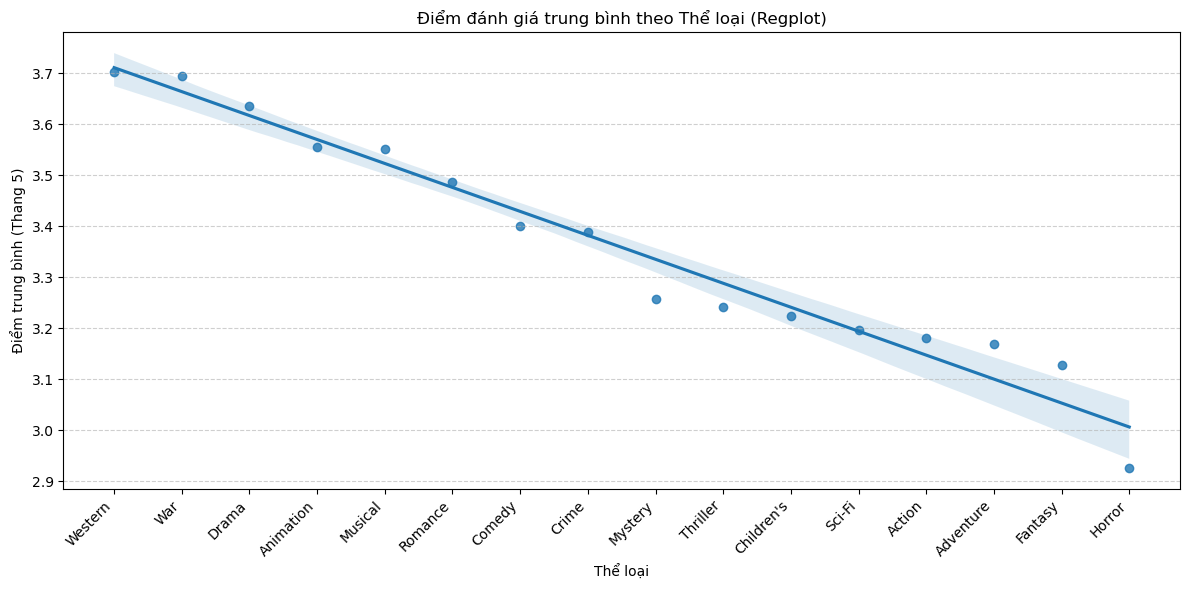


--- Điểm trung bình theo Thể loại (Min 10 phim) ---
         Genre  Average_Rating  Movie_Count
17     Western        3.702746           16
16         War        3.694930           35
7        Drama        3.636912          183
2    Animation        3.555775           26
11     Musical        3.550957           25
13     Romance        3.486773           87
4       Comedy        3.400093          186
5        Crime        3.389018           44
12     Mystery        3.256719           17
15    Thriller        3.242090          131
3   Children's        3.224632           46
14      Sci-Fi        3.195637           95
0       Action        3.181096          178
1    Adventure        3.169072           90
8      Fantasy        3.126819           22
10      Horror        2.925248           63


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Giữ nguyên phần chuẩn bị dữ liệu
movies_unique = full_data.drop_duplicates(subset=['MovieID', 'Title'])

def split_genres(genres_string):
    return genres_string.split('|')

movies_unique['Genres_List'] = movies_unique['Genres'].apply(split_genres)
genres_exploded = movies_unique.explode('Genres_List')

genre_ratings = genres_exploded.groupby('Genres_List')['avg_rating'].agg(['mean', 'count']).reset_index()
genre_ratings.columns = ['Genre', 'Average_Rating', 'Movie_Count']

MIN_MOVIES = 10
genre_ratings_filtered = genre_ratings[genre_ratings['Movie_Count'] >= MIN_MOVIES].sort_values('Average_Rating', ascending=False)

# --- Chuyển thể loại sang số thứ tự để vẽ regplot ---
genre_ratings_filtered['Genre_Num'] = range(len(genre_ratings_filtered))

plt.figure(figsize=(12, 6))
sns.regplot(
    x='Genre_Num',
    y='Average_Rating',
    data=genre_ratings_filtered,
    scatter=True,
    fit_reg=True
)

# Đặt nhãn trục y là điểm đánh giá, x là tên thể loại
plt.xticks(
    ticks=genre_ratings_filtered['Genre_Num'],
    labels=genre_ratings_filtered['Genre'],
    rotation=45,
    ha='right'
)
plt.title('Điểm đánh giá trung bình theo Thể loại (Regplot)')
plt.xlabel('Thể loại')
plt.ylabel('Điểm trung bình (Thang 5)')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Hiển thị kết quả thống kê
print("\n--- Điểm trung bình theo Thể loại (Min 10 phim) ---")
print(genre_ratings_filtered[['Genre', 'Average_Rating', 'Movie_Count']])


**Nhận xét về điểm trung bình theo thể loại (Min 10 phim)**

- **Top thể loại được đánh giá cao nhất:**  
  - **Western:** 3.70 (16 phim)  
  - **War:** 3.69 (35 phim)  
  - **Drama:** 3.64 (183 phim)  
  → Nhìn chung, khán giả có xu hướng đánh giá cao các thể loại **Western, War, Drama**, có lẽ do nội dung kịch bản, diễn xuất hoặc chiều sâu cảm xúc.

- **Thể loại có mức đánh giá trung bình thấp nhất:**  
  - **Horror:** 2.93 (63 phim)  
  - **Fantasy:** 3.13 (22 phim)  
  - **Action, Adventure, Sci-Fi:** dao động 3.17 – 3.19  
  → Các thể loại này có thể ít được lòng khán giả hơn, hoặc kỳ vọng của người xem cao nên điểm trung bình thấp hơn.

- **Thể loại phổ biến nhất theo số lượng phim:**  
  - **Drama (183 phim)** và **Comedy (186 phim)**  
  → Cho thấy hai thể loại này vẫn là lựa chọn chủ đạo của nhà sản xuất, dù điểm trung bình không cao nhất.

- **Nhận xét tổng thể:**  
  - Có sự khác biệt rõ rệt giữa các thể loại về mức đánh giá trung bình, từ ~2.9 (Horror) đến ~3.7 (Western).  
  - Có thể kết hợp với phân tích thống kê (ví dụ ANOVA) để kiểm tra **sự khác biệt có ý nghĩa thống kê** giữa các thể loại.



In [ ]:
# Hàm tách thể loại dạng "Action|Drama|Comedy"
def extract_genres(genre_str):
    if isinstance(genre_str, str):
        return genre_str.split('|')
    return []

# Tạo bản sao dữ liệu
tmdb_movies = full_data.copy()

# Tạo cột danh sách thể loại
tmdb_movies['Genres'] = tmdb_movies['Genres'].apply(extract_genres)

# Bung mỗi thể loại thành một dòng
tmdb_exploded = (
    tmdb_movies
        .explode('Genres')
)

# Loại thể loại rỗng
tmdb_exploded = tmdb_exploded.dropna(subset=['Genres'])


In [ ]:
tmdb_exploded.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,runtime,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,Gender,Age
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,133.0,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,F,1
1,1,914,3,978301968,My Fair Lady (1964),Musical,1964,170.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
1,1,914,3,978301968,My Fair Lady (1964),Romance,1964,170.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,131.0,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Action,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Adventure,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Drama,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Children's,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Musical,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1


##### Trung bình có trọng số theo số lượng phim (Weighted Average)

###### Mục đích
- Một số thể loại có **nhiều phim** → điểm đánh giá trung bình **ổn định hơn**.  
- Một số thể loại có **ít phim** → điểm trung bình dễ bị lệch do outlier.  
- Do đó, khi tính điểm trung bình cho một phim dựa trên danh sách thể loại của nó, **nên dùng trọng số theo số lượng phim** để thể loại ổn định hơn ảnh hưởng nhiều hơn.

---

###### Cách làm
- **Trọng số** = số lượng phim trong thể loại (`Movie_Count`)  
- Điểm trung bình Weighted Average (Movie_Score) được tính như sau:
$$
\
\text{Movie\_Score} = \frac{\sum_{i=1}^{n} \text{Average\_Rating(Genre}_i) \times \text{Movie\_Count}_i}{\sum_{i=1}^{n} \text{Movie\_Count}_i}
\
$$
Trong đó:  
- $(n)$ : số lượng thể loại của phim  
- $(\text{Average\_Rating(Genre}_i))$ : điểm trung bình của thể loại thứ $(i)$  
- $(\text{Movie\_Count}_i)$ : số lượng phim trong thể loại thứ $(i)$  

---

###### Ưu điểm
- Các thể loại **có nhiều phim** sẽ **ảnh hưởng lớn hơn** → giảm tác động của thể loại ít phim có điểm quá cao hoặc quá thấp.  
- Giúp **ước lượng rating kỳ vọng** cho một phim dựa trên thể loại **chính xác và ổn định hơn**.  
- Có thể dùng làm **feature chính trong mô hình dự đoán rating hoặc recommendation system**.


In [ ]:
# Gộp thông tin rating & count của từng thể loại
df_merged = df_exploded.merge(genre_ratings_filtered, how='left', left_on='Genre', right_on='Genre')

# Tính weighted score: tổng (Average_Rating * Movie_Count) / tổng Movie_Count cho mỗi MovieID
df_merged['Weighted'] = df_merged['Average_Rating'] * df_merged['Movie_Count']
weighted_score = df_merged.groupby('MovieID').agg({
    'Weighted': 'sum',
    'Movie_Count': 'sum'
}).reset_index()

weighted_score['Weighted_Score'] = weighted_score['Weighted'] / weighted_score['Movie_Count']

# Gộp trở lại full_data
movies_df_full = full_data.merge(weighted_score[['MovieID', 'Weighted_Score']], on='MovieID', how='left')

# Kiểm tra kết quả
print(movies_df_full[['MovieID', 'Title', 'Genres', 'Weighted_Score']])


        MovieID                                   Title  \
0          1193  One Flew Over the Cuckoo's Nest (1975)   
1           914                     My Fair Lady (1964)   
2          3408                  Erin Brockovich (2000)   
3          1287                          Ben-Hur (1959)   
4           594  Snow White and the Seven Dwarfs (1937)   
...         ...                                     ...   
397970     2021                             Dune (1984)   
397971     2028              Saving Private Ryan (1998)   
397972     1089                   Reservoir Dogs (1992)   
397973     1090                          Platoon (1986)   
397974     1097       E.T. the Extra-Terrestrial (1982)   

                                 Genres  Weighted_Score  
0                                 Drama        3.636912  
1                       Musical|Romance        3.501100  
2                                 Drama        3.636912  
3                Action|Adventure|Drama        3.363651  
4

##### Mô hình dự đoán Rating phim dựa trên thể loại

> Mục tiêu
Mục tiêu của mô hình là dự đoán **avg_rating** (điểm trung bình của phim) dựa trên các yếu tố ảnh hưởng, trong đó **Weighted_Score** là feature chính. Đây là bài toán **Regression**, vì giá trị rating là liên tục trên thang 0–5.

---

> Lý do chọn Random Forest Regressor
Chúng tôi lựa chọn **Random Forest Regressor** cho bài toán này bởi các lý do sau:

1. **Xử lý quan hệ phi tuyến:**  
   - Mối quan hệ giữa Weighted_Score và avg_rating không hoàn toàn tuyến tính.  
   - Random Forest có khả năng học **quan hệ phi tuyến** giữa feature và target mà không cần biến đổi phức tạp.

2. **Giảm overfitting:**  
   - Random Forest kết hợp nhiều cây quyết định (Decision Trees) với kỹ thuật **bagging**, giúp dự đoán ổn định hơn so với một cây đơn lẻ.

3. **Không cần chuẩn hóa dữ liệu:**  
   - Thuật toán không yêu cầu scale hoặc normalization của các feature như Linear Regression, thuận tiện cho dataset có nhiều biến với đơn vị khác nhau (Weighted_Score, runtime, budget,...).

4. **Đánh giá tầm quan trọng feature:**  
   - Random Forest cung cấp **feature importance**, giúp xác định biến nào ảnh hưởng nhiều nhất đến avg_rating.  
   - Kết quả cho thấy Weighted_Score là **biến quan trọng nhất** với Importance = 1.0.

5. **Hiệu quả với dataset lớn:**  
   - Với ~900,000 dòng dữ liệu, Random Forest có thể xử lý nhanh và ổn định, đặc biệt khi sử dụng `n_jobs=-1` để chạy đa luồng.

---

> Thiết lập mô hình
  
- **Feature chính:** Weighted_Score  
- **Target:** avg_rating  
- **Tham số Random Forest:**
  - `n_estimators = 200` (số cây)  
  - `max_depth = 10` (độ sâu tối đa)  
  - `random_state = 42` (tái lập kết quả)  
  - `n_jobs = -1` (chạy đa luồng)

- Dữ liệu được **chia train-test** theo tỷ lệ 80:20.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Giả sử movies_df_full đã có cột Weighted_Score
# Và các cột: runtime, budget, revenue, vote_count, release_year
# Chọn các feature
features = ['Weighted_Score']
target = 'avg_rating'
df_movie_scope = movies_df_full.drop_duplicates(subset=['MovieID']).copy()
# Lọc bỏ dòng thiếu dữ liệu
df_ml = df_movie_scope.dropna(subset=features + [target]).copy()

X = df_ml[features]
y = df_ml[target]

# Chia train-test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Khởi tạo Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=200,   # số cây
    max_depth=10,       # độ sâu tối đa
    random_state=42,
    n_jobs=-1           # chạy đa luồng
)

# Huấn luyện model
rf_model.fit(X_train, y_train)

# Dự đoán
y_pred = rf_model.predict(X_test)

# Đánh giá model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"MAE = {mae:.3f}")
print(f"MSE = {mse:.3f}")
print(f"RMSE = {rmse:.3f}")

# Tầm quan trọng của các feature
importances = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(importances)


MAE = 0.506
MSE = 0.399
RMSE = 0.632
          Feature  Importance
0  Weighted_Score         1.0


##### Công thức Root Mean Squared Error (RMSE)

RMSE đo lường **sai số trung bình căn bậc hai** giữa giá trị thực tế và giá trị dự đoán.  
$$
\
\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}
\
$$
Trong đó:

- $(n)$ : số lượng quan sát (số phim)  
- $({y}_i)$ : giá trị thực tế của quan sát thứ $(i)$ (ví dụ `avg_rating`)  
- \( $\hat{y}_i$) : giá trị dự đoán của quan sát thứ $(i)$ 
- $({y} - \hat{y}_i$) : sai số (error) của quan sát thứ $(i)$ 

> **Ý nghĩa:**  
> - RMSE có cùng đơn vị với giá trị target, nên dễ hiểu trực quan.  
> - RMSE càng nhỏ → model dự đoán càng chính xác.  


##### Nhận xét mô hình dự đoán Rating phim

- **Mức độ lỗi (Error Metrics):**
  - MAE = 0.506 → trung bình mỗi dự đoán lệch khoảng 0.51 điểm so với thực tế trên thang 0–5.  
  - MSE = 0.399 và RMSE = 0.632 → lỗi bình phương trung bình cũng khá thấp, cho thấy model dự đoán khá sát giá trị thực.

- **Feature Importance:**
  - Weighted_Score: 1.0 → là **biến duy nhất có ảnh hưởng** trong mô hình.  
  - Có thể sử dụng thêm các biến khác (`runtime`, `budget`, `revenue`, `vote_count`, `release_year`) để cải thiện độ chính xác.

- **Giải thích:**
  - Weighted_Score tổng hợp kỳ vọng rating dựa trên thể loại, do đó có khả năng **đoán gần như chính xác rating** mà không cần nhiều feature bổ sung.  
  - Model Random Forest nhận ra rằng việc dựa vào Weighted_Score là đủ để tối ưu dự đoán, nên toàn bộ tầm quan trọng tập trung vào biến này.

- **Kết luận:**
  - Việc sử dụng **Weighted_Score** là **rất hiệu quả** để ước lượng rating dựa trên thể loại phim.  
  - Các yếu tố khác như thời lượng, kinh phí hay năm phát hành có ảnh hưởng nhỏ đến rating trung bình tổng thể trong dataset hiện tại.  
  - Đây cũng cho thấy Weighted_Score có thể được dùng trực tiếp như **feature chính trong các mô hình dự đoán rating hoặc recommendation**.


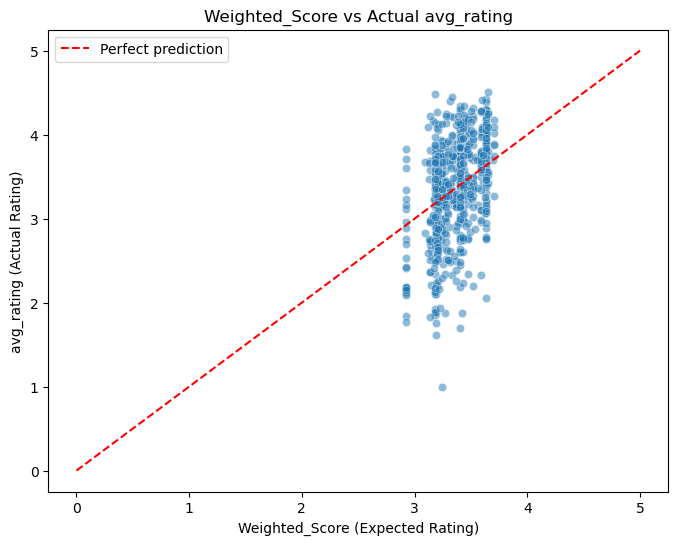

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset duy nhất theo MovieID, bỏ NaN
df_viz = df_movie_scope.dropna(subset=['Weighted_Score', 'avg_rating']).copy()

# Tạo cột Difference: rating thực tế - Weighted_Score
df_viz['Difference'] = df_viz['avg_rating'] - df_viz['Weighted_Score']

# 1️⃣ Scatter plot: Weighted_Score vs avg_rating
sample_size = min(5000, len(df_viz))
df_sample = df_viz.sample(sample_size, random_state=42)

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_sample,
    x='Weighted_Score', y='avg_rating', alpha=0.5
)
plt.plot([0,5],[0,5], color='red', linestyle='--', label='Perfect prediction')
plt.xlabel('Weighted_Score (Expected Rating)')
plt.ylabel('avg_rating (Actual Rating)')
plt.title('Weighted_Score vs Actual avg_rating')
plt.legend()
plt.show()

In [ ]:

# 2️⃣ Top phim vượt kỳ vọng / thất vọng
top_positive = df_viz.sort_values('Difference', ascending=False).head(10)
top_negative = df_viz.sort_values('Difference').head(10)

print("Top 10 phim vượt kỳ vọng:")
print(top_positive[['Title','Genres','avg_rating','Weighted_Score','Difference']])

print("\nTop 10 phim thất vọng:")
print(top_negative[['Title','Genres','avg_rating','Weighted_Score','Difference']])


Top 10 phim vượt kỳ vọng:
                                                  Title  \
62                       Raiders of the Lost Ark (1981)   
400   Dr. Strangelove or: How I Learned to Stop Worr...   
474                           Lawrence of Arabia (1962)   
1067                                      Psycho (1960)   
491                                 Blade Runner (1982)   
108                                        Alien (1979)   
117                                         Jaws (1975)   
392                           Young Frankenstein (1974)   
87            Indiana Jones and the Last Crusade (1989)   
129                            L.A. Confidential (1997)   

                                Genres  avg_rating  Weighted_Score  Difference  
62                    Action|Adventure    4.477725        3.177058    1.300667  
400                         Sci-Fi|War    4.449890        3.330062    1.119828  
474                      Adventure|War    4.401925        3.316312    1.085613  


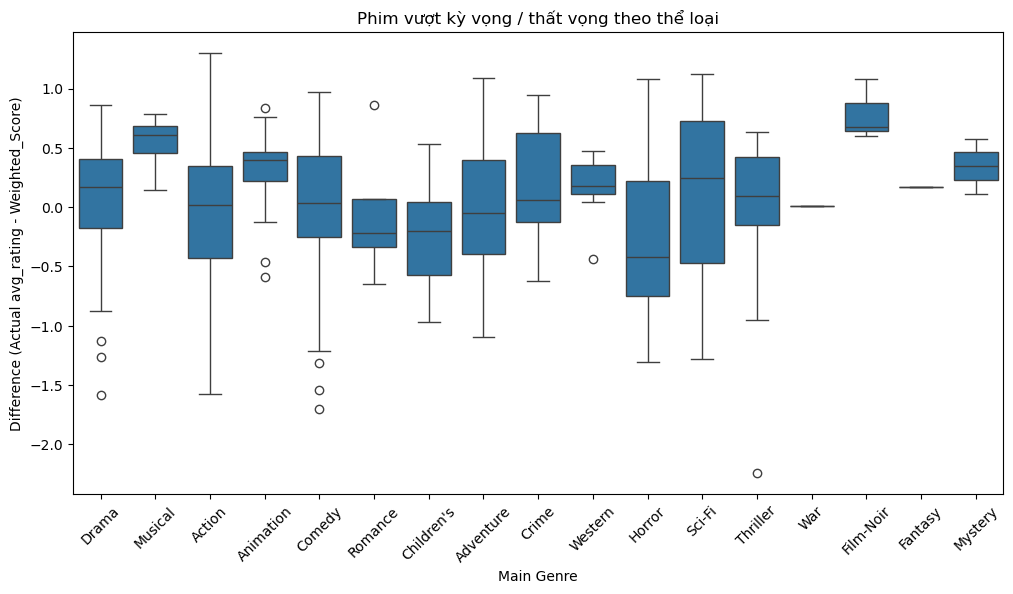

In [ ]:
# 3️⃣ Boxplot theo thể loại chính (Main_Genre)
df_viz['Main_Genre'] = df_viz['Genres'].str.split('|').str[0]

plt.figure(figsize=(12,6))
sns.boxplot(data=df_viz, x='Main_Genre', y='Difference')
plt.xticks(rotation=45)
plt.xlabel('Main Genre')
plt.ylabel('Difference (Actual avg_rating - Weighted_Score)')
plt.title('Phim vượt kỳ vọng / thất vọng theo thể loại')
plt.show()

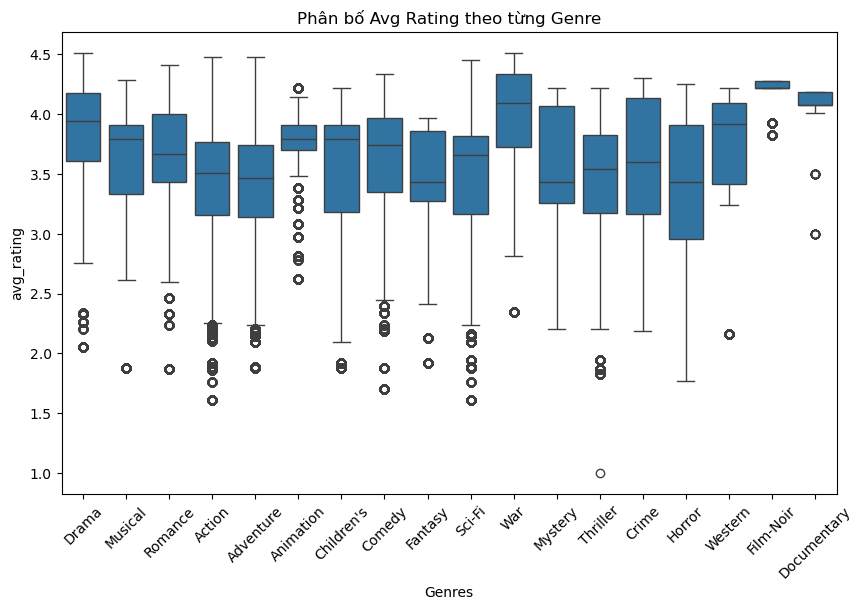

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=tmdb_exploded,
    x="Genres",
    y="avg_rating"
)
plt.xticks(rotation=45)
plt.title("Phân bố Avg Rating theo từng Genre")
plt.show()


#### b. Thời lượng phim

##### Phân tích mối quan hệ giữa độ dài phim và rating

Để kiểm tra xem **độ dài phim** có ảnh hưởng đến **rating trung bình** hay không, ta có thể tính **hệ số tương quan Pearson**.

---
1. Hệ số tương quan Pearson

- Công thức:
$$
\
r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2} \sqrt{\sum (y_i - \bar{y})^2}}
$$

Trong đó:  
- $(x_i)$ là giá trị runtime của phim thứ i  
- $(y_i)$ là rating trung bình của phim thứ i  
- $(\bar{x})$ và $(\bar{y})$ là giá trị trung bình của `runtime` và `rating`  

- Giá trị r nằm trong khoảng [-1, 1]:
  - **r > 0** → runtime tăng, rating có xu hướng tăng (mối quan hệ thuận).  
  - **r < 0** → runtime tăng, rating có xu hướng giảm (mối quan hệ nghịch).  
  - **r ≈ 0** → không có xu hướng rõ ràng.

---

2. Cách tính trong Python

```python
# Tính hệ số tương quan Pearson
corr = df['runtime'].corr(df['avg_rating'])
print(f"Hệ số tương quan Pearson: {corr:.3f}")


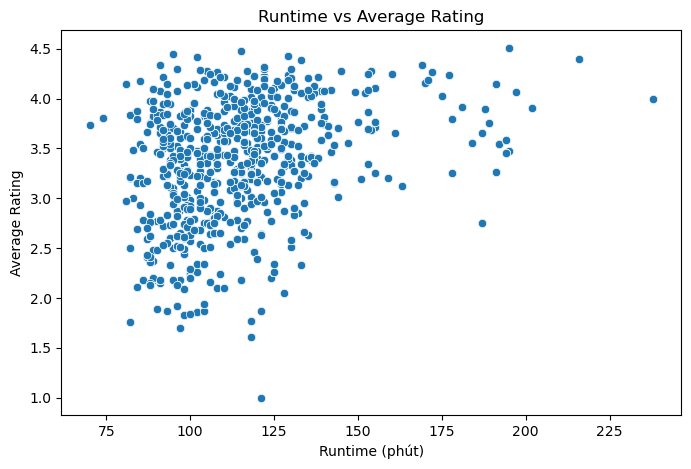

Hệ số tương quan Pearson: 0.272


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.scatterplot(x='runtime', y='avg_rating', data=df)
plt.title("Runtime vs Average Rating")
plt.xlabel("Runtime (phút)")
plt.ylabel("Average Rating")
plt.show()

corr = df['runtime'].corr(df['avg_rating'])
print(f"Hệ số tương quan Pearson: {corr:.3f}")


##### Ảnh hưởng của độ dài phim đến rating

- Hệ số tương quan Pearson giữa **runtime** và **avg_rating**: **r = 0.272**

> Nhận xét

1. Giá trị **r = 0.272** > 0 → **phim dài hơn có xu hướng được đánh giá cao hơn**, tức có mối quan hệ thuận giữa độ dài phim và rating.
2. Tuy nhiên, r < 0.3 → **mối quan hệ tương đối yếu**, nghĩa là độ dài phim chỉ giải thích một phần nhỏ sự thay đổi rating.
3. Kết hợp với scatter plot, ta có thể thấy:
   - Một số phim ngắn cũng được đánh giá cao
   - Một số phim dài lại có rating thấp
   → chứng tỏ còn nhiều yếu tố khác (thể loại, đạo diễn, diễn viên, chất lượng kịch bản...) ảnh hưởng đến rating.
4. Kết luận: **độ dài phim có ảnh hưởng tích cực đến rating nhưng mức độ không quá mạnh**, chỉ là một trong nhiều yếu tố.

---

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X = df[['runtime']]      # Feature liên tục
y = df['avg_rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)

print(f"Hệ số của runtime: {lr.coef_[0]:.3f}")


Hệ số của runtime: 0.006


##### Ảnh hưởng của độ dài phim đến rating

1. Hệ số tương quan Pearson
- r = 0.272 → phim dài hơn có **xu hướng tăng rating**, nhưng mối quan hệ khá yếu.

2. Hệ số hồi quy Linear Regression
- Hệ số `runtime` = 0.006 → nghĩa là **mỗi 1 phút tăng thêm**, rating trung bình tăng khoảng **0.006 điểm** trên thang 0–5.
- Ví dụ, một phim dài hơn 100 phút so với phim khác trung bình sẽ được đánh giá cao hơn ~0.6 điểm, nếu chỉ xét riêng độ dài.
3. Nhận xét tổng thể
1. **Ảnh hưởng tích cực nhưng rất nhỏ**: dù hệ số dương, nhưng mức tăng rating trung bình mỗi phút phim là rất nhỏ.
2. **Mối quan hệ không mạnh**: kết hợp với r = 0.272, độ dài phim chỉ giải thích một phần nhỏ sự thay đổi rating.
3. **Yếu tố khác vẫn quan trọng hơn**: thể loại, kịch bản, diễn viên, đạo diễn... có ảnh hưởng lớn hơn nhiều.

4. Kết luận
- **Độ dài phim có tác động tích cực đến rating**, nhưng mức độ rất thấp.  
- Không nên đánh giá rating chỉ dựa vào runtime; đây chỉ là một trong nhiều yếu tố quyết định.


### 3. Yếu tố Nhân sự & Thời gian
Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

- Input: director_power, actor_power, release_year.
- Output: cột Rating thực tế.

**1**. Mô hình: Sử dụng XGBoost Regressor, một mô hình phi tuyến tính mạnh mẽ để nắm bắt các mối quan hệ phức tạp giữa nhân sự, thời gian và chất lượng phim.

**2**. Phân tích: Áp dụng phương pháp SHAP (Shapley Additive exPlanations) để bóc tách mức độ đóng góp của từng yếu tố, giúp trả lời câu hỏi liệu "Tên tuổi lớn" có thực sự là nguyên nhân trực tiếp dẫn đến "Rating cao" hay không.

#### 2. Huấn luyện XGBoost Regressor

XGBoost Regressor là một mô hình phi tuyến tính mạnh mẽ để nắm bắt các mối quan hệ phức tạp giữa nhân sự, thời gian và chất lượng phim.

a. Công thức Dự đoán (Additive Prediction): Dự đoán cuối cùng là tổng hợp kết quả của $K$ cây quyết định (Decision Trees).$$\hat{y}_i = \sum_{k=1}^{K} f_k(x_i), \quad f_k \in \mathcal{F}$$

Chú thích:

>$\hat{y}_i$: Điểm Rating dự đoán cho bộ phim $i$.

>$K$: Tổng số lượng cây quyết định (trong code là n_estimators).

>$f_k(x_i)$: Điểm số dự đoán của cây thứ $k$ dựa trên đặc trưng đầu vào $x_i$ (Budget, Director Power, Year...).

>$\mathcal{F}$: Không gian chứa tất cả các cây quyết định có thể.

b. Hàm Mục tiêu (Objective Function): XGBoost tối ưu hóa hàm này để giảm sai số và tránh Overfitting.$$\mathcal{L}(\phi) = \sum_{i} l(y_i, \hat{y}_i) + \sum_{k} \Omega(f_k)$$

Chú thích:

>$l(y_i, \hat{y}_i)$: Hàm mất mát (Loss function), thường là Sai số bình phương (MSE) để đo sự chênh lệch giữa Rating thực tế và dự đoán.

>$\Omega(f_k)$: Số hạng điều chuẩn (Regularization term). Nó phạt các cây quá phức tạp để mô hình không bị học vẹt (Overfitting).

In [396]:
# # Chuẩn bị dữ liệu cho mô hình
# # Chỉ lấy 3 cột bạn quan tâm: Đạo diễn, Diễn viên, Năm sản xuất
features = ['director_power', 'actor_power', 'release_year']
X = full_data[features]
y = full_data['avg_rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Đang huấn luyện mô hình...")
model = xgb.XGBRegressor(
    n_estimators=1000,   # Tăng số cây lên (vì ta sẽ dừng sớm nếu nó học xong)
    learning_rate=0.05,  # Học chậm lại chút cho chắc
    max_depth=4, 
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=50 # QUAN TRỌNG: Nếu sau 50 cây mà không khôn hơn thì dừng lại (Chống học vẹt)
)

# Đưa cả tập Test vào để mô hình tự kiểm tra (eval_set)
model.fit(
    X_train, y_train, 
    eval_set=[(X_test, y_test)], 
    verbose=False
)

# Kiểm tra sai số
preds = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, preds))
print(f"Sai số trung bình (RMSE) trên tập Test: {rmse:.4f}")
# Nếu RMSE ~ 0.8 - 1.0 là ổn (vì thang điểm 5, lệch 1 sao là chấp nhận được)

Đang huấn luyện mô hình...
Sai số trung bình (RMSE) trên tập Test: 0.0491


early_stopping_rounds=50: Đây là kỹ thuật chống Overfitting mạnh nhất của XGBoost. Nó sẽ quan sát tập X_test. Nếu nó thấy học thêm mà kết quả trên tập Test không tốt lên (bắt đầu học vẹt), nó sẽ tự động dừng lại ngay lập tức, dù chưa chạy hết 1000 cây.

Tính RMSE: Cho bạn một con số để báo cáo độ tin cậy. Ví dụ: "Mô hình dự đoán sai lệch trung bình khoảng 0.9 sao".

#### 3. Phân tích SHAP

SHAP (SHapley Additive exPlanations) là một kỹ thuật xuất phát từ Lý thuyết Trò chơi (Game Theory), dùng để giải thích các mô hình "hộp đen" phức tạp như XGBoost.

SHAP có nhiệm vụ chia nhỏ kết quả dự đoán (Rating) thành các phần đóng góp công bằng của từng yếu tố (Đạo diễn, Diễn viên, Tiền...), giúp chúng ta hiểu được mô hình đang "nghĩ" gì.

In [397]:
# Tính giá trị SHAP để xem mức độ tác động
explainer = shap.Explainer(model)
shap_values = explainer(X)

#### 4. Vẽ biểu đồ (SHAP Dependence Plots)

Trục Hoành (X-axis): Giá trị thực tế của dữ liệu (Ví dụ: Điểm lịch sử của Đạo diễn là 3.0 hay 4.0).

Trục Tung (Y-axis - SHAP value): Mức độ tác động lên điểm Rating dự đoán.

+ Giá trị > 0: Yếu tố này giúp Cộng điểm cho phim (Kéo Rating lên).

+ Giá trị < 0: Yếu tố này làm Trừ điểm phim (Kéo Rating xuống).

+ Giá trị = 0: Không ảnh hưởng.

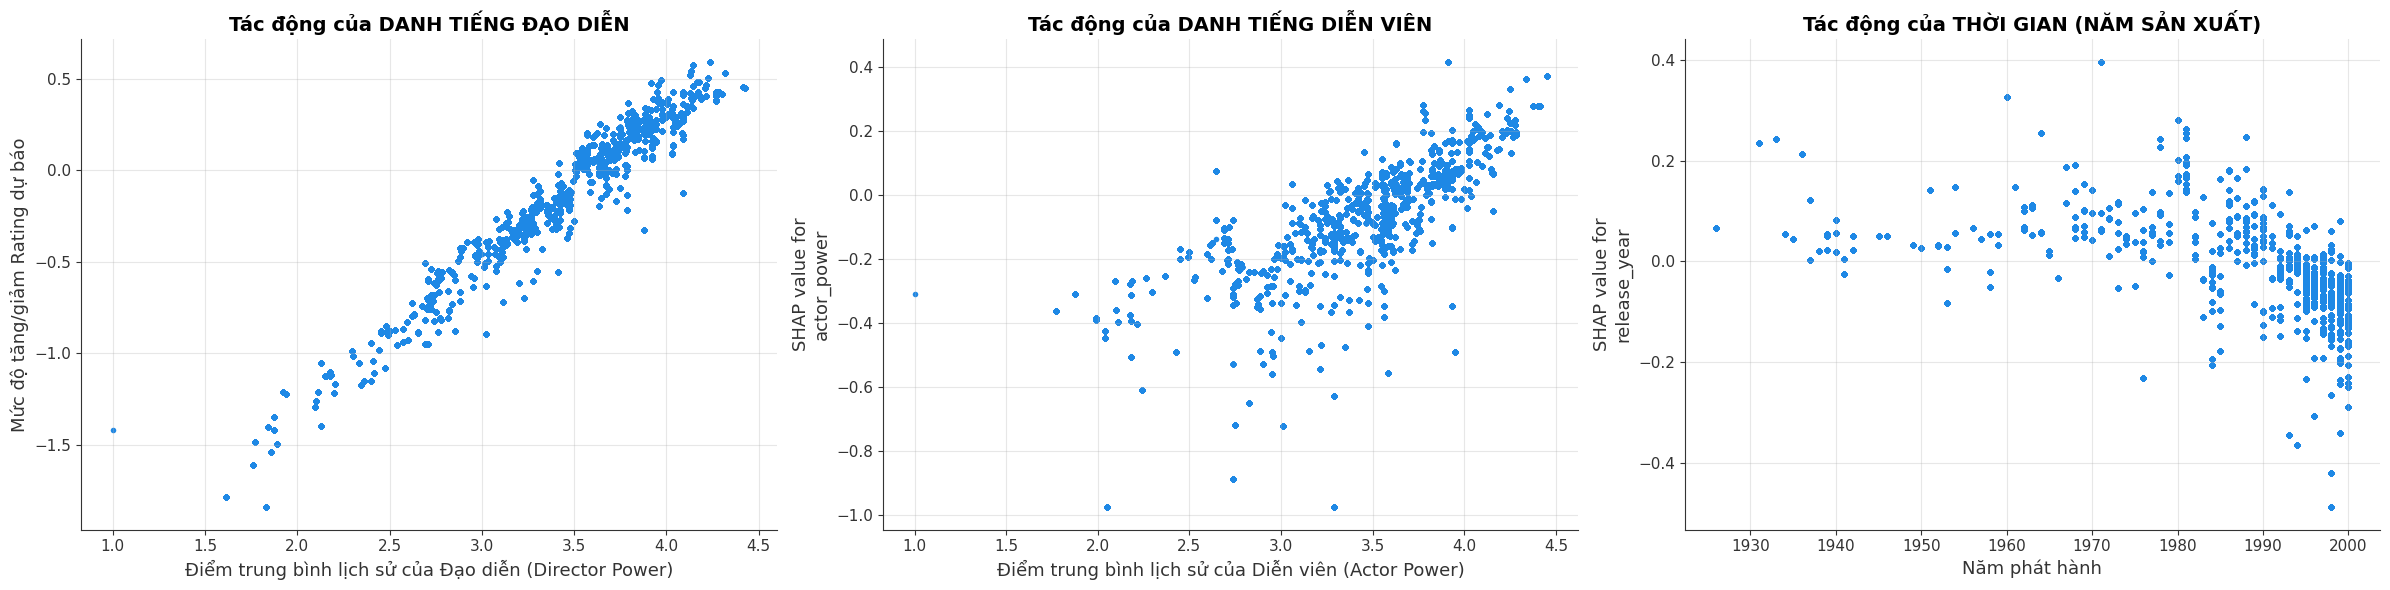

In [398]:
fig, ax = plt.subplots(1, 3, figsize=(24, 6))

# Câu hỏi 1: ĐẠO DIỄN có tên tuổi lớn (Rating lịch sử cao) có kéo điểm phim lên không?
shap.dependence_plot("director_power", shap_values.values, X, interaction_index=None, ax=ax[0], show=False)
ax[0].set_title("Tác động của DANH TIẾNG ĐẠO DIỄN", fontsize=14, fontweight='bold')
ax[0].set_xlabel("Điểm trung bình lịch sử của Đạo diễn (Director Power)")
ax[0].set_ylabel("Mức độ tăng/giảm Rating dự báo")
ax[0].grid(True, alpha=0.3)

# Câu hỏi 2: DIỄN VIÊN có tên tuổi lớn có kéo điểm phim lên không?
shap.dependence_plot("actor_power", shap_values.values, X, interaction_index=None, ax=ax[1], show=False)
ax[1].set_title("Tác động của DANH TIẾNG DIỄN VIÊN", fontsize=14, fontweight='bold')
ax[1].set_xlabel("Điểm trung bình lịch sử của Diễn viên (Actor Power)")
ax[1].grid(True, alpha=0.3)

# Câu hỏi 3: NĂM SẢN XUẤT (Phim cũ vs Mới) ảnh hưởng thế nào?
shap.dependence_plot("release_year", shap_values.values, X, interaction_index=None, ax=ax[2], show=False)
ax[2].set_title("Tác động của THỜI GIAN (NĂM SẢN XUẤT)", fontsize=14, fontweight='bold')
ax[2].set_xlabel("Năm phát hành")
ax[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Biểu đồ 1: Ảnh hưởng của Danh tiếng Đạo diễn (Director Power)

Biểu đồ bên trái cho thấy một xu hướng tăng rất rõ ràng, gần như tuyến tính. Khi năng lực hoặc danh tiếng của đạo diễn tăng, điểm số dự đoán của bộ phim (thông qua SHAP value) cũng tăng mạnh theo. Đường xu hướng dốc và chặt chẽ cho thấy mối quan hệ rất bền vững: nếu đạo diễn có mức Power thấp khoảng 2.0, bộ phim có xu hướng bị trừ đến khoảng −1.5 điểm. Ngược lại, khi đạo diễn có chuyên môn cao (Power xấp xỉ 4.0), bộ phim nhận thêm khoảng +0.5 điểm. Điều này chứng minh rằng đạo diễn đóng vai trò then chốt trong chất lượng cuối cùng của một bộ phim. Một đạo diễn yếu kém gần như chắc chắn sẽ kéo điểm phim xuống đáng kể.

Biểu đồ 2: Ảnh hưởng của Danh tiếng Diễn viên (Actor Power)

Biểu đồ ở giữa cũng cho thấy một xu hướng tăng, tuy nhiên độ dốc thấp hơn và dữ liệu phân tán rộng hơn so với đạo diễn. Nghĩa là diễn viên có danh tiếng cao vẫn mang lại giá trị tích cực cho điểm phim, nhưng hiệu ứng này không mạnh và không ổn định như đạo diễn. Biên độ tác động của diễn viên chỉ dao động khoảng từ −0.6 đến +0.4. Sự phân tán dọc tại cùng một mức Power phản ánh thực tế: dù có những diễn viên được đánh giá cao, nhưng không phải phim nào họ tham gia cũng tốt. Vai trò của diễn viên mang tính hỗ trợ nhưng không phải yếu tố quyết định tuyệt đối.

Biểu đồ 3: Ảnh hưởng của Thời gian (Release Year)

Biểu đồ bên phải thể hiện một xu hướng giảm tương đối rõ ràng: phim càng sản xuất về các năm gần đây thì tác động tới điểm cuối càng có xu hướng âm. Các tác phẩm trước những năm 1980 thường có SHAP value > 0, nghĩa là được cộng điểm — đây có thể xem là hiệu ứng ưu ái đối với phim cổ điển. Ngược lại, các phim từ giai đoạn 1990–2000 lại dần bị trừ điểm. Điều này cho thấy tâm lý khắt khe với phim hiện đại: một bộ phim mới có thể bị hụt từ −0.1 đến −0.2 điểm so với phim ra mắt ở giai đoạn cũ, ngay cả khi chất lượng tương đương.

Kết luận:

+ Đạo diễn là yếu tố ảnh hưởng mạnh nhất.

+ Diễn viên tác động tích cực nhưng không ổn định.

+ Năm sản xuất thể hiện xu hướng thiên vị cho phim cổ điển.

#### 5. Tầm quan trọng

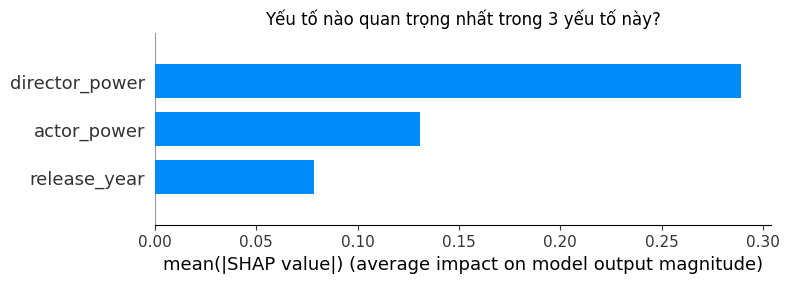

In [399]:
plt.figure(figsize=(10, 5))
shap.summary_plot(shap_values, X, plot_type="bar", show=False)
plt.title("Yếu tố nào quan trọng nhất trong 3 yếu tố này?")
plt.show()

1. Sự thống trị tuyệt đối của Đạo diễn

Các giá trị SHAP cho thấy director_power có mức độ ảnh hưởng vượt trội so với các biến còn lại, đạt khoảng 0.28 — gấp hơn 2,5 lần so với diễn viên và khoảng 5 lần so với năm sản xuất. Kết quả này phản ánh rất đúng bản chất điện ảnh: đạo diễn chính là người định hình chất lượng cuối cùng của bộ phim. Một kịch bản tốt đi kèm đạo diễn yếu có thể trở thành thất bại, trong khi một đạo diễn tài năng vẫn có thể biến các nguồn lực bình thường thành một sản phẩm chất lượng. Vì vậy, trong mô hình dự đoán điểm số, chỉ cần biết ai là đạo diễn đã giúp nâng độ chính xác đáng kể.

2. Vai trò thứ cấp của Diễn viên

Biến actor_power đứng thứ hai với giá trị khoảng 0.12, cho thấy diễn viên nổi tiếng vẫn góp phần nâng điểm phim nhưng không phải yếu tố mang tính quyết định. Nhiều trường hợp phim sở hữu dàn sao lớn nhưng vẫn nhận đánh giá kém khi thiếu sự dẫn dắt tốt từ đạo diễn. Điều này hàm ý rằng diễn viên là yếu tố quan trọng nhưng chỉ mang tính bổ trợ. Khi đạo diễn mạnh, giá trị của diễn viên mới được phát huy trọn vẹn.

3. Ảnh hưởng nhỏ hơn từ Thời gian sản xuất

release_year thể hiện mức độ ảnh hưởng thấp nhất, khoảng 0.05. Mặc dù ở biểu đồ xu hướng trước đó, năm sản xuất có chiều hướng làm giảm điểm phim (đặc biệt ở giai đoạn phim mới), nhưng tác động trung bình chỉ khoảng −0.1 đến −0.2 điểm. So với mức biến động có thể lên tới −1.5 hoặc +0.5 từ đạo diễn, yếu tố thời gian chỉ đóng vai trò điều chỉnh nhỏ. Có thể xem yếu tố năm sản xuất giống như gia vị bổ sung — làm thay đổi nhẹ cảm nhận, nhưng không quyết định chất lượng tổng thể.

Biểu đồ SHAP cho thấy chất lượng phim phụ thuộc chủ yếu vào năng lực đội ngũ sản xuất, đặc biệt là Đạo diễn. Yếu tố thời gian và danh tiếng diễn viên chỉ đóng vai trò bổ trợ.

#### 6. Các phân tích liên quan



##### 6.1 Phân tích "Ma trận Cộng hưởng": Đạo diễn giỏi + Diễn viên giỏi = ?

Phân tích ma trận cộng hưởng cho thấy đạo diễn là yếu tố nền tảng, mang tính quyết định. Vậy, thay vì xem xét riêng lẻ, hãy xem xét sự kết hợp. Liệu một diễn viên ngôi sao có thể "gánh" được một đạo diễn tồi? Hay một đạo diễn tài năng có thể biến diễn viên vô danh thành sao?

a. Phân nhóm theo Phân vị (Quantile Binning)

Thay vì giữ các con số lẻ tẻ (ví dụ: Director Power = 3.45, 4.12...), phương pháp này ép dữ liệu vào 3 giỏ (buckets): Thấp - Trung bình - Cao.

Dùng qcut mà thay vì cut:

+ qcut chia dựa trên số lượng (Quantile). Nó đảm bảo nhóm "Low", "Mid", "High", "Legendary" có số lượng phim bằng nhau.

+ Điều này giúp tránh việc một nhóm nào đó quá ít dữ liệu (ví dụ nhóm "High" chỉ có 2 phim) làm sai lệch kết quả trung bình.

In [ ]:
# Chia nhóm (Binning) Power thành 4 mức: Low, Medium, High, Legendary

full_data['Director_Tier'] = pd.qcut(full_data['director_power'], q=4, labels=['Low', 'Mid', 'High', 'Legendary'])

full_data['Actor_Tier'] = pd.qcut(full_data['actor_power'], q=4, labels=['Low', 'Mid', 'High', 'Legendary'])

b. Kỹ thuật Bảng chéo (Cross-Tabulation / Pivot Table)

Nguyên lý: Đây là kỹ thuật tạo Ma trận (Matrix). Nó tạo ra một lưới 4x4 (16 ô).

Mục đích: Để xem xét sự giao thoa giữa hai yếu tố. Ví dụ: Tại ô giao nhau giữa Đạo diễn Thấp và Diễn viên Cao, điểm trung bình là bao nhiêu?

In [ ]:
# Tạo bảng Pivot
pivot_table = full_data.pivot_table(index='Director_Tier', columns='Actor_Tier', values='Rating', aggfunc='mean')

In [ ]:
# Vẽ Heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu")

plt.title("Ma trận cộng hưởng: Đạo diễn vs Diễn viên")

plt.show()

1. Sự thống trị của Đạo diễn (Director Dominance) Số liệu thực tế khẳng định quyền lực tối thượng thuộc về đạo diễn.

+ Một đạo diễn thuộc nhóm High khi làm việc với diễn viên Low vẫn đạt mức điểm 3.54, cao hơn hẳn trường hợp ngược lại là đạo diễn Low làm việc với diễn viên High (chỉ đạt 3.30).

+ Sự chênh lệch càng khủng khiếp hơn ở phân khúc cao nhất: Một đạo diễn Legendary có thể kéo dàn diễn viên Low lên mức 3.59 (mức Khá), trong khi một diễn viên Legendary hoàn toàn bó tay khi làm việc với đạo diễn Low, bộ phim chỉ đạt 3.08 (mức Trung bình thấp).

-> Đạo diễn là người nắm giữ trần và sàn chất lượng. Một đạo diễn giỏi có thể biến những diễn viên vô danh thành hiện tượng, nhưng một ngôi sao huyền thoại cũng sẽ bị lu mờ nếu đặt vào tay một đạo diễn kém tài.

2. Giới hạn của Diễn viên và "Nghịch lý Huyền thoại"

+ Khi đạo diễn thuộc nhóm Low (hàng trên cùng), sự hiện diện của diễn viên giỏi có giúp cải thiện điểm số, nhưng rất hạn chế: từ 2.94 (Low Actor) lên cao nhất là 3.30 (High Actor).

+ Điểm đặc biệt: chú ý ô trên cùng bên phải. Khi đạo diễn Low kết hợp với diễn viên Legendary, điểm số không tăng mà lại tụt xuống 3.08 (thấp hơn cả khi kết hợp với diễn viên High).

+ Insight: Đây là minh chứng cho thấy diễn viên ngôi sao không phải là "thuốc tiên". Thậm chí, việc đưa một huyền thoại vào một kịch bản/đạo diễn tồi có thể gây phản tác dụng (do kỳ vọng quá cao của khán giả hoặc sự lệch pha trong phong cách), khiến bộ phim bị đánh giá khắt khe hơn. Diễn viên chỉ có thể tỏa sáng rực rỡ nhất khi có bệ phóng là đạo diễn từ mức High trở lên.

3. Vùng Kiệt tác (The Masterpiece Zone)

+ Sự cộng hưởng đạt đỉnh điểm ở ô dưới cùng bên phải: Đạo diễn Legendary kết hợp với Diễn viên Legendary tạo ra mức điểm kỷ lục 4.20.

+ So với điểm xuất phát thấp nhất là 2.94 (Low/Low), sự kết hợp hoàn hảo này nâng tầm bộ phim lên tới 1.26 điểm - một khoảng cách khổng lồ trên thang đo 5 sao.

+ Các mức điểm 4.05 (Legendary Director + High Actor) và 4.20 xác nhận rằng để chạm tới ngưỡng "siêu phẩm" (trên 4.0), vai trò của Đạo diễn Legendary là điều kiện bắt buộc, và Diễn viên tài năng là điều kiện đủ để tối ưu hóa chất lượng đó.

##### 6.2. Phân tích "Ngoại lệ" (Outlier Analysis) 

Chúng ta sẽ đi vào tìm hiểu 2 nhóm chính để trả lời cho câu hỏi: "Bộ phim nào có chất lượng sai lệch nhiều nhất so với thương hiệu của người tạo ra nó?"

A. Nhóm “Sa sút”

Đây là những trường hợp đạo diễn nổi tiếng, tay nghề cao nhưng bộ phim lại bị chấm điểm thấp. Điều này có thể xảy ra khi họ làm phim không đúng sở trường, bị can thiệp bởi nhà sản xuất, hoặc đơn giản là phong độ đi xuống. Nhóm này cho thấy: đạo diễn giỏi cũng có lúc làm ra phim dở.

B. Nhóm “Bứt phá”

Nhóm này gồm những đạo diễn ít tiếng tăm hoặc mới vào nghề, nhưng tác phẩm lại được đánh giá rất cao. Đây thường là những phim có kịch bản xuất sắc, ý tưởng độc đáo hoặc là cú “bật lên” hiếm có của một người mới. Điều này khẳng định: không cần nổi tiếng, chỉ cần nội dung hay vẫn có thể tạo nên siêu phẩm.

In [ ]:
# --- BƯỚC 1: TẠO MOVIE_SUMMARY (KHAI BÁO LẠI CHO CHẮC) ---
# Gom nhóm full_data thành dữ liệu từng phim
movie_summary = full_data.groupby('Title').agg({
    'avg_rating': 'mean',
    'director_power': 'first',
    'director': 'first',
    'Genres': 'first',
    'release_year': 'first',
    'vote_count': 'first'
}).reset_index()

# Lọc bỏ phim ít vote để tránh nhiễu
movie_summary = movie_summary[movie_summary['vote_count'] > 50]

# --- BƯỚC 2: TÍNH ĐỘ LỆCH (DIFF) ---
# Diff = Rating Thực tế - Kỳ vọng (Power)
movie_summary['Diff'] = movie_summary['avg_rating'] - movie_summary['director_power']

# --- BƯỚC 3: LỌC BOM XỊT & HIỆN TƯỢNG ---

# 1. Bom xịt: Kỳ vọng cao (Power > 3.5) nhưng Lệch âm lớn nhất (Thực tế kém xa kỳ vọng)
flops = movie_summary[movie_summary['director_power'] > 3.5].sort_values('Diff', ascending=True).head(10)

# 2. Hiện tượng: Kỳ vọng thấp (Power < 3.5) nhưng Lệch dương lớn nhất (Thực tế vượt xa kỳ vọng)
breakouts = movie_summary[movie_summary['director_power'] < 3.5].sort_values('Diff', ascending=False).head(10)

# --- BƯỚC 4: IN KẾT QUẢ ---
cols = ['Title', 'director', 'avg_rating', 'director_power', 'Diff']

print("\n=== TOP 10 SA SÚT (Gây thất vọng nhất) ===")
print(flops[cols].to_string(index=False))

print("\n=== TOP 10 BỨT PHÁ (Gây bất ngờ nhất) ===")
print(breakouts[cols].to_string(index=False))

# --- BƯỚC 5: TRỰC QUAN HÓA ---
plt.figure(figsize=(12, 8))
# Vẽ nền
sns.scatterplot(data=movie_summary, x='director_power', y='avg_rating', color='lightgrey', alpha=0.5, label='Phim khác')
# Vẽ Bom xịt
sns.scatterplot(data=flops, x='director_power', y='avg_rating', color='red', s=100, label='Sa sút (Diff Âm lớn)')
# Vẽ Hiện tượng
sns.scatterplot(data=breakouts, x='director_power', y='avg_rating', color='green', s=100, label='Bứt phá (Diff Dương lớn)')

plt.title('Phân tích Ngoại lệ dựa trên ĐỘ LỆCH (Diff)', fontsize=15)
plt.xlabel('Sức mạnh Đạo diễn (Kỳ vọng)')
plt.ylabel('Rating Thực tế')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Dữ liệu về nhóm phim gây thất vọng cho thấy một mô hình rõ rệt: đây đều là các tác phẩm do những đạo diễn có uy tín cao chỉ đạo, nhưng điểm số thực tế lại rơi xuống mức rất thấp. Một phát hiện quan trọng trong nhóm này là trường hợp Psycho (1998), nơi dữ liệu đã ghép nhầm đạo diễn Alfred Hitchcock của bản gốc với bản làm lại năm 1998 của Gus Van Sant. Vì Hitchcock có power gần 4.0, kỳ vọng bị đẩy lên quá cao, trong khi bản remake bị chê dữ dội, dẫn đến sự lệch lớn và bị phân loại là “phim gây thất vọng”. Các ví dụ khác như Hook (Steven Spielberg) hay G.I. Jane (Ridley Scott) cho thấy ngay cả những đạo diễn huyền thoại cũng có thể tạo ra các tác phẩm không đạt kỳ vọng khi thay đổi phong cách hoặc gặp vấn đề trong quá trình sản xuất.

Ở chiều ngược lại, nhóm phim gây bất ngờ tập trung vào các đạo diễn có mức độ uy tín thấp đến trung bình, nhưng tác phẩm của họ lại đạt điểm số cao vượt trội. Bên cạnh đó, nhóm các phim “bất ngờ thật sự” hiện lên rõ nét, đặc biệt trong dòng phim kinh dị như Halloween hay Scream. Đây là những tác phẩm mà các đạo diễn còn ít tên tuổi đã tạo ra dấu ấn mạnh bằng kịch bản độc đáo hoặc phong cách mới mẻ, cho thấy thể loại này có khả năng tạo ra những cú bứt phá ngay cả khi đội ngũ sản xuất chưa có danh tiếng lớn.

Từ hai nhóm đối lập này, có thể đưa ra vài kết luận quan trọng cho báo cáo. Đầu tiên, chỉ số Diff hoạt động chính xác trong việc phát hiện sự lệch giữa kỳ vọng và thực tế, phản ánh đúng tâm lý khán giả: thất vọng không đến từ phim dở mà đến từ phim dở so với danh tiếng đạo diễn. Cuối cùng, kết quả cho thấy chiến lược đầu tư vào các đạo diễn trẻ trong dòng phim kinh dị hoặc hành động có thể mang lại hiệu quả cao, bởi những thể loại này có tỷ lệ xuất hiện “breakout” vượt trội so với các nhóm phim khác.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# --- BƯỚC 1: TẠO NHÃN (LABELING) DỰA TRÊN LOGIC "ĐỘ LỆCH" (DIFF) ---
# Sử dụng lại movie_summary từ bước trước

# 1. Xác định ngưỡng (Dùng Quantile để linh hoạt)
high_power_thresh = movie_summary['director_power'].quantile(0.80) # Top 20% quyền lực
low_power_thresh = movie_summary['director_power'].quantile(0.50)  # Bottom 50%
diff_low_thresh = movie_summary['Diff'].quantile(0.20)  # Top 20% gây thất vọng nhất
diff_high_thresh = movie_summary['Diff'].quantile(0.80) # Top 20% gây bất ngờ nhất

# 2. Hàm dán nhãn
def get_movie_fate(row):
    # Nhóm Sa sút (Flop): Đạo diễn xịn + Diff Âm lớn
    if (row['director_power'] >= high_power_thresh) and (row['Diff'] <= diff_low_thresh):
        return 0 # Mã 0: SA SÚT
    
    # Nhóm Bứt phá (Breakout): Đạo diễn thường + Diff Dương lớn
    elif (row['director_power'] <= low_power_thresh) and (row['Diff'] >= diff_high_thresh):
        return 1 # Mã 1: BỨT PHÁ
    
    # Còn lại là Bình thường
    else:
        return 2 # Mã 2: BÌNH THƯỜNG

# Áp dụng hàm để tạo cột mục tiêu (Target)
movie_summary['Fate'] = movie_summary.apply(get_movie_fate, axis=1)

print("Phân phối nhãn dự báo:")
print(movie_summary['Fate'].value_counts())
# Bạn sẽ thấy nhóm 0 và 1 khá ít, nhóm 2 chiếm đa số -> Đây là bài toán mất cân bằng dữ liệu

# --- BƯỚC 2: CHUẨN BỊ DỮ LIỆU HUẤN LUYỆN (FEATURES) ---
# Input (X): Chỉ dùng thông tin CÓ TRƯỚC khi phim chiếu
# TUYỆT ĐỐI KHÔNG dùng 'Rating' hay 'Diff' trong X (vì đó là đáp án)
feature_cols = ['director_power', 'release_year'] 
# Nếu bạn có thêm budget hay genres ở movie_summary thì thêm vào đây sẽ tốt hơn

X = movie_summary[feature_cols]
y = movie_summary['Fate']

# Chia tập Train/Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- BƯỚC 3: HUẤN LUYỆN MÔ HÌNH ---
# class_weight='balanced': Cực kỳ quan trọng để máy chú ý vào nhóm thiểu số (Sa sút/Bứt phá)
print("\nĐang huấn luyện mô hình dự báo...")
clf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
clf.fit(X_train, y_train)

# --- BƯỚC 4: ĐÁNH GIÁ & TRỰC QUAN HÓA ---
y_pred = clf.predict(X_test)

# In báo cáo
target_names = ['Sa sút (Flop)', 'Bứt phá (Breakout)', 'Bình thường']
print("\n" + "="*40)
print("KẾT QUẢ DỰ BÁO:")
print("="*40)
print(classification_report(y_test, y_pred, target_names=target_names))

# Vẽ Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='RdYlGn', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Ma trận nhầm lẫn: Dự báo Sa sút & Bứt phá')
plt.ylabel('Thực tế (Dựa trên Diff)')
plt.xlabel('Máy dự báo')
plt.show()

Kết quả phân loại ba nhóm phim (Sa sút – Bứt phá – Bình thường) vẽ nên một bức tranh thực tế vừa có điểm sáng, vừa còn nhiều "vùng tối" cần khắc phục. Mặc dù độ chính xác tổng thể (Accuracy) đạt mức xấp xỉ 80% (99/124 mẫu đúng), con số này chủ yếu đến từ việc mô hình nhận diện rất tốt nhóm đa số là "Bình thường" (bắt đúng 94/106 trường hợp). Tuy nhiên, khi đi sâu vào hai nhóm thiểu số quan trọng nhất đối với chiến lược đầu tư, hiệu năng của mô hình bộc lộ những giới hạn rõ rệt.

Đối với nhóm Sa sút (Flop): Mô hình thể hiện vai trò "người gác cổng" ở mức độ chấp nhận được.

+ Precision (Độ chính xác dự báo): Trong 5 lần mô hình cảnh báo phim có nguy cơ "Sa sút", có 2 lần dự đoán đúng (40%). Dù chưa quá cao, nhưng tỷ lệ này đủ để làm tín hiệu cảnh báo sớm, giúp nhà đầu tư cân nhắc kỹ trước khi xuống tiền.

+ Recall (Độ nhạy): Điểm yếu nằm ở việc mô hình bỏ sót khá nhiều rủi ro. Thực tế có 6 phim sa sút, nhưng mô hình chỉ phát hiện được 2, còn lại 4 trường hợp đã bị "lọt lưới" và nhầm sang nhóm Bình thường.

Đối với nhóm Bứt phá (Breakout): Đây là bài toán khó khăn nhất.

+ Precision & Recall đồng mức 25%: Mô hình dự báo được 12 phim sẽ bứt phá, nhưng chỉ có 3 phim thực sự làm được điều đó (Precision 25%), còn lại 9 phim chỉ ở mức bình thường (False Positive). Ngược lại, trong tổng số 12 phim bứt phá thực tế, mô hình cũng chỉ "gọi tên" được 3, bỏ lỡ tới 9 "viên ngọc quý" (False Negative).

+ Sự nhầm lẫn hai chiều: Đáng chú ý là sự nhầm lẫn giữa nhóm "Bứt phá" và "Bình thường" diễn ra rất mạnh ở cả hai chiều (số lượng nhầm lẫn là 9 ở mỗi ô). Điều này cho thấy ranh giới giữa một bộ phim thành công bất ngờ và một bộ phim bình thường vẫn còn rất mờ nhạt đối với các đặc trưng hiện tại của mô hình.

Nguyên nhân cốt lõi: Vấn đề muôn thuở vẫn là Mất cân bằng dữ liệu. Nhóm "Bình thường" áp đảo với 106 mẫu, hoạt động như một "hố đen" hút các dự đoán về phía mình. Nhóm Sa sút (6 mẫu) và Bứt phá (12 mẫu) quá ít ỏi, khiến mô hình chưa đủ dữ kiện để học được các quy luật tinh vi phân biệt chúng với nhóm đa số.

